# Projeto Final — E-commerce Olist

## Entrega 2 — Etapas 1 a 3: diagnóstico, modelagem e otimização

Sistema de predição antecipada de insatisfação em pedidos de e-commerce.

## Objetivos e indicadores de sucesso

Público-alvo: equipes de operações, logística e experiência do cliente. O objetivo é priorizar pedidos aprovados para análise preventiva. KPI técnico principal: Average Precision, comparada à prevalência da classe positiva na validação; indicadores complementares: ROC-AUC, recall, precisão e F1. KPI operacional: precisão e lift entre os K pedidos priorizados, com K definido pela capacidade da equipe. Meta exploratória: lift superior a 1; não constitui garantia de viabilidade. KPI financeiro futuro: benefício incremental líquido de intervenções, a validar em teste A/B.

## 1. Importação das bibliotecas

In [1]:
# 0 — Instalação de dependências adicionais no Colab
%pip install -q optuna shap "shapely>=2.0" requests

In [2]:
# 1 — Importação das bibliotecas

# Bibliotecas gerais
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Pré-processamento
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier

# Métricas e avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

# Inferência estatística
from scipy.stats import mannwhitneyu

import optuna
import shap
import joblib
import sklearn
import sys
from scipy.stats import norm

import requests
from shapely.geometry import shape
from shapely import intersects_xy


## 2. Carregamento dos dados

### 2.1 — Fonte dos dados

O projeto utiliza o conjunto de dados público **Brazilian E-Commerce Public Dataset by Olist**, disponibilizado na plataforma Kaggle.

**Fonte:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

O conjunto de dados é composto por nove arquivos CSV contendo informações relacionadas a pedidos, clientes, vendedores, produtos, pagamentos, avaliações, geolocalização e categorias de produtos.

Para reproduzir este projeto, é necessário realizar o download dos arquivos originais e disponibilizá-los em um diretório local ou no Google Drive.

O ambiente utilizado para o desenvolvimento deste notebook foi o Google Colab.

In [3]:
# 2.2 — Conexão com o Google Drive

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
# 2.3 — Configuração do diretório dos dados

# Ajustar o caminho conforme o ambiente de execução
data_path = '/content/drive/MyDrive/Colab Notebooks/Projeto_Final_Olist_CSVs/data'

if not os.path.isdir(data_path):
    raise FileNotFoundError(
        f'Diretório não encontrado: {data_path}'
    )

print(f'Diretório dos dados: {data_path}')
print('\nArquivos disponíveis:')

for arquivo in sorted(os.listdir(data_path)):
    if arquivo.endswith('.csv'):
        print(f'- {arquivo}')


Diretório dos dados: /content/drive/MyDrive/Colab Notebooks/Projeto_Final_Olist_CSVs/data

Arquivos disponíveis:
- olist_customers_dataset.csv
- olist_geolocation_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv
- olist_sellers_dataset.csv
- product_category_name_translation.csv


In [5]:
# 2.4 — Carregamento dos arquivos CSV

customers = pd.read_csv(f'{data_path}/olist_customers_dataset.csv')
geolocation = pd.read_csv(f'{data_path}/olist_geolocation_dataset.csv')
order_items = pd.read_csv(f'{data_path}/olist_order_items_dataset.csv')
payments = pd.read_csv(f'{data_path}/olist_order_payments_dataset.csv')
reviews = pd.read_csv(f'{data_path}/olist_order_reviews_dataset.csv')
orders = pd.read_csv(f'{data_path}/olist_orders_dataset.csv')
products = pd.read_csv(f'{data_path}/olist_products_dataset.csv')
sellers = pd.read_csv(f'{data_path}/olist_sellers_dataset.csv')
category_translation = pd.read_csv(f'{data_path}/product_category_name_translation.csv')

print('Os nove arquivos CSV foram carregados com sucesso.')


Os nove arquivos CSV foram carregados com sucesso.


In [6]:
# 2.5 — Verificação das dimensões das tabelas

datasets = {
    'customers': customers,
    'geolocation': geolocation,
    'order_items': order_items,
    'payments': payments,
    'reviews': reviews,
    'orders': orders,
    'products': products,
    'sellers': sellers,
    'category_translation': category_translation
}

df_dimensoes = pd.DataFrame([
    {
        'Dataset': name,
        'Linhas': df.shape[0],
        'Colunas': df.shape[1]
    }
    for name, df in datasets.items()
])

display(df_dimensoes)


,Dataset,Linhas,Colunas
0,customers,99441,5
1,geolocation,1000163,5
2,order_items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,orders,99441,8
6,products,32951,9
7,sellers,3095,4
8,category_translation,71,2


## 3. Inspeção inicial dos dados

Nesta etapa será realizada uma inspeção inicial das tabelas que compõem o conjunto de dados da Olist, verificando suas dimensões, estrutura, tipos de dados e valores ausentes.

Como a base original está distribuída em diferentes tabelas relacionais, essa análise também permitirá identificar quais informações serão necessárias para a construção da base consolidada utilizada no projeto.


#### 3.1 — Visualização inicial dos pedidos

In [7]:
# 3.1 — Visualização inicial dos pedidos

orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### 3.2 — Estrutura e tipos de dados dos pedidos

In [8]:
# 3.2 — Estrutura e tipos de dados dos pedidos

orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


#### 3.3 — Estatísticas descritivas dos pedidos

In [9]:
# 3.3 — Estatísticas descritivas dos pedidos

orders.describe(include='all').T


,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:06:07,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-14 20:02:44,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


### Observações iniciais — tabela de pedidos

A tabela `orders` contém 99.441 registros e 8 variáveis, representando as principais informações relacionadas ao ciclo de vida dos pedidos.

Nesta tabela estão disponíveis informações sobre o momento da compra, status do pedido, aprovação, envio, entrega realizada e prazo estimado de entrega.

Como o objetivo do projeto é realizar a previsão de insatisfação no momento da aprovação do pedido, será necessário diferenciar as informações disponíveis nesse momento das informações geradas posteriormente.

As variáveis `order_delivered_carrier_date` e `order_delivered_customer_date` não deverão ser utilizadas como features do modelo, pois representam eventos posteriores à compra e poderiam causar data leakage.

A variável `order_estimated_delivery_date`, por outro lado, representa o prazo previsto para a entrega e poderá ser utilizada para criar características relacionadas ao prazo prometido ao cliente.

A utilização de `order_approved_at` será avaliada de acordo com o momento exato definido para a realização da previsão.


#### 3.4 — Inventário das colunas das tabelas

In [10]:
# 3.4 — Inventário das colunas das tabelas

for name, df in datasets.items():
    print(f'\n{name.upper()}')
    print(df.columns.tolist())



CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

GEOLOCATION
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'prod

## 4. Análise da variável alvo

A variável alvo do projeto será construída a partir da avaliação realizada pelo cliente após o pedido.

Será considerado:

- `bad_review = 1`: avaliações de 1 ou 2 estrelas;
- `bad_review = 0`: avaliações de 3, 4 ou 5 estrelas.

Antes da criação da variável alvo, será verificada a estrutura da tabela de avaliações e a existência de múltiplas avaliações associadas ao mesmo pedido.


#### 4.1 — Diagnóstico da tabela de avaliações

In [11]:
# 4.1 — Diagnóstico da tabela de avaliações

print(f'Total de avaliações: {len(reviews)}')
print(f'Pedidos únicos avaliados: {reviews["order_id"].nunique()}')
print(f'Pedidos com order_id duplicado: {reviews["order_id"].duplicated().sum()}')

print('\nDistribuição das notas:')
print(reviews['review_score'].value_counts().sort_index())


Total de avaliações: 99224
Pedidos únicos avaliados: 98673
Pedidos com order_id duplicado: 551

Distribuição das notas:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


#### 4.2 — Inspeção das avaliações duplicadas

In [12]:
# 4.2 — Inspeção das avaliações duplicadas

duplicated_reviews = reviews[reviews['order_id'].duplicated(keep=False)].sort_values('order_id')

print(f'Registros envolvidos em pedidos duplicados: {len(duplicated_reviews)}')
print(f'Pedidos únicos com múltiplas avaliações: {duplicated_reviews["order_id"].nunique()}')

duplicated_reviews.head(20)


Registros envolvidos em pedidos duplicados: 1098
Pedidos únicos com múltiplas avaliações: 547


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04 00:00:00,2018-03-05 17:02:00
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:47
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29 00:00:00,2018-03-30 03:16:19
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21 00:00:00,2018-03-22 01:32:08
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,NaN,2017-07-19 00:00:00,2017-07-20 12:06:11
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,NaN,2017-07-14 00:00:00,2017-07-17 13:58:06


#### 4.3 — Identificação de conflitos na variável-alvo

In [13]:
# 4.3 — Identificação de conflitos na variável-alvo

reviews_check = reviews.copy()
reviews_check['bad_review'] = (reviews_check['review_score'] <= 2).astype(int)

target_conflicts = (
    reviews_check[reviews_check['order_id'].duplicated(keep=False)]
    .groupby('order_id')['bad_review']
    .nunique()
)

print(f'Pedidos com múltiplas avaliações: {len(target_conflicts)}')
print(f'Pedidos com conflito no target: {(target_conflicts > 1).sum()}')
print(f'Pedidos sem conflito no target: {(target_conflicts == 1).sum()}')


Pedidos com múltiplas avaliações: 547
Pedidos com conflito no target: 96
Pedidos sem conflito no target: 451


### Tratamento de múltiplas avaliações

Foram identificados 547 pedidos com mais de uma avaliação. Como o objetivo do projeto é classificar as avaliações em duas classes (`bad_review = 1` para notas 1 ou 2 e `bad_review = 0` para notas de 3 a 5), foi verificado se as múltiplas avaliações de um mesmo pedido resultavam em classificações diferentes.

Entre os pedidos com múltiplas avaliações, 451 mantêm a mesma classificação do target, enquanto 96 apresentam conflito entre avaliações positivas/neutras e avaliações ruins.

Como esses casos representam uma parcela muito pequena da base e não é possível determinar de forma inequívoca qual avaliação deve representar o pedido, os 96 pedidos conflitantes serão excluídos da construção da variável alvo. Os demais pedidos serão mantidos com uma única classificação por pedido.

#### 4.4 — Construção da variável-alvo por pedido

In [14]:
# 4.4 — Construção da variável-alvo por pedido

conflicting_orders = target_conflicts[target_conflicts > 1].index

reviews_target = reviews_check[
    ~reviews_check['order_id'].isin(conflicting_orders)
][['order_id', 'bad_review']].drop_duplicates()

print(f'Pedidos na base do target: {len(reviews_target)}')
print(f'Pedidos únicos: {reviews_target["order_id"].nunique()}')

print('\nDistribuição do target:')
print(reviews_target['bad_review'].value_counts())

print('\nDistribuição percentual:')
print(reviews_target['bad_review'].value_counts(normalize=True).mul(100).round(2))


Pedidos na base do target: 98577
Pedidos únicos: 98577

Distribuição do target:
bad_review
0    84140
1    14437
Name: count, dtype: int64

Distribuição percentual:
bad_review
0    85.35
1    14.65
Name: proportion, dtype: float64


#### 4.5 — Distribuição das classes do target

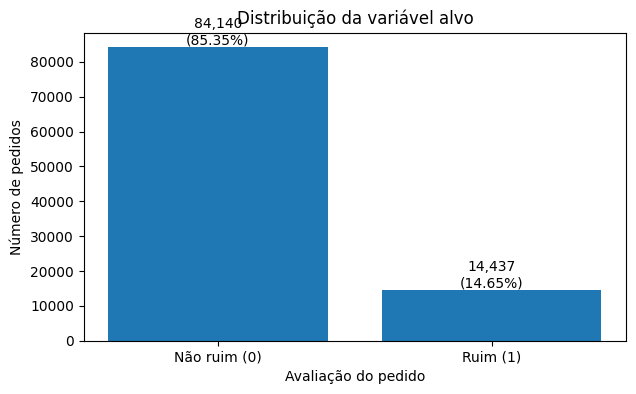

In [15]:
# 4.5 — Distribuição das classes do target

target_counts = reviews_target['bad_review'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(['Não ruim (0)', 'Ruim (1)'], target_counts.values)

plt.title('Distribuição da variável alvo')
plt.ylabel('Número de pedidos')
plt.xlabel('Avaliação do pedido')

for i, value in enumerate(target_counts.values):
    percentage = value / target_counts.sum() * 100
    plt.text(i, value, f'{value:,}\n({percentage:.2f}%)', ha='center', va='bottom')

plt.show()


### Distribuição da variável alvo

Após o tratamento das avaliações múltiplas conflitantes, a base utilizada para construção do target possui 98.577 pedidos únicos.

A classe `bad_review = 1`, correspondente às avaliações de 1 ou 2 estrelas, representa 14,65% dos pedidos, enquanto a classe `bad_review = 0`, correspondente às avaliações de 3 a 5 estrelas, representa 85,35%.

Apesar do desbalanceamento entre as classes, a classe minoritária possui representatividade suficiente para o desenvolvimento de um problema de classificação. Durante a etapa de modelagem, esse desbalanceamento deverá ser considerado na escolha das métricas de avaliação.

## 5. Construção da base consolidada

Como as informações do dataset estão distribuídas em diferentes tabelas, será construída uma base consolidada em nível de pedido.

A unidade de análise será o pedido (`order_id`), portanto cada linha da base final deverá representar um único pedido.

As tabelas que possuem múltiplos registros para um mesmo pedido serão previamente agregadas antes da realização dos merges, evitando a multiplicação artificial de registros.


### 5.1 — Informações dos itens

Agregar os itens por pedido antes da integração.

#### 5.1.1 — Agregação dos itens por pedido

In [16]:
# 5.1.1 — Agregação dos itens por pedido

items_agg = order_items.groupby('order_id').agg(
    item_count=('order_item_id', 'count'),
    unique_products=('product_id', 'nunique'),
    unique_sellers=('seller_id', 'nunique'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum')
).reset_index()

items_agg.head()


,order_id,item_count,unique_products,unique_sellers,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,18.14


#### 5.1.2 — Validação da agregação dos itens

In [17]:
# 5.1.2 — Validação da agregação dos itens

print(f'Dimensões: {items_agg.shape}')
print(f'Pedidos únicos: {items_agg["order_id"].nunique()}')

items_agg.describe().T


Dimensões: (98666, 6)
Pedidos únicos: 98666


,count,mean,std,min,25%,50%,75%,max
item_count,98666.0,1.141731,0.538452,1.00,1.00,1.00,1.00,21.00
unique_products,98666.0,1.038098,0.226456,1.00,1.00,1.00,1.00,8.00
unique_sellers,98666.0,1.013622,0.122297,1.00,1.00,1.00,1.00,5.00
total_price,98666.0,137.754076,210.645145,0.85,45.90,86.90,149.90,13440.00
total_freight,98666.0,22.823562,21.650909,0.00,13.85,17.17,24.04,1794.96


### 5.2 — Informações de pagamento

A tabela `payments` pode conter múltiplos registros associados ao mesmo pedido. Antes de incorporá-la à base consolidada, será analisada a ocorrência de múltiplos pagamentos e as formas de pagamento utilizadas.


#### 5.2.1 — Diagnóstico dos registros de pagamento

In [18]:
# 5.2.1 — Diagnóstico dos registros de pagamento

print(f'Total de registros: {len(payments)}')
print(f'Pedidos únicos: {payments["order_id"].nunique()}')
print(f'Registros adicionais por pedido: {len(payments) - payments["order_id"].nunique()}')

print('\nTipos de pagamento:')
print(payments['payment_type'].value_counts())


Total de registros: 103886
Pedidos únicos: 99440
Registros adicionais por pedido: 4446

Tipos de pagamento:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


#### 5.2.2 — Distribuição da quantidade de pagamentos

In [19]:
# 5.2.2 — Distribuição da quantidade de pagamentos

payments.groupby('order_id').size().value_counts().sort_index()


,count
1,96479
2,2382
3,301
4,108
5,52
6,36
7,28
8,11
9,9
10,5


#### 5.2.3 — Agregação dos pagamentos por pedido

In [20]:
# 5.2.3 — Agregação dos pagamentos por pedido

payments_agg = payments.groupby('order_id').agg(
    payment_count=('payment_sequential', 'count'),
    payment_types_count=('payment_type', 'nunique'),
    max_installments=('payment_installments', 'max'),
    total_payment=('payment_value', 'sum')
).reset_index()

main_payment = (
    payments.sort_values('payment_value', ascending=False)
    .drop_duplicates('order_id')
    [['order_id', 'payment_type']]
    .rename(columns={'payment_type': 'main_payment_type'})
)

payments_agg = payments_agg.merge(main_payment, on='order_id', how='left')

payments_agg.head()


,order_id,payment_count,payment_types_count,max_installments,total_payment,main_payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,2,72.19,credit_card
1,00018f77f2f0320c557190d7a144bdd3,1,1,3,259.83,credit_card
2,000229ec398224ef6ca0657da4fc703e,1,1,5,216.87,credit_card
3,00024acbcdf0a6daa1e931b038114c75,1,1,2,25.78,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,3,218.04,credit_card


#### 5.2.4 — Validação da agregação dos pagamentos

In [21]:
# 5.2.4 — Validação da agregação dos pagamentos

print(f'Dimensões: {payments_agg.shape}')
print(f'Pedidos únicos: {payments_agg["order_id"].nunique()}')

payments_agg.describe().T


Dimensões: (99440, 6)
Pedidos únicos: 99440


,count,mean,std,min,25%,50%,75%,max
payment_count,99440.0,1.044710,0.381166,1.0,1.00,1.00,1.00,29.00
payment_types_count,99440.0,1.022586,0.148582,1.0,1.00,1.00,1.00,2.00
max_installments,99440.0,2.930521,2.715685,0.0,1.00,2.00,4.00,24.00
total_payment,99440.0,160.990267,221.951257,0.0,62.01,105.29,176.97,13664.08


### 5.3 — Consolidação inicial das informações por pedido

A base consolidada será construída utilizando como referência os pedidos que possuem uma variável alvo válida.

As informações de pedidos, itens e pagamentos serão incorporadas mantendo `order_id` como chave e preservando uma única linha para cada pedido.


#### 5.3.1 — Integração inicial das tabelas

In [22]:
# 5.3.1 — Integração inicial das tabelas

df = (
    reviews_target
    .merge(orders, on='order_id', how='left')
    .merge(items_agg, on='order_id', how='left')
    .merge(payments_agg, on='order_id', how='left')
)

print(f'Dimensões da base: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Linhas duplicadas por order_id: {df["order_id"].duplicated().sum()}')

df.head()


Dimensões da base: (98577, 19)
Pedidos únicos: 98577
Linhas duplicadas por order_id: 0


,order_id,bad_review,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,item_count,unique_products,unique_sellers,total_price,total_freight,payment_count,payment_types_count,max_installments,total_payment,main_payment_type
0,73fc7af87114b39712e6da79b0a377eb,0,41dcb106f807e993532d446263290104,delivered,2018-01-11 15:30:49,2018-01-11 15:47:59,2018-01-12 21:57:22,2018-01-17 18:42:41,2018-02-02 00:00:00,2.0,1.0,1.0,370.00,27.26,1.0,1.0,8.0,397.26,credit_card
1,a548910a1c6147796b98fdf73dbeba33,0,8a2e7ef9053dea531e4dc76bd6d853e6,delivered,2018-02-28 12:25:19,2018-02-28 12:48:39,2018-03-02 19:08:15,2018-03-09 23:17:20,2018-03-14 00:00:00,1.0,1.0,1.0,79.79,8.30,1.0,1.0,1.0,88.09,credit_card
2,f9e4b658b201a9f2ecdecbb34bed034b,0,e226dfed6544df5b7b87a48208690feb,delivered,2018-02-03 09:56:22,2018-02-03 10:33:41,2018-02-06 16:18:28,2018-02-16 17:28:48,2018-03-09 00:00:00,1.0,1.0,1.0,149.00,45.12,1.0,1.0,1.0,194.12,credit_card
3,658677c97b385a9be170737859d3511b,0,de6dff97e5f1ba84a3cd9a3bc97df5f6,delivered,2017-04-09 17:41:13,2017-04-09 17:55:19,2017-04-10 14:24:47,2017-04-20 09:08:35,2017-05-10 00:00:00,1.0,1.0,1.0,179.99,42.85,1.0,1.0,1.0,222.84,credit_card
4,8e6bfb81e283fa7e4f11123a3fb894f1,0,5986b333ca0d44534a156a52a8e33a83,delivered,2018-02-10 10:59:03,2018-02-10 15:48:21,2018-02-15 19:36:14,2018-02-28 16:33:35,2018-03-09 00:00:00,1.0,1.0,1.0,1199.00,134.25,1.0,1.0,10.0,1333.25,credit_card


#### 5.3.2 — Diagnóstico dos valores ausentes

In [23]:
# 5.3.2 — Diagnóstico dos valores ausentes

df.isna().sum().sort_values(ascending=False)


,0
order_delivered_customer_date,2833
order_delivered_carrier_date,1740
item_count,755
total_price,755
total_freight,755
unique_sellers,755
unique_products,755
order_approved_at,155
payment_types_count,1
total_payment,1


#### 5.3.3 — Distribuição dos status dos pedidos

order_status
delivered      95746
shipped         1028
canceled         604
unavailable      594
invoiced         306
processing       294
created            3
approved           2
Name: count, dtype: int64

Distribuição percentual:
order_status
delivered      97.13
shipped         1.04
canceled        0.61
unavailable     0.60
invoiced        0.31
processing      0.30
created         0.00
approved        0.00
Name: proportion, dtype: float64


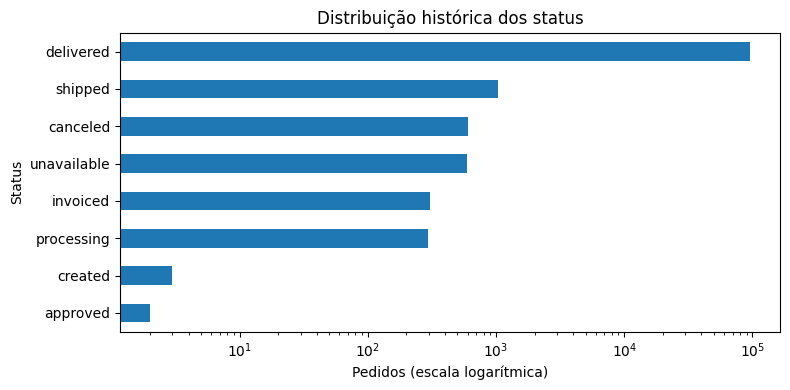

In [24]:
# 5.3.3 — Distribuição dos status dos pedidos

print(df['order_status'].value_counts())

print('\nDistribuição percentual:')
print(df['order_status'].value_counts(normalize=True).mul(100).round(2))


# Visualização da distribuição dos status
ax = df['order_status'].value_counts().sort_values().plot.barh(figsize=(8,4), logx=True)
ax.set(xlabel='Pedidos (escala logarítmica)', ylabel='Status', title='Distribuição histórica dos status')
plt.tight_layout(); plt.show()

#### 5.3.4 — Relação entre status e avaliações negativas

In [25]:
# 5.3.4 — Relação entre status e avaliações negativas

status_review = df.groupby('order_status')['bad_review'].agg(
    pedidos='count',
    avaliacoes_ruins='sum',
    taxa_bad_review='mean'
)

status_review['taxa_bad_review'] = (status_review['taxa_bad_review'] * 100).round(2)

status_review.sort_values('pedidos', ascending=False)


,pedidos,avaliacoes_ruins,taxa_bad_review
order_status,,,
delivered,95746,12225,12.77
shipped,1028,715,69.55
canceled,604,464,76.82
unavailable,594,504,84.85
invoiced,306,253,82.68
processing,294,273,92.86
created,3,2,66.67
approved,2,1,50.00


#### 5.3.5 — Identificação dos pedidos sem itens

In [26]:
# 5.3.5 — Identificação dos pedidos sem itens

missing_items = df[df['item_count'].isna()]

print(f'Pedidos sem informações de itens: {len(missing_items)}')

print('\nStatus dos pedidos sem itens:')
print(missing_items['order_status'].value_counts())

print('\nPercentual de bad_review:')
print(missing_items['bad_review'].value_counts(normalize=True).mul(100).round(2))


Pedidos sem informações de itens: 755

Status dos pedidos sem itens:
order_status
unavailable    588
canceled       161
created          3
invoiced         2
shipped          1
Name: count, dtype: int64

Percentual de bad_review:
bad_review
1    79.47
0    20.53
Name: proportion, dtype: float64


#### 5.3.6 — Análise dos pedidos sem itens por status

In [27]:
# 5.3.6 — Análise dos pedidos sem itens por status

missing_items.groupby('order_status')['bad_review'].agg(
    pedidos='count',
    avaliacoes_ruins='sum',
    taxa_bad_review='mean'
)


,pedidos,avaliacoes_ruins,taxa_bad_review
order_status,,,
canceled,161,96,0.596273
created,3,2,0.666667
invoiced,2,2,1.000000
shipped,1,1,1.000000
unavailable,588,499,0.848639


### Valores ausentes nas informações dos itens

Foram identificados 755 pedidos sem registros correspondentes na tabela `order_items`.

A ausência não ocorre de forma aleatória: 588 desses pedidos possuem status `unavailable` e 161 possuem status `canceled`, representando aproximadamente 99% dos casos sem informações de itens.

Além disso, 79,47% desses pedidos apresentam `bad_review = 1`, indicando forte associação entre a ausência das informações de itens, o desfecho operacional do pedido e a insatisfação do cliente.

Por esse motivo, esses registros não serão removidos automaticamente. O tratamento definitivo será definido posteriormente de acordo com a população escolhida para a modelagem e com a disponibilidade das informações no momento da previsão.

### 5.4 — Informações dos clientes

Incorporar os atributos cadastrais por customer_id.

#### 5.4.1 — Incorporação das informações dos clientes

In [28]:
# 5.4.1 — Incorporação das informações dos clientes

df = df.merge(customers, on='customer_id', how='left')

print(f'Dimensões: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Clientes únicos: {df["customer_unique_id"].nunique()}')

df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']].head()


Dimensões: (98577, 23)
Pedidos únicos: 98577
Clientes únicos: 95348


,customer_id,customer_unique_id,customer_city,customer_state
0,41dcb106f807e993532d446263290104,68a5590b9926689be4e10f4ae2db21a8,osasco,SP
1,8a2e7ef9053dea531e4dc76bd6d853e6,64190b91b656ab8f37eb89b93dc84584,nova odessa,SP
2,e226dfed6544df5b7b87a48208690feb,1d47144362c14e94ccdd213e8ec277d5,santo antonio de jesus,BA
3,de6dff97e5f1ba84a3cd9a3bc97df5f6,c8cf6cb6b838dc7a33ed199b825e8616,gravatal,SC
4,5986b333ca0d44534a156a52a8e33a83,d16000272660a1fef81482ad75ba572a,curitibanos,SC


### 5.5 — Informações dos produtos

Integrar e agregar os atributos dos produtos por pedido.

#### 5.5.1 — Integração de itens e produtos

In [29]:
# 5.5.1 — Integração de itens e produtos

items_products = order_items.merge(products, on='product_id', how='left')

print(f'Dimensões: {items_products.shape}')
items_products.head()


Dimensões: (112650, 15)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


#### 5.5.2 — Diagnóstico dos atributos ausentes dos produtos

In [30]:
# 5.5.2 — Diagnóstico dos atributos ausentes dos produtos

product_cols = [
    'product_category_name',
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

items_products[product_cols].isna().sum()


,0
product_category_name,1603
product_name_lenght,1603
product_description_lenght,1603
product_photos_qty,1603
product_weight_g,18
product_length_cm,18
product_height_cm,18
product_width_cm,18


#### 5.5.3 — Cálculo do volume dos produtos

In [31]:
# 5.5.3 — Cálculo do volume dos produtos

items_products['product_volume_cm3'] = (
    items_products['product_length_cm'] *
    items_products['product_height_cm'] *
    items_products['product_width_cm']
)


#### 5.5.4 — Agregação dos atributos dos produtos

In [32]:
# 5.5.4 — Agregação dos atributos dos produtos

products_agg = items_products.groupby('order_id').agg(
    category_count=('product_category_name', 'nunique'),
    total_weight_g=('product_weight_g', 'sum'),
    max_weight_g=('product_weight_g', 'max'),
    total_volume_cm3=('product_volume_cm3', 'sum'),
    max_volume_cm3=('product_volume_cm3', 'max'),
    avg_photos_qty=('product_photos_qty', 'mean'),
    avg_description_length=('product_description_lenght', 'mean')
).reset_index()

products_agg.head()


,order_id,category_count,total_weight_g,max_weight_g,total_volume_cm3,max_volume_cm3,avg_photos_qty,avg_description_length
0,00010242fe8c5a6d1ba2dd792cb16214,1,650.0,650.0,3528.0,3528.0,4.0,598.0
1,00018f77f2f0320c557190d7a144bdd3,1,30000.0,30000.0,60000.0,60000.0,2.0,239.0
2,000229ec398224ef6ca0657da4fc703e,1,3050.0,3050.0,14157.0,14157.0,2.0,695.0
3,00024acbcdf0a6daa1e931b038114c75,1,200.0,200.0,2400.0,2400.0,1.0,480.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,3750.0,3750.0,42000.0,42000.0,1.0,409.0


#### 5.5.5 — Validação da agregação dos produtos

In [33]:
# 5.5.5 — Validação da agregação dos produtos

print(f'Dimensões: {products_agg.shape}')
print(f'Pedidos únicos: {products_agg["order_id"].nunique()}')

products_agg.describe().T


Dimensões: (98666, 8)
Pedidos únicos: 98666


,count,mean,std,min,25%,50%,75%,max
category_count,98666.0,0.993443,0.147849,0.0,1.0,1.0,1.00,3.0
total_weight_g,98666.0,2390.027669,4773.239825,0.0,300.0,750.0,2066.75,184400.0
max_weight_g,98650.0,2125.098571,3788.981256,0.0,300.0,700.0,1825.00,40425.0
total_volume_cm3,98666.0,17401.430037,30402.167635,0.0,2964.0,7260.0,19872.00,1476000.0
max_volume_cm3,98650.0,15366.969204,23576.251900,168.0,2850.0,6480.0,18711.00,296208.0
avg_photos_qty,97277.0,2.249952,1.740183,1.0,1.0,2.0,3.00,20.0
avg_description_length,97277.0,794.055186,652.985371,4.0,351.0,608.0,996.00,3992.0


#### 5.5.6 — Incorporação dos atributos dos produtos

In [34]:
# 5.5.6 — Incorporação dos atributos dos produtos

df = df.merge(products_agg, on='order_id', how='left')

print(f'Dimensões: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Linhas duplicadas por order_id: {df["order_id"].duplicated().sum()}')


Dimensões: (98577, 30)
Pedidos únicos: 98577
Linhas duplicadas por order_id: 0


### 5.6 — Localização por estado

Investigar a localização relativa dos vendedores e clientes.

#### 5.6.1 — Diagnóstico dos estados dos vendedores

In [35]:
# 5.6.1 — Diagnóstico dos estados dos vendedores

items_sellers = order_items.merge(
    sellers[['seller_id', 'seller_state']],
    on='seller_id',
    how='left'
)

seller_states = items_sellers.groupby('order_id').agg(
    seller_state_count=('seller_state', 'nunique')
).reset_index()

seller_states.describe().T


,count,mean,std,min,25%,50%,75%,max
seller_state_count,98666.0,1.00524,0.073174,1.0,1.0,1.0,1.0,3.0


#### 5.6.2 — Integração das localizações de clientes e vendedores

In [36]:
# 5.6.2 — Integração das localizações de clientes e vendedores

order_customer_state = df[['order_id', 'customer_state']]

items_sellers_location = (
    items_sellers
    .merge(order_customer_state, on='order_id', how='left')
)

items_sellers_location.head()


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_state,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,SP,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,SP,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,MG,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,SP,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,PR,SP


#### 5.6.3 — Identificação de coincidência de estados

In [37]:
# 5.6.3 — Identificação de coincidência de estados

items_sellers_location['same_state'] = (
    items_sellers_location['seller_state'] ==
    items_sellers_location['customer_state']
).astype(int)


#### 5.6.4 — Agregação da coincidência de estados por pedido

In [38]:
# 5.6.4 — Agregação da coincidência de estados por pedido

location_agg = items_sellers_location.groupby('order_id').agg(
    same_state_ratio=('same_state', 'mean')
).reset_index()

location_agg['all_sellers_same_state'] = (
    location_agg['same_state_ratio'] == 1
).astype(int)

location_agg.head()


,order_id,same_state_ratio,all_sellers_same_state
0,00010242fe8c5a6d1ba2dd792cb16214,0.0,0
1,00018f77f2f0320c557190d7a144bdd3,1.0,1
2,000229ec398224ef6ca0657da4fc703e,1.0,1
3,00024acbcdf0a6daa1e931b038114c75,1.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,0.0,0


#### 5.6.5 — Distribuição dos pedidos por coincidência de estados

In [39]:
# 5.6.5 — Distribuição dos pedidos por coincidência de estados

print(location_agg['all_sellers_same_state'].value_counts())

print('\nDistribuição percentual:')
print(
    location_agg['all_sellers_same_state']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


all_sellers_same_state
0    63581
1    35085
Name: count, dtype: int64

Distribuição percentual:
all_sellers_same_state
0    64.44
1    35.56
Name: proportion, dtype: float64


#### 5.6.6 — Incorporação das características de localização

In [40]:
# 5.6.6 — Incorporação das características de localização

df = df.merge(location_agg, on='order_id', how='left')

print(f'Dimensões: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Linhas duplicadas por order_id: {df["order_id"].duplicated().sum()}')


Dimensões: (98577, 32)
Pedidos únicos: 98577
Linhas duplicadas por order_id: 0


### 5.7 — Características geográficas

Estimar distâncias em linha reta a partir dos prefixos de CEP.

#### 5.7.1 — Preparação das coordenadas

#### 5.7.1.1 — Diagnóstico dos prefixos de CEP

In [41]:
# 5.7.1.1 — Diagnóstico dos prefixos de CEP

print(f'Registros: {len(geolocation)}')
print(f'CEPs únicos: {geolocation["geolocation_zip_code_prefix"].nunique()}')
print(f'CEPs duplicados: {geolocation["geolocation_zip_code_prefix"].duplicated().sum()}')

geolocation.head()


Registros: 1000163
CEPs únicos: 19015
CEPs duplicados: 981148


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### 5.7.1.2 — Agregação inicial das coordenadas por CEP

In [42]:
# 5.7.1.2 — Agregação inicial das coordenadas por CEP

geo_agg = geolocation.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'median'),
    lng=('geolocation_lng', 'median')
).reset_index()

print(f'Dimensões: {geo_agg.shape}')
print(f'CEPs únicos: {geo_agg["geolocation_zip_code_prefix"].nunique()}')

geo_agg.head()


Dimensões: (19015, 3)
CEPs únicos: 19015


,geolocation_zip_code_prefix,lat,lng
0,1001,-23.550381,-46.634027
1,1002,-23.548551,-46.635072
2,1003,-23.548977,-46.635313
3,1004,-23.549535,-46.634771
4,1005,-23.549612,-46.636532


#### 5.7.1.3 — Verificação da cobertura geográfica

In [43]:
# 5.7.1.3 — Verificação da cobertura geográfica

customer_geo_coverage = customers['customer_zip_code_prefix'].isin(
    geo_agg['geolocation_zip_code_prefix']
).mean() * 100

seller_geo_coverage = sellers['seller_zip_code_prefix'].isin(
    geo_agg['geolocation_zip_code_prefix']
).mean() * 100

print(f'Cobertura dos CEPs dos clientes: {customer_geo_coverage:.2f}%')
print(f'Cobertura dos CEPs dos vendedores: {seller_geo_coverage:.2f}%')


Cobertura dos CEPs dos clientes: 99.72%
Cobertura dos CEPs dos vendedores: 99.77%


#### 5.7.1.4 — Associação das coordenadas aos clientes e vendedores

In [44]:
# 5.7.1.4 — Associação das coordenadas aos clientes e vendedores

customers_geo = customers.merge(
    geo_agg,
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
).rename(columns={
    'lat': 'customer_lat',
    'lng': 'customer_lng'
})

sellers_geo = sellers.merge(
    geo_agg,
    left_on='seller_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
).rename(columns={
    'lat': 'seller_lat',
    'lng': 'seller_lng'
})


#### 5.7.2 — Cálculo inicial das distâncias

#### 5.7.2.1 — Construção das combinações pedido-vendedor

In [45]:
# 5.7.2.1 — Construção das combinações pedido-vendedor

order_locations = (
    order_items[['order_id', 'seller_id']]
    .drop_duplicates()
    .merge(orders[['order_id', 'customer_id']], on='order_id', how='left')
    .merge(
        customers_geo[['customer_id', 'customer_lat', 'customer_lng']],
        on='customer_id',
        how='left'
    )
    .merge(
        sellers_geo[['seller_id', 'seller_lat', 'seller_lng']],
        on='seller_id',
        how='left'
    )
)

order_locations.head()


,order_id,seller_id,customer_id,customer_lat,customer_lng,seller_lat,seller_lng
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,3ce436f183e68e07877b285a838db11a,-21.762829,-41.310605,-22.498419,-44.125272
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,f6dd3ec061db4e3987629fe6b26e5cce,-20.205737,-50.926924,-23.564289,-46.519045
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,6489ae5e4333f3693df5ad4372dab6d3,-19.870383,-44.594355,-22.271648,-46.165556
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,d4eb9395c8c0431ee92fce09860c5a06,-23.104346,-46.595589,-20.554951,-47.387691
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,58dbd0b2d70206bf40e62cd34e84d795,-23.245512,-46.825182,-22.930408,-53.136438


#### 5.7.2.2 — Diagnóstico das coordenadas ausentes

In [46]:
# 5.7.2.2 — Diagnóstico das coordenadas ausentes

print(f'Combinações pedido-vendedor: {len(order_locations)}')

print('\nCoordenadas ausentes:')
print(
    order_locations[
        ['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng']
    ].isna().sum()
)


Combinações pedido-vendedor: 100010

Coordenadas ausentes:
customer_lat    280
customer_lng    280
seller_lat      220
seller_lng      220
dtype: int64


#### 5.7.2.3 — Definição da função de distância de Haversine

In [47]:
# 5.7.2.3 — Definição da função de distância de Haversine

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


#### 5.7.2.4 — Cálculo inicial das distâncias

In [48]:
# 5.7.2.4 — Cálculo inicial das distâncias

order_locations['distance_km'] = haversine(
    order_locations['customer_lat'],
    order_locations['customer_lng'],
    order_locations['seller_lat'],
    order_locations['seller_lng']
)

order_locations['distance_km'].describe()


,distance_km
count,99511.000000
mean,601.051429
std,594.494718
min,0.000000
25%,186.367130
50%,433.760315
75%,798.585210
max,8677.859564


### 5.7.3 — Verificação de distâncias extremas

Antes de incorporar a distância geográfica à base consolidada, serão analisados os maiores valores encontrados.

Essa verificação tem como objetivo identificar possíveis coordenadas geográficas inconsistentes ou valores extremos que possam distorcer a característica criada.


#### 5.7.3.1 — Inspeção das maiores distâncias

In [49]:
# 5.7.3.1 — Inspeção das maiores distâncias

order_locations.nlargest(20, 'distance_km')[
    [
        'order_id',
        'customer_lat',
        'customer_lng',
        'seller_lat',
        'seller_lng',
        'distance_km'
    ]
]


,order_id,customer_lat,customer_lng,seller_lat,seller_lng,distance_km
54032,8ad3f1d0f96992e43566c4c82c9f6c58,42.184003,-8.723762,-26.231306,-49.412569,8677.859564
30282,4d5abe7999d76d1fb6237d3677706af0,41.146203,-8.577855,-21.258652,-47.813946,8032.929717
67288,acdbc7396e191931c263db11af241d62,41.146203,-8.577855,-21.258652,-47.813946,8032.929717
53507,897ec6416d50126a9061626f0fc2d658,13.001420,-23.583939,-23.652443,-46.755492,4791.606339
30947,4f1583d080fe1eec5e509335d79b17c6,0.916934,-69.569797,-23.523266,-46.194662,3710.405887
91285,e9874f4e48ede77b6b9d785ac3755445,2.821374,-60.672241,-27.152532,-48.504648,3579.339684
60333,9b790ca446b8e28ce5e4382959f6b7df,2.816664,-60.756890,-25.670988,-49.327268,3398.485605
15709,2889d7816934298a0f5a4a30ef3ffbc7,2.808802,-60.680341,-25.543616,-49.182293,3387.314437
92510,ecab90c9933c58908d3d6add7c6f5ae3,2.816664,-60.756890,-25.499689,-49.334712,3380.655451
74323,be5cae366c82f548c9a28b353ab44dd0,2.835110,-60.671952,-25.459870,-49.230955,3379.238259


#### 5.7.3.2 — Contagem de distâncias extremas

In [50]:
# 5.7.3.2 — Contagem de distâncias extremas

print(f'Distâncias acima de 2.000 km: {(order_locations["distance_km"] > 2000).sum()}')
print(f'Distâncias acima de 3.000 km: {(order_locations["distance_km"] > 3000).sum()}')
print(f'Distâncias acima de 5.000 km: {(order_locations["distance_km"] > 5000).sum()}')


Distâncias acima de 2.000 km: 5838
Distâncias acima de 3.000 km: 144
Distâncias acima de 5.000 km: 3


### 5.7.4 — Verificação das coordenadas geográficas

A análise das maiores distâncias identificou coordenadas que podem estar fora dos limites geográficos esperados para o Brasil.

Antes de realizar qualquer tratamento de valores extremos, serão verificadas as coordenadas utilizadas no cálculo, permitindo distinguir distâncias geograficamente plausíveis de possíveis inconsistências na base de geolocalização.


#### 5.7.4 — Diagnóstico das coordenadas geográficas

In [51]:
# 5.7.4 — Diagnóstico das coordenadas geográficas

print('Latitude dos clientes:')
print(order_locations['customer_lat'].describe())

print('\nLongitude dos clientes:')
print(order_locations['customer_lng'].describe())

print('\nLatitude dos vendedores:')
print(order_locations['seller_lat'].describe())

print('\nLongitude dos vendedores:')
print(order_locations['seller_lng'].describe())


Latitude dos clientes:
count    99730.000000
mean       -21.198131
std          5.606015
min        -33.690972
25%        -23.589533
50%        -22.925419
75%        -20.140685
max         42.184003
Name: customer_lat, dtype: float64

Longitude dos clientes:
count    99730.000000
mean       -46.177604
std          4.055882
min        -72.670987
25%        -48.106412
50%        -46.631068
75%        -43.600962
max         -8.577855
Name: customer_lng, dtype: float64

Latitude dos vendedores:
count    99790.000000
mean       -22.795787
std          2.743068
min        -32.074657
25%        -23.613259
50%        -23.421460
75%        -21.757690
max         -2.498944
Name: seller_lat, dtype: float64

Longitude dos vendedores:
count    99790.000000
mean       -47.226819
std          2.349797
min        -67.811160
25%        -48.805319
50%        -46.755492
75%        -46.520229
max        -34.855123
Name: seller_lng, dtype: float64


### 5.7.5 — Identificação das coordenadas inconsistentes

A análise das coordenadas revelou valores geográficos incompatíveis com a localização esperada dos clientes no Brasil.

Em vez de remover distâncias elevadas de forma arbitrária, serão identificados os registros responsáveis pelas coordenadas inconsistentes. Dessa forma, o tratamento será realizado sobre a origem do problema, preservando distâncias longas que sejam geograficamente plausíveis.


#### 5.7.5 — Identificação dos registros inconsistentes

In [52]:
# 5.7.5 — Identificação dos registros inconsistentes

order_locations_check = order_locations.merge(
    customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']],
    on='customer_id',
    how='left'
)

order_locations_check.nlargest(10, 'customer_lat')[
    [
        'order_id',
        'customer_zip_code_prefix',
        'customer_state',
        'customer_lat',
        'customer_lng',
        'distance_km'
    ]
]


,order_id,customer_zip_code_prefix,customer_state,customer_lat,customer_lng,distance_km
54032,8ad3f1d0f96992e43566c4c82c9f6c58,83252,PR,42.184003,-8.723762,8677.859564
30282,4d5abe7999d76d1fb6237d3677706af0,68275,PA,41.146203,-8.577855,8032.929717
67288,acdbc7396e191931c263db11af241d62,68275,PA,41.146203,-8.577855,8032.929717
53507,897ec6416d50126a9061626f0fc2d658,46560,BA,13.001420,-23.583939,4791.606339
84754,d8a3a8c458243721ca285392ac882c78,68980,AP,3.844931,-51.833917,3091.873191
71135,b67e88a088df905cb07564cd720a9711,69380,RR,3.361347,-59.833975,3094.761418
8793,16a73b59c868ed5c7152b96b0ebc7693,69307,RR,2.858078,-60.661003,2899.451214
12055,1eeaec28c1a699b3b423fba26109e197,69307,RR,2.858078,-60.661003,3301.334598
13400,2268107fccbaa5d8b921f82146286350,69307,RR,2.858078,-60.661003,3173.552070
62968,a20191650d84d1d59f72139a87207a3b,69307,RR,2.858078,-60.661003,3310.632619


### 5.7.6 — Investigação dos prefixos de CEP com coordenadas inconsistentes

Os maiores valores de distância foram associados a prefixos de CEP cujas coordenadas agregadas não são compatíveis com o estado informado do cliente.

Para verificar a origem da inconsistência, serão analisados os registros originais da tabela de geolocalização correspondentes a esses prefixos de CEP.


#### 5.7.6.1 — Inspeção dos CEPs problemáticos

In [53]:
# 5.7.6.1 — Inspeção dos CEPs problemáticos

problematic_zips = [83252, 68275, 46560]

geolocation[
    geolocation['geolocation_zip_code_prefix'].isin(problematic_zips)
].sort_values(
    ['geolocation_zip_code_prefix', 'geolocation_lat']
)[
    [
        'geolocation_zip_code_prefix',
        'geolocation_lat',
        'geolocation_lng',
        'geolocation_city',
        'geolocation_state'
    ]
]


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
696987,46560,-12.989122,-42.220055,ibiajara,BA
697048,46560,38.991963,-4.947823,ibiajara,BA
769368,68275,-1.743515,-52.244163,porto trombetas,PA
769356,68275,-1.743457,-52.244269,porto trombetas,PA
769414,68275,-1.743457,-52.244269,porto trombetas,PA
769464,68275,-1.472765,-56.378018,oriximina,PA
769333,68275,41.146203,-8.577855,porto trombetas,PA
769351,68275,42.166805,-6.898531,porto trombetas,PA
769391,68275,42.167251,-6.898559,porto trombetas,PA
769436,68275,42.167251,-6.898559,porto trombetas,PA


#### 5.7.6.2 — Identificação de coordenadas fora dos limites

In [54]:
# 5.7.6.2 — Identificação de coordenadas fora dos limites

geo_suspicious = geolocation[
    (geolocation['geolocation_lat'] > 6) |
    (geolocation['geolocation_lat'] < -34) |
    (geolocation['geolocation_lng'] > -34) |
    (geolocation['geolocation_lng'] < -74)
]

print(f'Registros geográficos suspeitos: {len(geo_suspicious)}')
print(f'Percentual da base: {len(geo_suspicious) / len(geolocation) * 100:.4f}%')

geo_suspicious[
    ['geolocation_zip_code_prefix', 'geolocation_lat',
     'geolocation_lng', 'geolocation_city', 'geolocation_state']
].head(20)


Registros geográficos suspeitos: 42
Percentual da base: 0.0042%


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


### 5.7.7 — Tratamento das inconsistências geográficas

A investigação dos prefixos de CEP associados às maiores distâncias revelou a presença de coordenadas incompatíveis com a localização informada dos clientes.

Também foi observado que a utilização da mediana por prefixo de CEP não elimina necessariamente esse problema. Em alguns casos, existem poucos registros para o mesmo CEP ou a maioria das coordenadas disponíveis apresenta inconsistências, fazendo com que a coordenada agregada também permaneça incorreta.

Por esse motivo, antes de recalcular as coordenadas representativas dos prefixos de CEP, será realizada uma verificação dos registros geográficos potencialmente incompatíveis com o território brasileiro.

Nesta etapa, os limites geográficos serão utilizados apenas como critério diagnóstico. Nenhum registro será removido antes da análise dos casos identificados.


#### 5.7.7.1 — Diagnóstico dos registros geográficos suspeitos

In [55]:
# 5.7.7.1 — Diagnóstico dos registros geográficos suspeitos

geo_suspicious = geolocation[
    (geolocation['geolocation_lat'] > 6) |
    (geolocation['geolocation_lat'] < -34) |
    (geolocation['geolocation_lng'] > -34) |
    (geolocation['geolocation_lng'] < -74)
]

print(f'Registros geográficos suspeitos: {len(geo_suspicious)}')
print(f'Percentual da base: {len(geo_suspicious) / len(geolocation) * 100:.4f}%')

geo_suspicious[
    ['geolocation_zip_code_prefix', 'geolocation_lat',
     'geolocation_lng', 'geolocation_city', 'geolocation_state']
].head(20)


Registros geográficos suspeitos: 42
Percentual da base: 0.0042%


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


#### 5.7.7.2 — Quantificação dos CEPs suspeitos

In [56]:
# 5.7.7.2 — Quantificação dos CEPs suspeitos

print(f'CEPs suspeitos únicos: {geo_suspicious["geolocation_zip_code_prefix"].nunique()}')

print('\nRegistros suspeitos por estado:')
print(
    geo_suspicious['geolocation_state']
    .value_counts()
    .sort_values(ascending=False)
)


CEPs suspeitos únicos: 21

Registros suspeitos por estado:
geolocation_state
PE    11
PA     7
RJ     5
RS     4
BA     4
PR     3
ES     2
MG     2
SP     1
AL     1
PB     1
MT     1
Name: count, dtype: int64


#### 5.7.7.3 — Distribuição dos registros suspeitos por CEP e estado

In [57]:
# 5.7.7.3 — Distribuição dos registros suspeitos por CEP e estado

geo_suspicious.groupby(
    ['geolocation_zip_code_prefix', 'geolocation_state']
).size().reset_index(name='records')


,geolocation_zip_code_prefix,geolocation_state,records
0,18243,SP,1
1,28155,RJ,2
2,28165,RJ,1
3,28333,RJ,1
4,28595,RJ,1
5,29654,ES,2
6,35179,MG,2
7,45936,BA,2
8,46560,BA,1
9,47310,BA,1


### 5.7.8 — Validação das coordenadas agregadas por estado

A análise anterior identificou poucos prefixos de CEP com coordenadas potencialmente inconsistentes. Entretanto, alguns casos sinalizados pelo filtro geográfico correspondem a localizações válidas, como regiões insulares.

Para evitar a remoção arbitrária de coordenadas, será realizada uma comparação entre cada coordenada agregada por CEP e a distribuição das coordenadas observadas dentro do respectivo estado.

Essa abordagem permite identificar coordenadas extremamente distantes do padrão geográfico do próprio estado, preservando localizações legítimas que estejam próximas aos limites territoriais do Brasil.


#### 5.7.8 — Cálculo dos centros representativos dos estados

In [58]:
# 5.7.8 — Cálculo dos centros representativos dos estados

state_geo = geolocation.groupby('geolocation_state').agg(
    state_lat=('geolocation_lat', 'median'),
    state_lng=('geolocation_lng', 'median')
).reset_index()

state_geo


,geolocation_state,state_lat,state_lng
0,AC,-9.962046,-67.830638
1,AL,-9.636914,-35.754053
2,AM,-3.089704,-60.011998
3,AP,0.031212,-51.074329
4,BA,-12.956328,-38.957697
5,CE,-3.789734,-38.585162
6,DF,-15.817696,-47.939322
7,ES,-20.294495,-40.320785
8,GO,-16.682929,-49.265681
9,MA,-3.288063,-44.298288


### 5.7.9 — Distância da coordenada do CEP ao centro do estado

Os centros geográficos representativos dos estados apresentaram coordenadas coerentes.

Como etapa final de validação, será calculada a distância entre a coordenada agregada de cada prefixo de CEP e o centro representativo do respectivo estado.

O objetivo é identificar coordenadas extremamente afastadas da distribuição geográfica esperada para o estado, diferenciando possíveis inconsistências de distâncias legítimas entre clientes e vendedores.


#### 5.7.9.1 — Associação dos CEPs aos estados

In [59]:
# 5.7.9.1 — Associação dos CEPs aos estados

zip_state = (
    geolocation.groupby('geolocation_zip_code_prefix')['geolocation_state']
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

geo_check = (
    geo_agg
    .merge(zip_state, on='geolocation_zip_code_prefix', how='left')
    .merge(state_geo, on='geolocation_state', how='left')
)

geo_check.head()


,geolocation_zip_code_prefix,lat,lng,geolocation_state,state_lat,state_lng
0,1001,-23.550381,-46.634027,SP,-23.525004,-46.68772
1,1002,-23.548551,-46.635072,SP,-23.525004,-46.68772
2,1003,-23.548977,-46.635313,SP,-23.525004,-46.68772
3,1004,-23.549535,-46.634771,SP,-23.525004,-46.68772
4,1005,-23.549612,-46.636532,SP,-23.525004,-46.68772


#### 5.7.9.2 — Cálculo da distância ao centro do estado

In [60]:
# 5.7.9.2 — Cálculo da distância ao centro do estado

geo_check['distance_to_state_center_km'] = haversine(
    geo_check['lat'],
    geo_check['lng'],
    geo_check['state_lat'],
    geo_check['state_lng']
)

geo_check['distance_to_state_center_km'].describe()


,distance_to_state_center_km
count,19015.000000
mean,133.113274
std,238.776544
min,0.109338
25%,14.896839
50%,59.503071
75%,208.472335
max,18151.076237


#### 5.7.9.3 — Inspeção dos maiores desvios geográficos

In [61]:
# 5.7.9.3 — Inspeção dos maiores desvios geográficos

geo_check.nlargest(20, 'distance_to_state_center_km')[
    [
        'geolocation_zip_code_prefix',
        'geolocation_state',
        'lat',
        'lng',
        'state_lat',
        'state_lng',
        'distance_to_state_center_km'
    ]
]


,geolocation_zip_code_prefix,geolocation_state,lat,lng,state_lat,state_lng,distance_to_state_center_km
18309,95130,RS,14.585073,121.105394,-29.795425,-51.249408,18151.076237
16419,83252,PR,42.184003,-8.723762,-25.384058,-50.618097,8656.611068
15781,78131,MT,38.816816,-9.394625,-15.244524,-56.039189,7720.847077
6077,18243,SP,28.008978,-15.536867,-23.525004,-46.687720,6632.430135
13734,68275,PA,41.146203,-8.577855,-1.462833,-48.484188,6215.621190
7964,29654,ES,0.916934,-69.569797,-20.294495,-40.320785,3963.076097
10691,46560,BA,13.001420,-23.583939,-12.956328,-38.957697,3347.125619
13927,68985,AP,-26.404508,-52.352504,0.031212,-51.074329,2942.705648
8029,29925,ES,-3.107535,-60.038222,-20.294495,-40.320785,2867.139485
13748,68379,PA,9.049063,-25.170903,-1.462833,-48.484188,2835.043662


### 5.7.10 — Tratamento final das coordenadas inconsistentes

Validar cada coordenada original contra a malha estadual oficial do IBGE (API de malhas, resolução intermediária). A distância ao centro é apenas diagnóstica. Pontos fora da UF declarada são descartados; limites simplificados podem excluir pontos próximos à fronteira. A agregação será por CEP e UF, e a mediana também será validada. Sem coordenada válida, manter ausência. Não há garantia de precisão municipal ou de endereço.

#### 5.7.10.1 — Filtragem das coordenadas inconsistentes

In [62]:
# 5.7.10.1 — Filtragem das coordenadas inconsistentes
uf_codes = dict(zip([11,12,13,14,15,16,17,21,22,23,24,25,26,27,28,29,31,32,33,35,41,42,43,50,51,52,53],
                    'RO AC AM RR PA AP TO MA PI CE RN PB PE AL SE BA MG ES RJ SP PR SC RS MS MT GO DF'.split()))
url = 'https://servicodados.ibge.gov.br/api/v3/malhas/paises/BR'
response = requests.get(url, params={'formato':'application/vnd.geo+json','qualidade':'intermediaria','intrarregiao':'UF'}, timeout=120)
response.raise_for_status()
uf_shapes = {uf_codes[int(f['properties']['codarea'])]: shape(f['geometry']) for f in response.json()['features']}
assert set(uf_shapes) == set(uf_codes.values()), 'Malha estadual incompleta'
def valid_uf(frame, state, lat, lng):
    valid = pd.Series(False, index=frame.index)
    for uf, group in frame.groupby(state):
        if uf in uf_shapes:
            valid.loc[group.index] = intersects_xy(uf_shapes[uf], group[lng].to_numpy(), group[lat].to_numpy())
    return valid
geo_clean = geolocation.loc[valid_uf(geolocation, 'geolocation_state', 'geolocation_lat', 'geolocation_lng')].copy()
print(f'Registros originais: {len(geolocation):,}')
print(f'Registros após filtro estadual: {len(geo_clean):,}')
print(f'Registros removidos: {len(geolocation)-len(geo_clean):,}')

Registros originais: 1,000,163
Registros após filtro estadual: 987,211
Registros removidos: 12,952


#### 5.7.10.2 — Reconstrução das coordenadas agregadas

In [63]:
# 5.7.10.2 — Reconstrução das coordenadas agregadas
geo_keys = ['geolocation_zip_code_prefix', 'geolocation_state']
geo_agg_clean = geo_clean.groupby(geo_keys).agg(lat=('geolocation_lat','median'), lng=('geolocation_lng','median')).reset_index()
# Uma mediana pode cair fora de um polígono não convexo: manter ausência nesses casos.
geo_agg_clean = geo_agg_clean.loc[valid_uf(geo_agg_clean,'geolocation_state','lat','lng')].copy()
assert not geo_agg_clean.duplicated(geo_keys).any()
print('CEPs antes:', len(geo_agg))
print('CEPs após:', geo_agg_clean[geo_keys[0]].nunique())

CEPs antes: 19015
CEPs após: 18943


#### 5.7.10.3 — Verificação dos CEPs após o tratamento

In [64]:
# 5.7.10.3 — Verificação dos CEPs após o tratamento
check_zips = [83252, 68275, 46560, 29925, 70393, 70910, 68985, 53990]
display(geo_agg_clean.loc[geo_agg_clean[geo_keys[0]].isin(check_zips)])
assert valid_uf(geo_agg_clean,'geolocation_state','lat','lng').all()

,geolocation_zip_code_prefix,geolocation_state,lat,lng
8003,29925,ES,-19.122500,-40.360280
10653,46560,BA,-12.989122,-42.220055
11225,53990,PE,-3.853092,-32.423525
13681,68275,PA,-1.743457,-52.244269
13872,68985,AP,3.816170,-51.863185


### 5.7.11 — Recálculo da distância geográfica

Após o tratamento das inconsistências identificadas na tabela de geolocalização, as coordenadas representativas dos prefixos de CEP serão recalculadas utilizando apenas os registros considerados válidos.

Em seguida, será recalculada a distância aproximada entre clientes e vendedores. Os casos em que não houver coordenadas válidas permanecerão como valores ausentes, evitando a criação artificial de localizações.

Por fim, as distâncias serão agregadas por pedido para manter a estrutura de uma linha por `order_id`.


#### 5.7.11.1 — Atualização das coordenadas dos clientes e vendedores

In [65]:
# 5.7.11.1 — Atualização das coordenadas dos clientes e vendedores

customers_geo_clean = customers.merge(
    geo_agg_clean,
    left_on=['customer_zip_code_prefix', 'customer_state'],
    right_on=geo_keys,
    validate='many_to_one',
    how='left'
).rename(columns={
    'lat': 'customer_lat',
    'lng': 'customer_lng'
})

sellers_geo_clean = sellers.merge(
    geo_agg_clean,
    left_on=['seller_zip_code_prefix', 'seller_state'],
    right_on=geo_keys,
    validate='many_to_one',
    how='left'
).rename(columns={
    'lat': 'seller_lat',
    'lng': 'seller_lng'
})


#### 5.7.11.2 — Recálculo das distâncias entre clientes e vendedores

In [66]:
# 5.7.11.2 — Recálculo das distâncias entre clientes e vendedores

order_locations_clean = (
    order_items[['order_id', 'seller_id']]
    .drop_duplicates()
    .merge(orders[['order_id', 'customer_id']], on='order_id', how='left')
    .merge(
        customers_geo_clean[['customer_id', 'customer_lat', 'customer_lng']],
        on='customer_id',
        how='left'
    )
    .merge(
        sellers_geo_clean[['seller_id', 'seller_lat', 'seller_lng']],
        on='seller_id',
        how='left'
    )
)

order_locations_clean['distance_km'] = haversine(
    order_locations_clean['customer_lat'],
    order_locations_clean['customer_lng'],
    order_locations_clean['seller_lat'],
    order_locations_clean['seller_lng']
)


#### 5.7.11.3 — Validação das distâncias recalculadas

In [67]:
# 5.7.11.3 — Validação das distâncias recalculadas

print('Coordenadas ausentes:')
print(
    order_locations_clean[
        ['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng']
    ].isna().sum()
)

print('\nDistância:')
print(order_locations_clean['distance_km'].describe())

print(f'\nDistâncias acima de 5.000 km: {(order_locations_clean["distance_km"] > 5000).sum()}')


Coordenadas ausentes:
customer_lat    500
customer_lng    500
seller_lat      813
seller_lng      813
dtype: int64

Distância:
count    98698.000000
mean       600.521189
std        593.550759
min          0.000000
25%        183.230389
50%        433.186391
75%        798.131290
max       3579.239278
Name: distance_km, dtype: float64

Distâncias acima de 5.000 km: 0


### 5.7.12 — Agregação das distâncias por pedido

Como um mesmo pedido pode envolver mais de um vendedor, a distância entre cliente e vendedor pode apresentar mais de um valor para o mesmo `order_id`.

Para preservar a estrutura de uma linha por pedido, as distâncias serão agregadas utilizando a distância média e a maior distância observada entre o cliente e os vendedores envolvidos.

A distância média representa o comportamento geral do pedido, enquanto a distância máxima permite representar o vendedor geograficamente mais distante do cliente.


#### 5.7.12 — Agregação das distâncias por pedido

In [68]:
# 5.7.12 — Agregação das distâncias por pedido

distance_agg = order_locations_clean.groupby('order_id').agg(
    avg_distance_km=('distance_km', 'mean'),
    max_distance_km=('distance_km', 'max')
).reset_index()

print(f'Dimensões: {distance_agg.shape}')
print(f'Pedidos únicos: {distance_agg["order_id"].nunique()}')

distance_agg.describe().T


Dimensões: (98666, 3)
Pedidos únicos: 98666


,count,mean,std,min,25%,50%,75%,max
avg_distance_km,97382.0,601.056642,594.351037,0.0,183.526833,433.257992,797.706373,3579.239278
max_distance_km,97382.0,602.340479,594.818230,0.0,185.221708,434.761725,800.397392,3579.239278


### 5.7.13 — Incorporação das características geográficas

As características de localização construídas serão incorporadas à base consolidada utilizando `order_id` como chave.

Após o merge, será verificado se a base continua mantendo uma única linha por pedido, garantindo que a agregação das diferentes fontes de dados não tenha introduzido duplicações.


#### 5.7.13 — Incorporação das características geográficas

In [69]:
# 5.7.13 — Incorporação das características geográficas

df = df.merge(distance_agg, on='order_id', how='left')

print(f'Dimensões: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Linhas duplicadas por order_id: {df["order_id"].duplicated().sum()}')


Dimensões: (98577, 34)
Pedidos únicos: 98577
Linhas duplicadas por order_id: 0


### 5.8 Verificação da base consolidada

Após a integração das informações de pedidos, avaliações, itens, pagamentos, clientes, produtos, vendedores e localização geográfica, será realizada uma verificação geral da base consolidada.

O objetivo é confirmar sua estrutura, identificar valores ausentes e revisar as variáveis disponíveis antes de avançar para as próximas etapas de preparação dos dados.

Essa verificação também permitirá distinguir variáveis que poderão ser utilizadas na modelagem daquelas destinadas apenas à análise exploratória ou que representam informações indisponíveis no momento da previsão.

In [70]:
# 5.8.1 — Estrutura atual da base

print(f'Dimensões: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Colunas: {df.shape[1]}')

df.info()


Dimensões: (98577, 34)
Pedidos únicos: 98577
Colunas: 34
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98577 entries, 0 to 98576
Data columns (total 34 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       98577 non-null  object 
 1   bad_review                     98577 non-null  int64  
 2   customer_id                    98577 non-null  object 
 3   order_status                   98577 non-null  object 
 4   order_purchase_timestamp       98577 non-null  object 
 5   order_approved_at              98422 non-null  object 
 6   order_delivered_carrier_date   96837 non-null  object 
 7   order_delivered_customer_date  95744 non-null  object 
 8   order_estimated_delivery_date  98577 non-null  object 
 9   item_count                     97822 non-null  float64
 10  unique_products                97822 non-null  float64
 11  unique_sellers                 97822 non-null  fl

In [71]:
# 5.8.2 — Verificação dos valores ausentes

missing_df = (
    df.isna().sum()
    .to_frame('missing')
    .assign(percent=lambda x: (x['missing'] / len(df) * 100).round(2))
    .sort_values('missing', ascending=False)
)

missing_df[missing_df['missing'] > 0]


,missing,percent
order_delivered_customer_date,2833,2.87
avg_photos_qty,2131,2.16
avg_description_length,2131,2.16
max_distance_km,2031,2.06
avg_distance_km,2031,2.06
order_delivered_carrier_date,1740,1.77
max_volume_cm3,771,0.78
max_weight_g,771,0.78
same_state_ratio,755,0.77
total_volume_cm3,755,0.77


In [72]:
# 5.8.3 — Lista das variáveis da base consolidada

for i, column in enumerate(df.columns, 1):
    print(f'{i:02d}. {column}')


01. order_id
02. bad_review
03. customer_id
04. order_status
05. order_purchase_timestamp
06. order_approved_at
07. order_delivered_carrier_date
08. order_delivered_customer_date
09. order_estimated_delivery_date
10. item_count
11. unique_products
12. unique_sellers
13. total_price
14. total_freight
15. payment_count
16. payment_types_count
17. max_installments
18. total_payment
19. main_payment_type
20. customer_unique_id
21. customer_zip_code_prefix
22. customer_city
23. customer_state
24. category_count
25. total_weight_g
26. max_weight_g
27. total_volume_cm3
28. max_volume_cm3
29. avg_photos_qty
30. avg_description_length
31. same_state_ratio
32. all_sellers_same_state
33. avg_distance_km
34. max_distance_km


### 5.9 Classificação das variáveis e prevenção de data leakage

Antes da modelagem, as variáveis da base serão classificadas de acordo com sua disponibilidade no momento em que a previsão deverá ser realizada.

O objetivo do modelo é identificar antecipadamente pedidos com maior risco de receber uma avaliação ruim. Portanto, informações conhecidas somente após o processamento, envio ou entrega do pedido não poderão ser utilizadas como preditores, mesmo que apresentem forte relação com a avaliação do cliente.

As variáveis serão separadas em três grupos:

- **Features candidatas:** informações disponíveis no momento da previsão e potencialmente úteis para o modelo.
- **Identificadores ou variáveis auxiliares:** informações úteis para relacionar registros, realizar análises ou controlar a divisão dos dados, mas que não devem ser utilizadas diretamente como preditores.
- **Informações futuras (data leakage):** variáveis geradas após o momento definido para a previsão e que, portanto, não estarão disponíveis para o modelo em uma aplicação real.

> **Escopo da exploração:** as análises descritivas desta seção utilizam a base histórica completa. Como algumas decisões de atributos foram tomadas após essa exploração, a avaliação posterior é retrospectiva e não estritamente independente.

In [73]:
# 5.9.1 — Classificação inicial das variáveis

target = 'bad_review'

id_cols = [
    'order_id',
    'customer_id',
    'customer_unique_id'
]

leakage_cols = [
    'order_status',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

candidate_features = [
    col for col in df.columns
    if col not in [target] + id_cols + leakage_cols
]

print(f'Target: {target}')
print(f'Identificadores/auxiliares: {len(id_cols)}')
print(f'Variáveis com leakage: {len(leakage_cols)}')
print(f'Features candidatas: {len(candidate_features)}')

print('\nFeatures candidatas:')
for i, col in enumerate(candidate_features, 1):
    print(f'{i:02d}. {col}')


Target: bad_review
Identificadores/auxiliares: 3
Variáveis com leakage: 3
Features candidatas: 27

Features candidatas:
01. order_purchase_timestamp
02. order_approved_at
03. order_estimated_delivery_date
04. item_count
05. unique_products
06. unique_sellers
07. total_price
08. total_freight
09. payment_count
10. payment_types_count
11. max_installments
12. total_payment
13. main_payment_type
14. customer_zip_code_prefix
15. customer_city
16. customer_state
17. category_count
18. total_weight_g
19. max_weight_g
20. total_volume_cm3
21. max_volume_cm3
22. avg_photos_qty
23. avg_description_length
24. same_state_ratio
25. all_sellers_same_state
26. avg_distance_km
27. max_distance_km


### 5.9.2 Análise inicial de redundância entre as features

Após a classificação das variáveis disponíveis no momento da previsão, será realizada uma análise inicial de possíveis redundâncias entre as features candidatas.

Algumas características foram construídas a partir das mesmas informações originais e podem apresentar comportamento muito semelhante. Manter variáveis altamente redundantes pode aumentar desnecessariamente a complexidade da base sem acrescentar informação relevante ao modelo.

Nesta etapa, as variáveis não serão removidas automaticamente. A análise será utilizada para orientar posteriormente a seleção das features que serão mantidas para a modelagem.

In [74]:
# 5.9.2.1 — Comparação entre valor do pedido e valor do pagamento

print('5.9.2.1 — Comparação entre valor do pedido e valor do pagamento\n')

payment_comparison = df[
    ['total_price', 'total_freight', 'total_payment']
].copy()

payment_comparison['order_value'] = (
    payment_comparison['total_price'] +
    payment_comparison['total_freight']
)

payment_comparison['payment_difference'] = (
    payment_comparison['total_payment'] -
    payment_comparison['order_value']
)

print(payment_comparison[['order_value', 'total_payment', 'payment_difference']].describe())

print(
    '\nCorrelação entre order_value e total_payment:',
    round(payment_comparison['order_value'].corr(payment_comparison['total_payment']), 4)
)


5.9.2.1 — Comparação entre valor do pedido e valor do pagamento

        order_value  total_payment  payment_difference
count  97822.000000   98576.000000        97821.000000
mean     160.353446     160.741577            0.029239
std      219.346920     220.765257            1.133732
min        9.590000       0.000000          -51.620000
25%       61.870000      61.980000            0.000000
50%      105.280000     105.280000            0.000000
75%      176.710000     176.780000            0.000000
max    13664.080000   13664.080000          182.810000

Correlação entre order_value e total_payment: 1.0


In [75]:
# 5.9.2.2 — Verificação das diferenças entre pedido e pagamento

print('5.9.2.2 — Verificação das diferenças entre pedido e pagamento\n')

valid_comparison = payment_comparison['payment_difference'].dropna()

print(f'Pedidos comparáveis: {len(valid_comparison)}')
print(f'Diferença igual a zero: {(valid_comparison.abs() < 0.01).sum()}')
print(f'Diferença diferente de zero: {(valid_comparison.abs() >= 0.01).sum()}')

print(
    f'Percentual com diferença: '
    f'{(valid_comparison.abs() >= 0.01).mean() * 100:.4f}%'
)


5.9.2.2 — Verificação das diferenças entre pedido e pagamento

Pedidos comparáveis: 97821
Diferença igual a zero: 97443
Diferença diferente de zero: 378
Percentual com diferença: 0.3864%


In [76]:
# 5.9.2.3 — Maiores diferenças entre pedido e pagamento

print('5.9.2.3 — Maiores diferenças entre pedido e pagamento\n')

payment_comparison.loc[
    payment_comparison['payment_difference'].abs()
    .sort_values(ascending=False)
    .head(10)
    .index
][
    ['total_price', 'total_freight', 'order_value',
     'total_payment', 'payment_difference']
]


5.9.2.3 — Maiores diferenças entre pedido e pagamento



,total_price,total_freight,order_value,total_payment,payment_difference
38454,1299.00,104.66,1403.66,1586.47,182.81
33329,179.19,108.72,287.91,406.92,119.01
3108,269.99,196.94,466.93,578.82,111.89
28662,559.90,28.00,587.90,664.43,76.53
97169,167.88,45.27,213.15,274.84,61.69
77283,165.00,77.01,242.01,303.02,61.01
77442,395.65,17.52,413.17,466.97,53.80
44439,119.80,57.94,177.74,126.12,-51.62
57762,297.00,51.93,348.93,394.36,45.43
78691,209.80,44.65,254.45,293.89,39.44


In [77]:
# 5.9.2.4 — Comparação entre peso total e peso máximo

print('5.9.2.4 — Comparação entre peso total e peso máximo\n')

weight_comparison = df[
    ['item_count', 'unique_products', 'total_weight_g', 'max_weight_g']
].copy()

print(
    weight_comparison[
        ['total_weight_g', 'max_weight_g']
    ].describe()
)

print(
    '\nCorrelação entre total_weight_g e max_weight_g:',
    round(
        weight_comparison['total_weight_g']
        .corr(weight_comparison['max_weight_g']),
        4
    )
)

valid_weight = weight_comparison[
    ['total_weight_g', 'max_weight_g']
].dropna()

print(
    '\nPercentual com valores iguais:',
    f'{(valid_weight["total_weight_g"] == valid_weight["max_weight_g"]).mean() * 100:.2f}%'
)


5.9.2.4 — Comparação entre peso total e peso máximo

       total_weight_g  max_weight_g
count    97822.000000  97806.000000
mean      2386.511572   2122.763777
std       4770.833207   3787.095965
min          0.000000      0.000000
25%        300.000000    300.000000
50%        750.000000    700.000000
75%       2050.000000   1825.000000
max     184400.000000  40425.000000

Correlação entre total_weight_g e max_weight_g: 0.8909

Percentual com valores iguais: 90.12%


In [78]:
# 5.9.2.5 — Comparação entre volume total e volume máximo

print('5.9.2.5 — Comparação entre volume total e volume máximo\n')

volume_comparison = df[
    ['item_count', 'unique_products', 'total_volume_cm3', 'max_volume_cm3']
].copy()

print(
    volume_comparison[
        ['total_volume_cm3', 'max_volume_cm3']
    ].describe()
)

print(
    '\nCorrelação entre total_volume_cm3 e max_volume_cm3:',
    round(
        volume_comparison['total_volume_cm3']
        .corr(volume_comparison['max_volume_cm3']),
        4
    )
)

valid_volume = volume_comparison[
    ['total_volume_cm3', 'max_volume_cm3']
].dropna()

print(
    '\nPercentual com valores iguais:',
    f'{(valid_volume["total_volume_cm3"] == valid_volume["max_volume_cm3"]).mean() * 100:.2f}%'
)


5.9.2.5 — Comparação entre volume total e volume máximo

       total_volume_cm3  max_volume_cm3
count      9.782200e+04    97806.000000
mean       1.736631e+04    15345.190949
std        3.031673e+04    23525.009098
min        0.000000e+00      168.000000
25%        2.964000e+03     2850.000000
50%        7.250000e+03     6480.000000
75%        1.987200e+04    18600.000000
max        1.476000e+06   296208.000000

Correlação entre total_volume_cm3 e max_volume_cm3: 0.8785

Percentual com valores iguais: 90.12%


In [79]:
# 5.9.2.6 — Comparação das características de localização por estado

print('5.9.2.6 — Comparação das características de localização por estado\n')

state_comparison = df[
    ['unique_sellers', 'same_state_ratio', 'all_sellers_same_state']
].dropna()

print(
    state_comparison[
        ['same_state_ratio', 'all_sellers_same_state']
    ].describe()
)

print(
    '\nCorrelação:',
    round(
        state_comparison['same_state_ratio']
        .corr(state_comparison['all_sellers_same_state']),
        4
    )
)

different_state_features = (
    state_comparison['same_state_ratio'] !=
    state_comparison['all_sellers_same_state']
)

print(
    '\nPedidos com valores diferentes:',
    different_state_features.sum()
)

print(
    'Percentual com valores diferentes:',
    f'{different_state_features.mean() * 100:.4f}%'
)


5.9.2.6 — Comparação das características de localização por estado

       same_state_ratio  all_sellers_same_state
count      97822.000000            97822.000000
mean           0.359924                0.358662
std            0.479358                0.479610
min            0.000000                0.000000
25%            0.000000                0.000000
50%            0.000000                0.000000
75%            1.000000                1.000000
max            1.000000                1.000000

Correlação: 0.9986

Pedidos com valores diferentes: 243
Percentual com valores diferentes: 0.2484%


In [80]:
# 5.9.2.7 — Comparação entre distância média e distância máxima

print('5.9.2.7 — Comparação entre distância média e distância máxima\n')

distance_comparison = df[
    ['unique_sellers', 'avg_distance_km', 'max_distance_km']
].dropna()

print(
    distance_comparison[
        ['avg_distance_km', 'max_distance_km']
    ].describe()
)

print(
    '\nCorrelação:',
    round(
        distance_comparison['avg_distance_km']
        .corr(distance_comparison['max_distance_km']),
        4
    )
)

different_distances = (
    (distance_comparison['avg_distance_km'] -
     distance_comparison['max_distance_km']).abs() > 0.01
)

print(
    '\nPedidos com diferença superior a 0,01 km:',
    different_distances.sum()
)

print(
    'Percentual com diferença:',
    f'{different_distances.mean() * 100:.4f}%'
)


5.9.2.7 — Comparação entre distância média e distância máxima

       avg_distance_km  max_distance_km
count     96546.000000     96546.000000
mean        600.687355       601.962094
std         594.046894       594.510564
min           0.000000         0.000000
25%         183.026764       184.729191
50%         433.133619       434.622220
75%         797.573695       800.291797
max        3579.239278      3579.239278

Correlação: 0.9995

Pedidos com diferença superior a 0,01 km: 1082
Percentual com diferença: 1.1207%


#### Conclusão da análise de redundância

A análise identificou três variáveis com redundância muito elevada em relação a outras características da base:

- `total_payment`: apresentou correlação de 1,0 com a soma de `total_price` e `total_freight`, sendo que apenas 0,39% dos pedidos comparáveis apresentaram alguma diferença.
- `all_sellers_same_state`: apresentou correlação de 0,9986 com `same_state_ratio`, com diferença em apenas 0,25% dos pedidos.
- `max_distance_km`: apresentou correlação de 0,9995 com `avg_distance_km`, com diferença superior a 0,01 km em aproximadamente 1,13% dos pedidos.

Por outro lado, as características de peso e volume total e máximo foram mantidas como candidatas. Apesar de apresentarem valores iguais na maior parte dos pedidos, suas correlações foram menores e as variáveis possuem interpretações logísticas distintas.

As variáveis redundantes não serão removidas da base consolidada neste momento. A decisão será aplicada posteriormente durante a definição do conjunto final de features para modelagem.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.9.3 Análise da cardinalidade das variáveis categóricas

Após a análise de redundância entre as features candidatas, será avaliada a cardinalidade das principais variáveis categóricas e geográficas.

Variáveis com grande quantidade de categorias podem aumentar significativamente a complexidade da modelagem e favorecer padrões muito específicos da amostra, principalmente quando muitas categorias possuem poucos registros.

Nesta etapa serão avaliadas as formas de pagamento e as informações geográficas dos clientes (`estado`, `cidade` e `prefixo de CEP`), buscando identificar quais níveis de granularidade apresentam representatividade adequada para utilização no modelo.

Nenhuma variável será removida automaticamente nesta etapa. Os resultados serão utilizados posteriormente na definição do conjunto final de features.

In [81]:
# 5.9.3.1 — Cardinalidade das variáveis categóricas e geográficas

print('5.9.3.1 — Cardinalidade das variáveis categóricas e geográficas\n')

categorical_check = [
    'main_payment_type',
    'customer_zip_code_prefix',
    'customer_city',
    'customer_state'
]

for col in categorical_check:
    print(f'{col}: {df[col].nunique(dropna=True)} valores únicos')


5.9.3.1 — Cardinalidade das variáveis categóricas e geográficas

main_payment_type: 5 valores únicos
customer_zip_code_prefix: 14972 valores únicos
customer_city: 4117 valores únicos
customer_state: 27 valores únicos


In [82]:
# 5.9.3.2 — Frequência das categorias geográficas

print('5.9.3.2 — Frequência das categorias geográficas\n')

for col in ['customer_state', 'customer_city', 'customer_zip_code_prefix']:
    counts = df[col].value_counts()

    print(f'{col}')
    print(f'Categorias únicas: {counts.size}')
    print(f'Categorias com apenas 1 pedido: {(counts == 1).sum()}')
    print(f'Categorias com menos de 10 pedidos: {(counts < 10).sum()}')
    print()


5.9.3.2 — Frequência das categorias geográficas

customer_state
Categorias únicas: 27
Categorias com apenas 1 pedido: 0
Categorias com menos de 10 pedidos: 0

customer_city
Categorias únicas: 4117
Categorias com apenas 1 pedido: 1152
Categorias com menos de 10 pedidos: 3161

customer_zip_code_prefix
Categorias únicas: 14972
Categorias com apenas 1 pedido: 3022
Categorias com menos de 10 pedidos: 11964



#### Conclusão da análise de cardinalidade

A análise mostrou diferenças relevantes na cardinalidade das variáveis categóricas e geográficas.

`main_payment_type`, com apenas 5 categorias, e `customer_state`, com 27 categorias bem representadas na base, apresentam cardinalidade adequada para utilização como features categóricas.

Por outro lado, `customer_city` apresentou 4.117 categorias, sendo que 3.161 possuem menos de 10 pedidos. A variável `customer_zip_code_prefix` apresentou cardinalidade ainda maior, com 14.972 valores únicos, dos quais 11.964 possuem menos de 10 pedidos.

A utilização direta dessas duas variáveis de alta cardinalidade poderia aumentar significativamente a dimensionalidade da base e favorecer padrões excessivamente específicos da amostra, prejudicando a capacidade de generalização do modelo.

Além disso, parte da informação geográfica já foi transformada em características com interpretação operacional, como `avg_distance_km` e `same_state_ratio`.

Dessa forma, `main_payment_type` e `customer_state` serão mantidas como candidatas à modelagem, enquanto `customer_city` e `customer_zip_code_prefix` permanecerão na base consolidada para análises auxiliares, mas não serão utilizadas diretamente como features do modelo.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.9.4 Engenharia de características temporais

As datas originais dos pedidos não serão utilizadas diretamente pelos modelos. Em vez disso, serão transformadas em características que representem aspectos temporais potencialmente relacionados à experiência do cliente.

Como o momento definido para a previsão ocorre após a confirmação do pedido e antes do início da operação logística, serão utilizadas apenas informações temporais disponíveis até esse momento, além da data estimada de entrega informada ao cliente.

Antes da criação das novas features, as colunas de data serão convertidas para o formato `datetime` e verificadas quanto à consistência e presença de valores ausentes.

In [83]:
# 5.9.4.1 — Conversão e validação inicial das variáveis temporais

print('5.9.4.1 — Conversão e validação inicial das variáveis temporais\n')

date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_estimated_delivery_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

for col in date_cols:
    print(f'{col}')
    print(f'Tipo: {df[col].dtype}')
    print(f'Valores ausentes: {df[col].isna().sum()}')
    print(f'Data mínima: {df[col].min()}')
    print(f'Data máxima: {df[col].max()}')
    print()


5.9.4.1 — Conversão e validação inicial das variáveis temporais

order_purchase_timestamp
Tipo: datetime64[ns]
Valores ausentes: 0
Data mínima: 2016-09-04 21:15:19
Data máxima: 2018-10-17 17:30:18

order_approved_at
Tipo: datetime64[ns]
Valores ausentes: 155
Data mínima: 2016-09-15 12:16:38
Data máxima: 2018-09-03 17:40:06

order_estimated_delivery_date
Tipo: datetime64[ns]
Valores ausentes: 0
Data mínima: 2016-09-30 00:00:00
Data máxima: 2018-11-12 00:00:00



#### 5.9.4.2 Investigação dos pedidos sem data de aprovação

Como o momento definido para a previsão ocorre após a confirmação do pedido, a ausência de `order_approved_at` precisa ser investigada antes da criação das características temporais.

Embora esses registros representem uma parcela pequena da base, sua exclusão ou tratamento não deve ser realizado automaticamente. Será analisado se existe algum padrão relacionado ao status final dos pedidos, à disponibilidade das informações comerciais e ao target `bad_review`.

In [84]:
# 5.9.4.2 — Investigação dos pedidos sem data de aprovação

print('5.9.4.2 — Investigação dos pedidos sem data de aprovação\n')

missing_approval = df[df['order_approved_at'].isna()]

print(f'Pedidos sem order_approved_at: {len(missing_approval)}')
print(f'Percentual da base: {len(missing_approval) / len(df) * 100:.2f}%\n')

print('Distribuição por order_status:')
print(missing_approval['order_status'].value_counts(dropna=False))

print('\nDistribuição do target:')
print(missing_approval['bad_review'].value_counts(dropna=False))

print('\nInformações ausentes nesses pedidos:')
cols_check = [
    'item_count',
    'total_price',
    'total_freight',
    'total_payment',
    'main_payment_type'
]

print(missing_approval[cols_check].isna().sum())


5.9.4.2 — Investigação dos pedidos sem data de aprovação

Pedidos sem order_approved_at: 155
Percentual da base: 0.16%

Distribuição por order_status:
order_status
canceled     138
delivered     14
created        3
Name: count, dtype: int64

Distribuição do target:
bad_review
1    79
0    76
Name: count, dtype: int64

Informações ausentes nesses pedidos:
item_count           141
total_price          141
total_freight        141
total_payment          0
main_payment_type      0
dtype: int64


#### Conclusão da investigação das aprovações ausentes

Foram identificados 155 pedidos sem registro de `order_approved_at`, correspondendo a aproximadamente 0,16% da base.

A investigação mostrou que 138 desses pedidos possuem status final `canceled`, 14 foram registrados como `delivered` e 3 como `created`. Além disso, 141 dos 155 pedidos também não possuem informações agregadas de itens, enquanto as informações de pagamento estão disponíveis.

Esse padrão indica que a ausência da data de aprovação não ocorre aleatoriamente e está fortemente associada a pedidos que não seguiram o fluxo operacional convencional.

Como o momento definido para a previsão ocorre após a confirmação do pedido, registros sem confirmação não pertencem naturalmente à população elegível para aplicação do modelo. Entretanto, esses registros não serão removidos neste momento, pois sua relação com os pedidos sem informações de itens ainda será considerada na definição final da população de modelagem.

Nenhum valor de `order_approved_at` será imputado artificialmente nesta etapa.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [85]:
# 5.9.4.3 — Verificação da consistência cronológica das datas

print('5.9.4.3 — Verificação da consistência cronológica das datas\n')

valid_approval = df['order_approved_at'].notna()

approval_before_purchase = (
    valid_approval &
    (df['order_approved_at'] < df['order_purchase_timestamp'])
)

estimated_before_purchase = (
    df['order_estimated_delivery_date'] < df['order_purchase_timestamp']
)

estimated_before_approval = (
    valid_approval &
    (df['order_estimated_delivery_date'] < df['order_approved_at'])
)

print(f'Aprovação anterior à compra: {approval_before_purchase.sum()}')
print(f'Entrega estimada anterior à compra: {estimated_before_purchase.sum()}')
print(f'Entrega estimada anterior à aprovação: {estimated_before_approval.sum()}')


5.9.4.3 — Verificação da consistência cronológica das datas

Aprovação anterior à compra: 0
Entrega estimada anterior à compra: 0
Entrega estimada anterior à aprovação: 11


#### 5.9.4.4 Investigação das inconsistências entre aprovação e entrega estimada

A verificação cronológica não identificou aprovações anteriores à compra nem datas estimadas de entrega anteriores à realização do pedido.

Entretanto, foram encontrados 11 pedidos nos quais `order_estimated_delivery_date` é anterior a `order_approved_at`.

Como essas ocorrências podem representar atrasos excepcionais na aprovação ou inconsistências nos registros, os casos serão analisados individualmente antes da criação das características temporais.

In [86]:
# 5.9.4.4 — Investigação das inconsistências entre aprovação e entrega estimada

print('5.9.4.4 — Investigação das inconsistências entre aprovação e entrega estimada\n')

inconsistent_dates = df.loc[
    estimated_before_approval,
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_estimated_delivery_date',
        'bad_review'
    ]
].copy()

inconsistent_dates['approval_delay_days'] = (
    inconsistent_dates['order_approved_at'] -
    inconsistent_dates['order_purchase_timestamp']
).dt.total_seconds() / 86400

inconsistent_dates['estimated_lead_time_days'] = (
    inconsistent_dates['order_estimated_delivery_date'] -
    inconsistent_dates['order_purchase_timestamp']
).dt.total_seconds() / 86400

inconsistent_dates[
    [
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_estimated_delivery_date',
        'approval_delay_days',
        'estimated_lead_time_days',
        'bad_review'
    ]
].sort_values('approval_delay_days', ascending=False)


5.9.4.4 — Investigação das inconsistências entre aprovação e entrega estimada



,order_status,order_purchase_timestamp,order_approved_at,order_estimated_delivery_date,approval_delay_days,estimated_lead_time_days,bad_review
69614,unavailable,2016-10-05 18:06:48,2017-04-11 15:17:38,2016-11-17,187.882523,42.245278,1
169,processing,2017-02-03 00:04:49,2017-04-04 10:56:48,2017-03-31,60.452766,55.996655,1
70551,canceled,2016-09-13 15:24:19,2016-10-07 13:16:46,2016-09-30,23.911424,16.358113,1
10418,delivered,2018-08-09 18:06:43,2018-08-20 15:57:28,2018-08-16,10.910243,6.245336,0
54235,delivered,2018-08-09 20:37:34,2018-08-20 15:59:18,2018-08-15,10.806759,5.140579,1
37452,delivered,2018-08-09 20:45:10,2018-08-20 15:56:29,2018-08-14,10.799525,4.135301,0
40747,delivered,2018-08-18 23:35:23,2018-08-24 22:05:08,2018-08-23,5.937326,4.017095,1
33644,unavailable,2018-07-31 09:55:46,2018-08-05 23:30:50,2018-08-03,5.566019,2.586273,1
24987,delivered,2018-08-03 14:56:26,2018-08-08 23:31:22,2018-08-08,5.357593,4.377477,0
46153,unavailable,2018-07-30 21:40:41,2018-08-04 23:31:23,2018-08-03,5.076875,3.096748,1


#### Conclusão da investigação das inconsistências cronológicas

Foram identificados 11 pedidos nos quais a aprovação ocorreu após a data estimada de entrega originalmente registrada.

A análise mostrou que esses casos estão associados principalmente a tempos de aprovação excepcionalmente elevados. O caso mais extremo apresentou aproximadamente 188 dias entre a compra e a aprovação, enquanto outros pedidos apresentaram atrasos de aprovação menores, porém suficientes para ultrapassar a data originalmente estimada para entrega.

Como essas ocorrências podem representar situações operacionais reais, as datas não serão corrigidas ou removidas automaticamente.

Para evitar interpretações inadequadas, o prazo estimado de entrega será calculado em relação à data da compra, representando a expectativa originalmente estabelecida para o pedido. O tempo entre compra e aprovação será tratado separadamente como uma característica do processo de confirmação.

Dessa forma, situações em que a aprovação ocorreu após a data inicialmente estimada de entrega poderão ser representadas pela combinação dessas características, sem necessidade de alterar os registros originais.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 5.9.4.5 Criação das características temporais

Após a validação das datas, serão criadas características temporais que representem o momento da compra, o processo de aprovação e o prazo estimado de entrega.

As novas variáveis serão derivadas exclusivamente de informações disponíveis até o momento definido para a previsão:

- hora da compra;
- dia da semana;
- mês da compra;
- indicador de compra realizada no fim de semana;
- tempo entre a compra e a aprovação;
- prazo estimado entre a compra e a entrega prometida.

As datas originais permanecerão na base consolidada, mas posteriormente serão substituídas pelas características derivadas no conjunto utilizado para modelagem.

In [87]:
# 5.9.4.5 — Criação das características temporais

print('5.9.4.5 — Criação das características temporais\n')

df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_weekend'] = (df['purchase_dayofweek'] >= 5).astype(int)

df['approval_delay_hours'] = (
    df['order_approved_at'] - df['order_purchase_timestamp']
).dt.total_seconds() / 3600

df['estimated_delivery_days'] = (
    df['order_estimated_delivery_date'] - df['order_purchase_timestamp']
).dt.total_seconds() / 86400

temporal_features = [
    'purchase_hour',
    'purchase_dayofweek',
    'purchase_month',
    'purchase_weekend',
    'approval_delay_hours',
    'estimated_delivery_days'
]

print(df[temporal_features].describe().round(2))


5.9.4.5 — Criação das características temporais

       purchase_hour  purchase_dayofweek  purchase_month  purchase_weekend  \
count       98577.00            98577.00        98577.00          98577.00   
mean           14.77                2.76            6.03              0.23   
std             5.32                1.97            3.23              0.42   
min             0.00                0.00            1.00              0.00   
25%            11.00                1.00            3.00              0.00   
50%            15.00                3.00            6.00              0.00   
75%            19.00                4.00            8.00              0.00   
max            23.00                6.00           12.00              1.00   

       approval_delay_hours  estimated_delivery_days  
count              98422.00                 98577.00  
mean                  10.41                    23.76  
std                   25.97                     8.83  
min                    0.00 

#### 5.9.4.6 Análise da distribuição dos prazos temporais

As características temporais derivadas apresentaram distribuições distintas.

O prazo estimado de entrega possui distribuição relativamente concentrada, enquanto o tempo de aprovação apresenta forte assimetria e alguns valores extremamente elevados.

Antes de definir qualquer tratamento de outliers, serão analisados percentis e frequências acima de limites operacionais de referência. O objetivo é distinguir situações raras e excepcionais de comportamentos que representem uma parcela relevante dos pedidos.

Nenhum valor será alterado nesta etapa.

In [88]:
# 5.9.4.6 — Distribuição dos prazos temporais

print('5.9.4.6 — Distribuição dos prazos temporais\n')

for col in ['approval_delay_hours', 'estimated_delivery_days']:
    print(f'{col}')
    print(df[col].quantile([0.90, 0.95, 0.99, 0.995, 0.999, 1.00]).round(2))
    print()

print('Pedidos por faixa de tempo de aprovação:')
print(f'> 24 horas: {(df["approval_delay_hours"] > 24).sum()}')
print(f'> 48 horas: {(df["approval_delay_hours"] > 48).sum()}')
print(f'> 72 horas: {(df["approval_delay_hours"] > 72).sum()}')
print(f'> 7 dias:   {(df["approval_delay_hours"] > 168).sum()}')
print(f'> 30 dias:  {(df["approval_delay_hours"] > 720).sum()}')


5.9.4.6 — Distribuição dos prazos temporais

approval_delay_hours
0.900      34.66
0.950      48.44
0.990      90.16
0.995     108.67
0.999     154.28
1.000    4509.18
Name: approval_delay_hours, dtype: float64

estimated_delivery_days
0.900     34.32
0.950     38.48
0.990     50.39
0.995     54.98
0.999     67.24
1.000    155.14
Name: estimated_delivery_days, dtype: float64

Pedidos por faixa de tempo de aprovação:
> 24 horas: 17268
> 48 horas: 5115
> 72 horas: 2244
> 7 dias:   80
> 30 dias:  6


#### Conclusão da engenharia de características temporais

As variáveis de data foram convertidas e avaliadas quanto à completude e consistência cronológica antes da criação das características temporais.

Foram identificados 155 pedidos sem `order_approved_at`, correspondendo a aproximadamente 0,16% da base. A maioria desses registros está associada a pedidos cancelados e sem informações de itens. Como o momento definido para a previsão ocorre após a confirmação do pedido, esses casos serão considerados posteriormente na definição da população elegível para modelagem, sem imputação artificial da data de aprovação.

Também foram identificados 11 pedidos nos quais a aprovação ocorreu após a data estimada de entrega. A análise mostrou que esses casos estão associados a tempos de aprovação elevados e, por isso, os registros originais foram preservados.

A partir das datas disponíveis foram criadas as seguintes características:

- `purchase_hour`: hora em que o pedido foi realizado;
- `purchase_dayofweek`: dia da semana da compra;
- `purchase_month`: mês da compra;
- `purchase_weekend`: indicador de compra realizada no fim de semana;
- `approval_delay_hours`: tempo entre a realização e a aprovação do pedido;
- `estimated_delivery_days`: prazo estimado entre a compra e a entrega prometida.

A análise de `approval_delay_hours` mostrou uma distribuição fortemente assimétrica. Embora existam valores extremos, apenas 80 pedidos apresentaram aprovação superior a 7 dias e somente 6 ultrapassaram 30 dias. Até o percentil 99,9%, o tempo de aprovação permaneceu abaixo de aproximadamente 154 horas.

A variável `estimated_delivery_days` apresentou comportamento mais concentrado, com 99% dos pedidos abaixo de aproximadamente 50 dias.

Neste momento, nenhum outlier será removido ou limitado. As características originais serão preservadas e eventuais transformações serão avaliadas posteriormente de acordo com as necessidades dos modelos utilizados.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.9.5 Engenharia de características comerciais

Além das características originais de preço, frete e composição do pedido, algumas relações entre essas variáveis podem representar melhor a experiência comercial percebida pelo cliente.

Nesta etapa será avaliada inicialmente a relação entre o valor do frete e o valor dos produtos. O valor absoluto do frete será preservado, enquanto uma nova característica representará seu peso relativo sobre o valor da compra.

A criação de novas características será mantida de forma parcimoniosa, evitando combinações artificiais de variáveis sem interpretação clara para o problema de negócio.

In [89]:
# 5.9.5.1 — Criação e análise da proporção do frete

print('5.9.5.1 — Criação e análise da proporção do frete\n')

df['freight_ratio'] = np.where(
    df['total_price'] > 0,
    df['total_freight'] / df['total_price'],
    np.nan
)

print(df['freight_ratio'].describe().round(3))

print('\nPercentis superiores:')
print(
    df['freight_ratio']
    .quantile([0.90, 0.95, 0.99, 0.995, 0.999, 1.00])
    .round(3)
)

print(f'\nValores ausentes: {df["freight_ratio"].isna().sum()}')


5.9.5.1 — Criação e análise da proporção do frete

count    97822.000
mean         0.308
std          0.315
min          0.000
25%          0.132
50%          0.224
75%          0.380
max         21.447
Name: freight_ratio, dtype: float64

Percentis superiores:
0.900     0.623
0.950     0.839
0.990     1.462
0.995     1.810
0.999     2.815
1.000    21.447
Name: freight_ratio, dtype: float64

Valores ausentes: 755


#### 5.9.5.2 Relação entre a proporção do frete e o target

Após a criação de `freight_ratio`, será analisada sua relação com a ocorrência de avaliações ruins.

Como a variável apresenta distribuição assimétrica e valores extremos, os pedidos serão inicialmente divididos em cinco grupos de tamanho semelhante, de acordo com os quintis da proporção do frete.

Essa análise tem caráter exploratório e busca verificar se diferentes níveis de participação do frete no valor da compra estão associados a diferentes taxas de `bad_review`. A existência de associação nesta etapa não será interpretada como relação causal.

In [90]:
# 5.9.5.2 — Relação entre proporção do frete e avaliação ruim

print('5.9.5.2 — Relação entre proporção do frete e avaliação ruim\n')

freight_analysis = df[['freight_ratio', 'bad_review']].dropna().copy()

freight_analysis['freight_ratio_group'] = pd.qcut(
    freight_analysis['freight_ratio'],
    q=5,
    duplicates='drop'
)

freight_target = (
    freight_analysis
    .groupby('freight_ratio_group', observed=True)
    .agg(
        pedidos=('bad_review', 'size'),
        avaliacoes_ruins=('bad_review', 'sum'),
        taxa_bad_review=('bad_review', 'mean')
    )
)

freight_target['taxa_bad_review'] = (
    freight_target['taxa_bad_review'] * 100
).round(2)

print(freight_target)


5.9.5.2 — Relação entre proporção do frete e avaliação ruim

                     pedidos  avaliacoes_ruins  taxa_bad_review
freight_ratio_group                                            
(-0.001, 0.115]        19566              2765            14.13
(0.115, 0.183]         19565              2674            13.67
(0.183, 0.273]         19562              2648            13.54
(0.273, 0.435]         19564              2888            14.76
(0.435, 21.447]        19565              2862            14.63


#### Conclusão da análise da proporção do frete

A análise exploratória de `freight_ratio` não mostrou uma relação monotônica forte entre a participação do frete no valor dos produtos e a ocorrência de avaliações ruins.

As taxas de `bad_review` variaram entre aproximadamente 13,5% e 14,8% entre os cinco grupos analisados. Os dois quintis com maior proporção de frete apresentaram taxas ligeiramente superiores, porém a diferença observada foi pequena.

Dessa forma, não há evidência exploratória suficiente para afirmar que uma maior proporção de frete esteja isoladamente associada a um aumento consistente da insatisfação.

Apesar disso, `freight_ratio` possui interpretação comercial clara e poderá fornecer informação complementar quando combinada com outras características, como valor do pedido, distância e localização. Por esse motivo, a variável será mantida como candidata à modelagem e sua contribuição será posteriormente avaliada pelos modelos.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.9.6 Categoria principal do pedido

A base consolidada possui `category_count`, que representa a quantidade de categorias presentes em cada pedido, mas ainda não identifica o tipo principal de produto adquirido.

A categoria do produto pode representar diferenças importantes no comportamento dos pedidos e na experiência do cliente. Como alguns pedidos possuem produtos pertencentes a diferentes categorias, não será utilizada simplesmente a primeira categoria registrada.

Será avaliada a criação de uma variável de categoria principal do pedido, definida a partir da categoria responsável pelo maior valor de produtos dentro de cada pedido.

Antes da construção dessa característica, será analisada a cobertura e a cardinalidade das categorias disponíveis na base de produtos.

In [91]:
# 5.9.6.1 — Cobertura e cardinalidade das categorias de produtos

print('5.9.6.1 — Cobertura e cardinalidade das categorias de produtos\n')

print(f'Produtos cadastrados: {len(products)}')
print(f'Categorias únicas: {products["product_category_name"].nunique(dropna=True)}')
print(f'Produtos sem categoria: {products["product_category_name"].isna().sum()}')

print('\nCategorias mais frequentes no cadastro de produtos:')
print(
    products['product_category_name']
    .value_counts(dropna=False)
    .head(15)
)


5.9.6.1 — Cobertura e cardinalidade das categorias de produtos

Produtos cadastrados: 32951
Categorias únicas: 73
Produtos sem categoria: 610

Categorias mais frequentes no cadastro de produtos:
product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
papelaria                       849
fashion_bolsas_e_acessorios     849
cool_stuff                      789
Name: count, dtype: int64


#### 5.9.6.2 Preparação e tradução das categorias de produtos

A base de produtos possui 73 categorias identificadas, além de produtos sem informação de categoria. A tabela de tradução contém os nomes das categorias em inglês e será utilizada para tornar a representação das categorias mais padronizada e compreensível.

Antes da definição da categoria principal de cada pedido, será verificada a cobertura da tabela de tradução e a quantidade de itens sem categoria identificada.

Categorias ausentes ou sem tradução não serão removidas automaticamente, pois esses registros podem pertencer a pedidos válidos e sua representatividade precisa ser conhecida antes da definição do tratamento.

In [92]:
# 5.9.6.2 — Verificação da cobertura da tradução das categorias

print('5.9.6.2 — Verificação da cobertura da tradução das categorias\n')

category_check = (
    order_items[['order_id', 'product_id', 'price']]
    .merge(
        products[['product_id', 'product_category_name']],
        on='product_id',
        how='left'
    )
    .merge(
        category_translation,
        on='product_category_name',
        how='left'
    )
)

print(f'Itens analisados: {len(category_check)}')
print(f'Itens sem categoria original: {category_check["product_category_name"].isna().sum()}')
print(f'Itens sem categoria traduzida: {category_check["product_category_name_english"].isna().sum()}')

print('\nCategorias originais sem tradução:')
print(
    category_check.loc[
        category_check['product_category_name'].notna() &
        category_check['product_category_name_english'].isna(),
        'product_category_name'
    ]
    .value_counts()
)


5.9.6.2 — Verificação da cobertura da tradução das categorias

Itens analisados: 112650
Itens sem categoria original: 1603
Itens sem categoria traduzida: 1627

Categorias originais sem tradução:
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    15
pc_gamer                                          9
Name: count, dtype: int64


#### 5.9.6.3 Padronização das categorias

A análise da cobertura da tradução identificou 1.603 itens sem categoria original e apenas 24 itens que possuem categoria cadastrada, mas não apresentam correspondência na tabela de tradução.

Para evitar perda de informação, será utilizada a categoria traduzida quando disponível. Nos casos em que existe categoria original, mas não há tradução, será preservado o nome original.

Itens sem qualquer informação de categoria serão representados por `unknown`. Essa estratégia permite manter todos os itens na análise e diferencia explicitamente a ausência de informação de uma categoria válida.

In [93]:
# 5.9.6.3 — Padronização das categorias de produtos

print('5.9.6.3 — Padronização das categorias de produtos\n')

category_check['product_category'] = (
    category_check['product_category_name_english']
    .fillna(category_check['product_category_name'])
    .fillna('unknown')
)

print(f'Categorias padronizadas: {category_check["product_category"].nunique()}')
print(f'Itens classificados como unknown: {(category_check["product_category"] == "unknown").sum()}')

print('\nCategorias mais frequentes entre os itens:')
print(category_check['product_category'].value_counts().head(15))


5.9.6.3 — Padronização das categorias de produtos

Categorias padronizadas: 74
Itens classificados como unknown: 1603

Categorias mais frequentes entre os itens:
product_category
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
toys                      4117
cool_stuff                3796
perfumery                 3419
baby                      3065
electronics               2767
Name: count, dtype: int64


#### 5.9.6.4 Definição da categoria principal do pedido

Como um pedido pode conter vários produtos e diferentes categorias, a categoria principal não será definida simplesmente pela primeira ocorrência encontrada.

Para cada pedido, será calculado o valor total dos produtos pertencentes a cada categoria. A categoria responsável pelo maior valor acumulado será definida como `main_product_category`.

Essa estratégia busca representar a categoria economicamente predominante no pedido e evita uma escolha arbitrária em pedidos com múltiplos produtos.

In [94]:
# 5.9.6.4 — Definição da categoria principal do pedido

print('5.9.6.4 — Definição da categoria principal do pedido\n')

category_value = (
    category_check
    .groupby(['order_id', 'product_category'], as_index=False)['price']
    .sum()
    .rename(columns={'price': 'category_value'})
)

main_category = (
    category_value
    .sort_values(
        ['order_id', 'category_value', 'product_category'],
        ascending=[True, False, True]
    )
    .drop_duplicates('order_id')
    .rename(columns={'product_category': 'main_product_category'})
    [['order_id', 'main_product_category', 'category_value']]
)

print(f'Pedidos com categoria principal: {len(main_category)}')
print(f'Pedidos únicos: {main_category["order_id"].nunique()}')
print(f'Categorias principais distintas: {main_category["main_product_category"].nunique()}')

print('\nCategorias principais mais frequentes:')
print(main_category['main_product_category'].value_counts().head(15))


5.9.6.4 — Definição da categoria principal do pedido

Pedidos com categoria principal: 98666
Pedidos únicos: 98666
Categorias principais distintas: 74

Categorias principais mais frequentes:
main_product_category
bed_bath_table           9350
health_beauty            8802
sports_leisure           7682
computers_accessories    6671
furniture_decor          6332
housewares               5821
watches_gifts            5606
telephony                4179
auto                     3879
toys                     3871
cool_stuff               3601
garden_tools             3476
perfumery                3146
baby                     2833
electronics              2536
Name: count, dtype: int64


#### 5.9.6.5 Verificação de empates na definição da categoria principal

A categoria principal foi definida a partir do maior valor acumulado de produtos dentro de cada pedido.

Entretanto, pedidos com múltiplas categorias podem apresentar empate no maior valor acumulado. Nesses casos, a ordenação utilizada anteriormente seleciona uma categoria de forma determinística, utilizando o nome da categoria como critério de desempate.

Antes de aceitar essa regra, será avaliada a frequência desses empates para verificar sua representatividade na base.

In [95]:
# 5.9.6.5 — Verificação de empates na categoria principal

print('5.9.6.5 — Verificação de empates na categoria principal\n')

max_category_value = (
    category_value
    .groupby('order_id')['category_value']
    .transform('max')
)

top_categories = category_value[
    category_value['category_value'] == max_category_value
]

tie_counts = top_categories.groupby('order_id').size()

orders_with_tie = (tie_counts > 1).sum()
orders_analyzed = tie_counts.size

print(f'Pedidos analisados: {orders_analyzed}')
print(f'Pedidos com empate no maior valor: {orders_with_tie}')
print(f'Percentual com empate: {orders_with_tie / orders_analyzed * 100:.3f}%')

print('\nQuantidade de categorias empatadas:')
print(tie_counts[tie_counts > 1].value_counts().sort_index())


5.9.6.5 — Verificação de empates na categoria principal

Pedidos analisados: 98666
Pedidos com empate no maior valor: 52
Percentual com empate: 0.053%

Quantidade de categorias empatadas:
2    52
Name: count, dtype: int64


#### Conclusão da verificação de empates

Foram identificados apenas 52 pedidos com empate entre categorias no maior valor acumulado de produtos, correspondendo a aproximadamente 0,053% dos 98.666 pedidos analisados.

Todos os casos de empate envolveram duas categorias. Devido à baixa representatividade dessas ocorrências, será mantido o critério determinístico utilizado na seleção da categoria principal, no qual o nome da categoria funciona como critério secundário de ordenação em situações de empate.

Essa regra garante reprodutibilidade sem necessidade de criar uma categoria adicional específica para um número muito reduzido de pedidos.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [96]:
# 5.9.6.6 — Incorporação da categoria principal à base consolidada

print('5.9.6.6 — Incorporação da categoria principal à base consolidada\n')

df = df.merge(
    main_category[['order_id', 'main_product_category']],
    on='order_id',
    how='left'
)

print(f'Dimensões da base: {df.shape}')
print(f'Pedidos únicos: {df["order_id"].nunique()}')
print(f'Pedidos duplicados: {df["order_id"].duplicated().sum()}')
print(f'Categoria principal ausente: {df["main_product_category"].isna().sum()}')

print('\nCategorias principais mais frequentes na base consolidada:')
print(df['main_product_category'].value_counts(dropna=False).head(15))


5.9.6.6 — Incorporação da categoria principal à base consolidada

Dimensões da base: (98577, 42)
Pedidos únicos: 98577
Pedidos duplicados: 0
Categoria principal ausente: 755

Categorias principais mais frequentes na base consolidada:
main_product_category
bed_bath_table           9219
health_beauty            8731
sports_leisure           7628
computers_accessories    6618
furniture_decor          6264
housewares               5776
watches_gifts            5557
telephony                4148
auto                     3855
toys                     3837
cool_stuff               3566
garden_tools             3454
perfumery                3133
baby                     2809
electronics              2517
Name: count, dtype: int64


#### Conclusão da análise da categoria principal

A categoria principal do pedido foi definida como a categoria responsável pelo maior valor acumulado de produtos dentro de cada pedido.

A análise inicial identificou 73 categorias originais e 610 produtos sem categoria cadastrada. Após a integração com os itens dos pedidos, foram encontrados 1.603 itens sem categoria original e apenas 24 itens pertencentes a categorias sem correspondência na tabela de tradução. Para preservar a informação disponível, foi utilizada a categoria traduzida quando existente, o nome original quando não havia tradução e `unknown` apenas para itens sem categoria cadastrada.

Após a padronização, foram obtidas 74 categorias. Em pedidos com múltiplas categorias, a categoria de maior valor acumulado foi utilizada como principal. Apenas 52 pedidos (0,053%) apresentaram empate no maior valor entre categorias, sendo mantido um critério determinístico de desempate para garantir reprodutibilidade.

A incorporação de `main_product_category` à base consolidada preservou os 98.577 pedidos únicos e não introduziu duplicidades.

Foram identificados 755 pedidos sem categoria principal. Esses registros correspondem ao mesmo grupo de pedidos que já apresentava ausência das demais informações derivadas de `order_items`, indicando uma ausência estrutural das informações de itens e não um problema específico da variável de categoria.

A variável `main_product_category` será mantida como candidata à modelagem.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.10 Definição da população elegível para modelagem

A base consolidada inclui pedidos que não apresentam todas as informações necessárias no momento definido para aplicação do modelo.

Durante as etapas anteriores foram identificados pedidos sem registros de itens e pedidos sem data de aprovação. Essas ausências não serão tratadas simplesmente como valores faltantes, pois podem representar pedidos que não chegaram ao ponto do fluxo operacional em que a previsão seria realizada.

Como o objetivo do modelo é estimar o risco de insatisfação após a confirmação do pedido e antes do início da operação logística, será definida uma população elegível coerente com esse momento de previsão.

Antes de qualquer exclusão, será analisada a sobreposição entre os diferentes grupos de registros incompletos e seu comportamento em relação ao target.

In [97]:
# 5.10.1 — Diagnóstico da população elegível para modelagem

print('5.10.1 — Diagnóstico da população elegível para modelagem\n')

no_items = df['item_count'].isna()
no_approval = df['order_approved_at'].isna()

print(f'Total de pedidos: {len(df)}')
print(f'Pedidos sem informações de itens: {no_items.sum()}')
print(f'Pedidos sem data de aprovação: {no_approval.sum()}')
print(f'Pedidos sem itens e sem aprovação: {(no_items & no_approval).sum()}')
print(f'Pedidos sem itens, mas com aprovação: {(no_items & ~no_approval).sum()}')
print(f'Pedidos com itens, mas sem aprovação: {(~no_items & no_approval).sum()}')
print(f'Pedidos com itens e com aprovação: {(~no_items & ~no_approval).sum()}')

print('\nTaxa de bad_review por situação:')

eligibility_check = pd.DataFrame({
    'possui_itens': ~no_items,
    'possui_aprovacao': ~no_approval,
    'bad_review': df['bad_review']
})

print(
    eligibility_check
    .groupby(['possui_itens', 'possui_aprovacao'])
    .agg(
        pedidos=('bad_review', 'size'),
        avaliacoes_ruins=('bad_review', 'sum'),
        taxa_bad_review=('bad_review', 'mean')
    )
    .assign(
        taxa_bad_review=lambda x: (x['taxa_bad_review'] * 100).round(2)
    )
)


5.10.1 — Diagnóstico da população elegível para modelagem

Total de pedidos: 98577
Pedidos sem informações de itens: 755
Pedidos sem data de aprovação: 155
Pedidos sem itens e sem aprovação: 141
Pedidos sem itens, mas com aprovação: 614
Pedidos com itens, mas sem aprovação: 14
Pedidos com itens e com aprovação: 97808

Taxa de bad_review por situação:
                               pedidos  avaliacoes_ruins  taxa_bad_review
possui_itens possui_aprovacao                                            
False        False                 141                78            55.32
             True                  614               522            85.02
True         False                  14                 1             7.14
             True                97808             13836            14.15


#### 5.10.2 Definição da população elegível

A análise mostrou que 97.808 dos 98.577 pedidos possuem simultaneamente informações de itens e data de aprovação.

Os pedidos sem informações de itens apresentaram comportamento muito diferente da população principal. Entre os 614 pedidos que possuem aprovação, mas não possuem registros de itens, 85,02% resultaram em avaliação ruim. Essa forte associação indica que a ausência de itens não ocorre aleatoriamente e está relacionada a situações operacionais excepcionais.

Entretanto, as características comerciais e logísticas derivadas dos itens são necessárias para a aplicação do modelo proposto. Utilizar a ausência dessas informações como sinal preditivo poderia fazer com que o modelo aprendesse um padrão específico de pedidos anômalos, em vez de estimar o risco de insatisfação na população operacional de interesse.

Além disso, pedidos sem data de aprovação não pertencem naturalmente ao momento definido para realização da previsão, que ocorre após a confirmação do pedido e antes do início da operação logística.

Dessa forma, a população elegível para modelagem será definida pelos pedidos que apresentam:

- data de aprovação registrada;
- informações de itens disponíveis.

Essa definição resulta em 97.808 pedidos elegíveis, preservando aproximadamente 99,22% da base consolidada.

In [98]:
# 5.10.2 — Criação da população elegível para modelagem

print('5.10.2 — Criação da população elegível para modelagem\n')

df_model = df[
    df['order_approved_at'].notna() &
    df['item_count'].notna()
].copy()

print(f'Base consolidada original: {len(df)} pedidos')
print(f'Base elegível para modelagem: {len(df_model)} pedidos')
print(f'Pedidos excluídos: {len(df) - len(df_model)}')
print(f'Percentual preservado: {len(df_model) / len(df) * 100:.2f}%')

print('\nDistribuição do target na população elegível:')
target_model = (
    df_model['bad_review']
    .value_counts()
    .sort_index()
    .to_frame('pedidos')
)

target_model['percentual'] = (
    target_model['pedidos'] / len(df_model) * 100
).round(2)

print(target_model)

print(f'\nPedidos únicos: {df_model["order_id"].nunique()}')
print(f'Pedidos duplicados: {df_model["order_id"].duplicated().sum()}')


5.10.2 — Criação da população elegível para modelagem

Base consolidada original: 98577 pedidos
Base elegível para modelagem: 97808 pedidos
Pedidos excluídos: 769
Percentual preservado: 99.22%

Distribuição do target na população elegível:
            pedidos  percentual
bad_review                     
0             83972       85.85
1             13836       14.15

Pedidos únicos: 97808
Pedidos duplicados: 0


#### Conclusão da definição da população elegível

A população de modelagem foi definida de acordo com o momento operacional estabelecido para realização da previsão: após a confirmação do pedido e antes do início do processo logístico.

Foram considerados elegíveis os pedidos que possuem simultaneamente data de aprovação registrada e informações de itens disponíveis.

A aplicação desses critérios resultou em 97.808 pedidos elegíveis, correspondendo a 99,22% dos 98.577 pedidos presentes na base consolidada. Foram excluídos da população de modelagem 769 pedidos que não atendiam a pelo menos um desses critérios.

A distribuição do target permaneceu adequada após essa definição:

- 83.972 pedidos (85,85%) sem avaliação ruim;
- 13.836 pedidos (14,15%) com avaliação ruim.

A classe minoritária continua suficientemente representada para o problema de classificação.

A base consolidada original (`df`) será preservada para análises gerais, enquanto `df_model` será utilizada nas próximas etapas de preparação e modelagem.

A exclusão dos registros não foi realizada simplesmente pela presença de valores ausentes, mas pela incompatibilidade desses pedidos com o momento operacional e com as informações necessárias para aplicação do modelo proposto.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.11 Auditoria da base elegível para modelagem

Após a definição da população elegível, será realizada uma nova auditoria da base destinada à modelagem.

Essa verificação é necessária porque parte dos valores ausentes identificados anteriormente estava concentrada em pedidos que não pertencem à população operacional definida para o modelo.

A auditoria será realizada novamente sobre `df_model`, permitindo identificar quais problemas de completude ainda precisam ser tratados antes da definição final das features e da divisão dos dados em treino, validação e teste.

In [99]:
# 5.11.1 — Valores ausentes na população de modelagem

print('5.11.1 — Valores ausentes na população de modelagem\n')

missing_model = (
    df_model
    .isna()
    .sum()
    .to_frame('valores_ausentes')
)

missing_model['percentual'] = (
    missing_model['valores_ausentes'] / len(df_model) * 100
).round(2)

missing_model = (
    missing_model[missing_model['valores_ausentes'] > 0]
    .sort_values('valores_ausentes', ascending=False)
)

print(missing_model)

print(f'\nVariáveis com valores ausentes: {len(missing_model)}')
print(f'Variáveis sem valores ausentes: {df_model.shape[1] - len(missing_model)}')


5.11.1 — Valores ausentes na população de modelagem

                               valores_ausentes  percentual
order_delivered_customer_date              2078        2.12
avg_photos_qty                             1375        1.41
avg_description_length                     1375        1.41
avg_distance_km                            1276        1.30
max_distance_km                            1276        1.30
order_delivered_carrier_date                986        1.01
max_weight_g                                 16        0.02
max_volume_cm3                               16        0.02
payment_count                                 1        0.00
max_installments                              1        0.00
payment_types_count                           1        0.00
total_payment                                 1        0.00
main_payment_type                             1        0.00

Variáveis com valores ausentes: 13
Variáveis sem valores ausentes: 29


#### 5.11.2 Diagnóstico dos valores ausentes nas features candidatas

Após a definição da população elegível, grande parte das ausências estruturais identificadas anteriormente deixou de estar presente na base de modelagem.

As maiores quantidades restantes em `order_delivered_customer_date` e `order_delivered_carrier_date` pertencem a variáveis já classificadas como vazamento de informação e, portanto, não exigem tratamento para modelagem.

As ausências restantes nas features candidatas estão concentradas principalmente nas características dos produtos, distância geográfica e informações de pagamento.

Antes da definição da estratégia de tratamento, será analisada a sobreposição dessas ausências para identificar se diferentes variáveis estão incompletas nos mesmos pedidos.

In [100]:
# 5.11.2 — Sobreposição dos valores ausentes nas features candidatas

print('5.11.2 — Sobreposição dos valores ausentes nas features candidatas\n')

missing_photos = df_model['avg_photos_qty'].isna()
missing_description = df_model['avg_description_length'].isna()
missing_distance = df_model['avg_distance_km'].isna()
missing_weight = df_model['max_weight_g'].isna()
missing_volume = df_model['max_volume_cm3'].isna()
missing_payment = df_model['main_payment_type'].isna()

print('Fotos e descrição:')
print(f'Ambos ausentes: {(missing_photos & missing_description).sum()}')
print(f'Somente fotos: {(missing_photos & ~missing_description).sum()}')
print(f'Somente descrição: {(~missing_photos & missing_description).sum()}')

print('\nPeso e volume:')
print(f'Ambos ausentes: {(missing_weight & missing_volume).sum()}')
print(f'Somente peso: {(missing_weight & ~missing_volume).sum()}')
print(f'Somente volume: {(~missing_weight & missing_volume).sum()}')

print('\nOutros grupos:')
print(f'Distância ausente: {missing_distance.sum()}')
print(f'Pagamento ausente: {missing_payment.sum()}')

print('\nSobreposição entre grupos:')
print(f'Produto (fotos/descrição) + distância: {((missing_photos | missing_description) & missing_distance).sum()}')
print(f'Produto (fotos/descrição) + peso/volume: {((missing_photos | missing_description) & (missing_weight | missing_volume)).sum()}')
print(f'Distância + pagamento: {(missing_distance & missing_payment).sum()}')


5.11.2 — Sobreposição dos valores ausentes nas features candidatas

Fotos e descrição:
Ambos ausentes: 1375
Somente fotos: 0
Somente descrição: 0

Peso e volume:
Ambos ausentes: 16
Somente peso: 0
Somente volume: 0

Outros grupos:
Distância ausente: 1276
Pagamento ausente: 1

Sobreposição entre grupos:
Produto (fotos/descrição) + distância: 12
Produto (fotos/descrição) + peso/volume: 15
Distância + pagamento: 0


#### 5.11.3 Estratégia de tratamento dos valores ausentes

A análise de sobreposição mostrou que as ausências nas características dos produtos apresentam padrões bem definidos:

- os 1.375 pedidos sem `avg_photos_qty` também não possuem `avg_description_length`;
- os 16 pedidos sem `max_weight_g` também não possuem `max_volume_cm3`;
- 486 pedidos não possuem informação de distância geográfica;
- apenas 1 pedido apresenta ausência nas informações de pagamento.

As ausências não serão preenchidas diretamente nesta etapa. Para evitar vazamento de dados, as estatísticas utilizadas para imputação serão calculadas posteriormente apenas sobre o conjunto de treino, por meio do pipeline de pré-processamento.

Para as variáveis numéricas, será considerada imputação pela mediana, uma alternativa robusta diante das distribuições assimétricas e valores extremos observados na base.

Para variáveis categóricas, valores ausentes poderão ser representados por uma categoria específica, como `unknown`.

Além disso, será avaliada a utilização de indicadores de ausência nos grupos em que a falta de informação possa carregar significado próprio, permitindo que o modelo diferencie um valor imputado de uma observação originalmente disponível.

In [101]:
# 5.11.3 — Relação entre valores ausentes e o target

print('5.11.3 — Relação entre valores ausentes e o target\n')

missing_groups = {
    'Fotos/descrição': df_model['avg_photos_qty'].isna(),
    'Peso/volume': df_model['max_weight_g'].isna(),
    'Distância': df_model['avg_distance_km'].isna(),
    'Pagamento': df_model['main_payment_type'].isna()
}

for name, mask in missing_groups.items():
    rate_missing = df_model.loc[mask, 'bad_review'].mean() * 100
    rate_present = df_model.loc[~mask, 'bad_review'].mean() * 100

    print(f'{name}:')
    print(f'  Pedidos com ausência: {mask.sum()}')
    print(f'  Bad review com ausência: {rate_missing:.2f}%')
    print(f'  Bad review com informação: {rate_present:.2f}%\n')


5.11.3 — Relação entre valores ausentes e o target

Fotos/descrição:
  Pedidos com ausência: 1375
  Bad review com ausência: 18.62%
  Bad review com informação: 14.08%

Peso/volume:
  Pedidos com ausência: 16
  Bad review com ausência: 18.75%
  Bad review com informação: 14.15%

Distância:
  Pedidos com ausência: 1276
  Bad review com ausência: 12.15%
  Bad review com informação: 14.17%

Pagamento:
  Pedidos com ausência: 1
  Bad review com ausência: 100.00%
  Bad review com informação: 14.15%



#### Conclusão da auditoria dos valores ausentes

Após a definição da população elegível, as ausências restantes nas features candidatas mostraram-se pouco representativas e concentradas em grupos específicos.

A ausência simultânea de informações sobre quantidade de fotos e comprimento da descrição ocorreu em 1.375 pedidos. Esses pedidos apresentaram taxa de avaliação ruim de 18,62%, superior aos 14,08% observados nos pedidos com essas informações disponíveis. Dessa forma, além da imputação posterior dos valores numéricos, será criado um indicador específico de ausência dessas informações (`missing_product_info`).

As ausências de peso e volume ocorreram em apenas 16 pedidos. Embora a taxa de avaliação ruim desse grupo tenha sido de 18,75%, o número reduzido de observações não permite interpretar essa diferença como um padrão consistente.

A ausência de distância ocorreu em 486 pedidos e não apresentou aumento na taxa de avaliações ruins (13,37% contra 14,15% nos demais pedidos).

Apenas um pedido apresentou ausência nas informações de pagamento, quantidade insuficiente para qualquer interpretação sobre sua relação com o target.

As variáveis numéricas com valores ausentes serão tratadas posteriormente dentro do pipeline de pré-processamento, utilizando estatísticas calculadas exclusivamente sobre os dados de treino, evitando vazamento de informação.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [102]:
# 5.11.4 — Indicador de ausência das informações do produto

print('5.11.4 — Criação do indicador de ausência das informações do produto\n')

df_model['missing_product_info'] = (
    df_model['avg_photos_qty'].isna() |
    df_model['avg_description_length'].isna()
).astype(int)

print(df_model['missing_product_info'].value_counts())
print('\nDistribuição percentual:')
print((df_model['missing_product_info'].value_counts(normalize=True) * 100).round(2))


5.11.4 — Criação do indicador de ausência das informações do produto

missing_product_info
0    96433
1     1375
Name: count, dtype: int64

Distribuição percentual:
missing_product_info
0    98.59
1     1.41
Name: proportion, dtype: float64



### 5.12 Seleção final das features para modelagem

Após a consolidação dos dados, a engenharia de características e a definição da população elegível, será realizada a seleção final das variáveis utilizadas na modelagem.

A seleção considerará o momento operacional definido para a previsão, a disponibilidade das informações, a redundância entre variáveis e o risco de vazamento de dados.

As colunas serão classificadas em quatro grupos:

- **Target:** variável que o modelo deverá prever.
- **Features candidatas:** informações disponíveis no momento da previsão.
- **Identificadores e variáveis auxiliares:** utilizados para rastreabilidade, divisão dos dados e auditoria.
- **Variáveis excluídas:** informações futuras, redundantes ou inadequadas para a modelagem.

A classificação será revisada antes da construção dos conjuntos de treino, validação e teste.


In [103]:
# 5.12.1 — Inventário atualizado das variáveis

print('5.12.1 — Inventário atualizado das variáveis\n')

inventory = pd.DataFrame({
    'variavel': df_model.columns,
    'tipo': df_model.dtypes.astype(str).values,
    'ausentes': df_model.isna().sum().values,
    'valores_unicos': df_model.nunique(dropna=True).values
})

inventory.insert(0, 'numero', range(1, len(inventory) + 1))

print(f'Total de variáveis: {len(inventory)}\n')
print(inventory.to_string(index=False))


5.12.1 — Inventário atualizado das variáveis

Total de variáveis: 43

 numero                      variavel           tipo  ausentes  valores_unicos
      1                      order_id         object         0           97808
      2                    bad_review          int64         0               2
      3                   customer_id         object         0           97808
      4                  order_status         object         0               7
      5      order_purchase_timestamp datetime64[ns]         0           97283
      6             order_approved_at datetime64[ns]         0           89452
      7  order_delivered_carrier_date         object       986           80370
      8 order_delivered_customer_date         object      2078           94922
      9 order_estimated_delivery_date datetime64[ns]         0             450
     10                    item_count        float64         0              17
     11               unique_products        float64         


#### 5.12.2 Classificação das variáveis

A seleção das variáveis foi realizada considerando sua disponibilidade no momento da previsão, sua contribuição potencial para o problema de negócio e os resultados das análises anteriores.

As variáveis foram organizadas em quatro grupos: target, identificadores, variáveis excluídas e features candidatas.

Os identificadores serão preservados para rastreabilidade e controle da divisão dos dados, mas não serão utilizados diretamente no treinamento.

As variáveis que representam acontecimentos posteriores ao momento da previsão serão excluídas para evitar vazamento de informação.

Também serão removidas da seleção inicial variáveis com redundância elevada, identificada nas análises anteriores, e variáveis categóricas com cardinalidade excessiva.

As datas originais serão substituídas por características temporais derivadas. A variável `purchase_weekend` será excluída por ser diretamente determinada por `purchase_dayofweek`.

As colunas originais permanecerão disponíveis em `df_model` para auditoria. A seleção será aplicada posteriormente na construção da matriz de features.


In [104]:
# 5.12.2 — Classificação das variáveis para modelagem

print('5.12.2 — Classificação das variáveis para modelagem\n')

target_col = 'bad_review'

id_cols = [
    'order_id', 'customer_id', 'customer_unique_id'
]

leakage_cols = [
    'order_status',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

redundant_cols = [
    'total_payment',
    'all_sellers_same_state',
    'max_distance_km',
    'purchase_weekend'
]

high_cardinality_cols = [
    'customer_zip_code_prefix',
    'customer_city'
]

original_date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_estimated_delivery_date'
]

excluded_cols = (
    leakage_cols + redundant_cols +
    high_cardinality_cols + original_date_cols
)

feature_cols = [
    col for col in df_model.columns
    if col not in [target_col] + id_cols + excluded_cols
]

print(f'Target: 1')
print(f'Identificadores: {len(id_cols)}')
print(f'Variáveis excluídas: {len(excluded_cols)}')
print(f'Features candidatas: {len(feature_cols)}')

print('\nFeatures candidatas:')
for i, col in enumerate(feature_cols, 1):
    print(f'{i:2}. {col}')

print('\nVerificação de integridade:')
print(f'Total classificado: {1 + len(id_cols) + len(excluded_cols) + len(feature_cols)}')
print(f'Total de colunas em df_model: {df_model.shape[1]}')


5.12.2 — Classificação das variáveis para modelagem

Target: 1
Identificadores: 3
Variáveis excluídas: 12
Features candidatas: 27

Features candidatas:
 1. item_count
 2. unique_products
 3. unique_sellers
 4. total_price
 5. total_freight
 6. payment_count
 7. payment_types_count
 8. max_installments
 9. main_payment_type
10. customer_state
11. category_count
12. total_weight_g
13. max_weight_g
14. total_volume_cm3
15. max_volume_cm3
16. avg_photos_qty
17. avg_description_length
18. same_state_ratio
19. avg_distance_km
20. purchase_hour
21. purchase_dayofweek
22. purchase_month
23. approval_delay_hours
24. estimated_delivery_days
25. freight_ratio
26. main_product_category
27. missing_product_info

Verificação de integridade:
Total classificado: 43
Total de colunas em df_model: 43



#### 5.12.3 Correção das agregações de peso e volume

Durante a auditoria, foram identificados 16 pedidos sem informações de peso e volume máximos, enquanto as variáveis de peso e volume totais não apresentavam valores ausentes.

Essa diferença pode ocorrer porque a função de agregação `sum()` do Pandas retorna zero quando todos os valores de um grupo são ausentes.

Para evitar que a ausência de informação seja interpretada como peso ou volume igual a zero, serão verificados os registros afetados.

Quando o valor máximo estiver ausente, indicando ausência de medidas válidas para todos os itens do pedido, o respectivo total será representado como valor ausente.

O tratamento posterior desses valores será realizado no pipeline de pré-processamento, utilizando apenas os dados de treino.


In [105]:
# 5.12.3 — Correção dos totais de peso e volume sem informação

print('5.12.3 — Correção dos totais de peso e volume sem informação\n')

missing_weight = df_model['max_weight_g'].isna()
missing_volume = df_model['max_volume_cm3'].isna()

print('Antes da correção:')
print(df_model.loc[missing_weight, 'total_weight_g'].value_counts(dropna=False))
print(df_model.loc[missing_volume, 'total_volume_cm3'].value_counts(dropna=False))

df_model.loc[missing_weight, 'total_weight_g'] = np.nan
df_model.loc[missing_volume, 'total_volume_cm3'] = np.nan

print('\nApós a correção:')
print(df_model[
    ['total_weight_g', 'max_weight_g', 'total_volume_cm3', 'max_volume_cm3']
].isna().sum())

print(f'\nDimensões da base: {df_model.shape}')
print(f'Pedidos duplicados: {df_model["order_id"].duplicated().sum()}')


5.12.3 — Correção dos totais de peso e volume sem informação

Antes da correção:
total_weight_g
0.0    16
Name: count, dtype: int64
total_volume_cm3
0.0    16
Name: count, dtype: int64

Após a correção:
total_weight_g      16
max_weight_g        16
total_volume_cm3    16
max_volume_cm3      16
dtype: int64

Dimensões da base: (97808, 43)
Pedidos duplicados: 0



#### 5.12.4 Separação das features numéricas e categóricas

As features candidatas serão divididas em numéricas e categóricas para permitir a construção adequada do pipeline de pré-processamento.

As variáveis numéricas representam quantidades, valores monetários, medidas físicas, distâncias e intervalos de tempo.

As variáveis categóricas representam grupos ou classificações, como estado do cliente, tipo de pagamento e categoria principal do produto.

As características temporais `purchase_hour`, `purchase_dayofweek` e `purchase_month` também serão tratadas como categóricas no modelo inicial, pois seus valores representam posições em ciclos temporais, e não grandezas com relação linear direta.

Essa separação permitirá aplicar estratégias específicas de imputação e codificação para cada grupo de variáveis.


In [106]:
# 5.12.4 — Separação das features numéricas e categóricas

print('5.12.4 — Separação das features numéricas e categóricas\n')

categorical_features = [
    'main_payment_type',
    'customer_state',
    'main_product_category',
    'purchase_hour',
    'purchase_dayofweek',
    'purchase_month'
]

numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]

print(f'Features numéricas: {len(numeric_features)}')
for col in numeric_features:
    print(f'  - {col}')

print(f'\nFeatures categóricas: {len(categorical_features)}')
for col in categorical_features:
    print(f'  - {col}')

print('\nVerificação de integridade:')
print(f'Total de features: {len(numeric_features) + len(categorical_features)}')
print(f'Features esperadas: {len(feature_cols)}')
print(f'Features sem classificação: {set(feature_cols) - set(numeric_features + categorical_features)}')


5.12.4 — Separação das features numéricas e categóricas

Features numéricas: 21
  - item_count
  - unique_products
  - unique_sellers
  - total_price
  - total_freight
  - payment_count
  - payment_types_count
  - max_installments
  - category_count
  - total_weight_g
  - max_weight_g
  - total_volume_cm3
  - max_volume_cm3
  - avg_photos_qty
  - avg_description_length
  - same_state_ratio
  - avg_distance_km
  - approval_delay_hours
  - estimated_delivery_days
  - freight_ratio
  - missing_product_info

Features categóricas: 6
  - main_payment_type
  - customer_state
  - main_product_category
  - purchase_hour
  - purchase_dayofweek
  - purchase_month

Verificação de integridade:
Total de features: 27
Features esperadas: 27
Features sem classificação: set()



#### Conclusão da seleção de features

A seleção inicial resultou em 27 features candidatas à modelagem, sendo 21 numéricas e 6 categóricas.

Foram excluídas da seleção as variáveis que poderiam causar vazamento de informação, os identificadores dos pedidos e clientes, as datas originais já representadas por características derivadas e as variáveis consideradas redundantes ou inadequadas para o modelo inicial.

As características temporais de hora, dia da semana e mês da compra foram classificadas como categóricas, enquanto o indicador de ausência das informações do produto foi mantido como variável numérica binária.

Também foi corrigida uma inconsistência nas agregações de peso e volume, preservando como valores ausentes os registros que anteriormente haviam recebido zero devido ao comportamento da função de agregação.

A base elegível permanece com 97.808 pedidos únicos. As 27 features foram classificadas integralmente, sem sobreposição entre os grupos numérico e categórico.

A seleção representa a configuração inicial para modelagem e poderá ser revisada posteriormente com base nos resultados dos modelos e nas análises de importância das variáveis.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.


### 5.13 Preparação para divisão dos dados

Após a seleção das features, será analisada a estrutura dos pedidos por cliente para definir uma estratégia adequada de divisão dos dados em treino, validação e teste.

Embora cada registro da base represente um pedido único, um mesmo cliente pode realizar múltiplas compras.

A presença de pedidos do mesmo cliente em diferentes conjuntos pode gerar dependência entre as observações e comprometer a avaliação da capacidade de generalização do modelo.

Nesta etapa, será investigada a frequência de pedidos por cliente, utilizando `customer_unique_id`, antes de definir a estratégia de divisão.

Também será considerada a dimensão temporal das compras, buscando uma avaliação coerente com o cenário de aplicação do modelo.


In [107]:
# 5.13.1 — Análise da frequência de pedidos por cliente

print('5.13.1 — Análise da frequência de pedidos por cliente\n')

orders_per_customer = df_model.groupby('customer_unique_id')['order_id'].nunique()

print(f'Total de pedidos: {len(df_model)}')
print(f'Clientes únicos: {orders_per_customer.size}')
print(f'Clientes com mais de um pedido: {(orders_per_customer > 1).sum()}')
print(f'Pedidos de clientes recorrentes: {orders_per_customer[orders_per_customer > 1].sum()}')

print('\nDistribuição da quantidade de pedidos por cliente:')
print(orders_per_customer.value_counts().sort_index())

print('\nEstatísticas descritivas:')
print(orders_per_customer.describe())


5.13.1 — Análise da frequência de pedidos por cliente

Total de pedidos: 97808
Clientes únicos: 94676
Clientes com mais de um pedido: 2812
Pedidos de clientes recorrentes: 5944

Distribuição da quantidade de pedidos por cliente:
order_id
1     91864
2      2584
3       181
4        28
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64

Estatísticas descritivas:
count    94676.000000
mean         1.033081
std          0.208668
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         16.000000
Name: order_id, dtype: float64



#### Conclusão da análise de pedidos por cliente

A população elegível contém 97.808 pedidos realizados por 94.676 clientes únicos.

A maioria dos clientes (91.864, aproximadamente 97,03%) realizou apenas um pedido. Foram identificados 2.812 clientes recorrentes (2,97%), responsáveis por 5.944 pedidos, equivalentes a 6,08% da base.

A distribuição apresenta baixa recorrência, com média de 1,03 pedido por cliente e máximo de 16 pedidos para um mesmo cliente.

Embora a recorrência seja relativamente baixa, a presença de múltiplos pedidos por cliente exige atenção na divisão dos dados, pois pode gerar dependência entre os conjuntos de treino, validação e teste.

Antes de definir a estratégia de divisão, será analisada a distribuição temporal dos pedidos, considerando tanto a independência entre clientes quanto a necessidade de avaliar a capacidade do modelo de generalizar para compras futuras.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

5.13.2 — Distribuição temporal dos pedidos

                          pedidos  avaliacoes_ruins  taxa_bad_review
order_purchase_timestamp                                            
2016-09                         3                 3           100.00
2016-10                       303                77            25.41
2016-12                         1                 0             0.00
2017-01                       777               116            14.93
2017-02                      1710               247            14.44
2017-03                      2616               345            13.19
2017-04                      2371               359            15.14
2017-05                      3622               436            12.04
2017-06                      3185               385            12.09
2017-07                      3924               439            11.19
2017-08                      4255               463            10.88
2017-09                      4204               492        

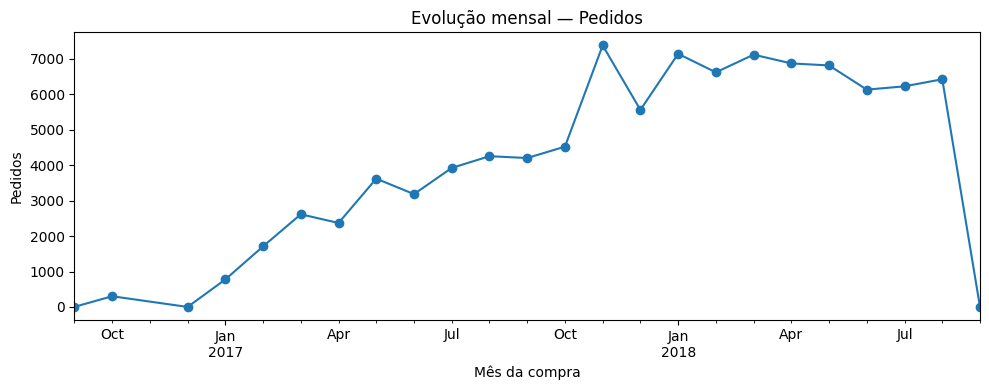

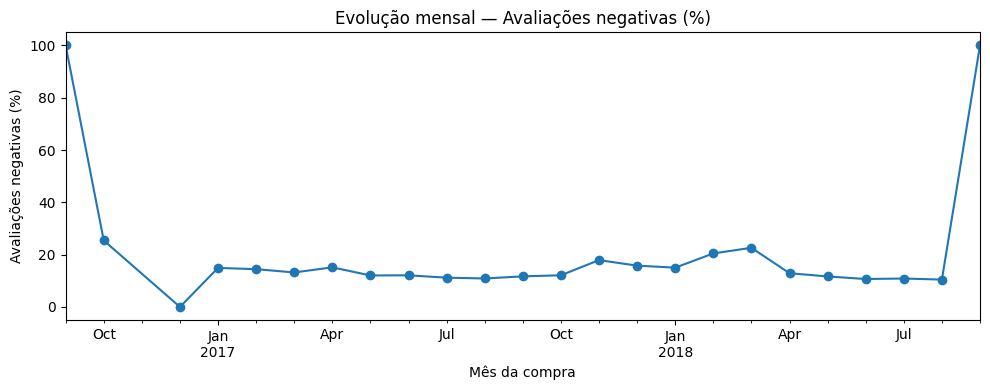

In [108]:
# 5.13.2 — Distribuição temporal dos pedidos

print('5.13.2 — Distribuição temporal dos pedidos\n')

monthly_orders = (
    df_model
    .groupby(df_model['order_purchase_timestamp'].dt.to_period('M'))
    .agg(
        pedidos=('order_id', 'count'),
        avaliacoes_ruins=('bad_review', 'sum'),
        taxa_bad_review=('bad_review', 'mean')
    )
)

monthly_orders['taxa_bad_review'] = (
    monthly_orders['taxa_bad_review'] * 100
).round(2)

print(monthly_orders)

print('\nPeríodo disponível:')
print(f'Primeira compra: {df_model["order_purchase_timestamp"].min()}')
print(f'Última compra: {df_model["order_purchase_timestamp"].max()}')


# Visualização da sazonalidade histórica
for col, label in [('pedidos','Pedidos'),('taxa_bad_review','Avaliações negativas (%)')]:
    ax = monthly_orders[col].plot(figsize=(10,4), marker='o')
    ax.set(title=f'Evolução mensal — {label}', xlabel='Mês da compra', ylabel=label)
    plt.tight_layout(); plt.show()


#### Conclusão da análise temporal

A base elegível contém pedidos realizados entre setembro de 2016 e setembro de 2018, com maior concentração de registros entre janeiro de 2017 e agosto de 2018.

Os meses iniciais e finais apresentam volumes muito reduzidos, exigindo cautela na interpretação de suas taxas de avaliação ruim.

A proporção de `bad_review` apresentou variações relevantes ao longo do período analisado. Destacam-se os aumentos observados em novembro de 2017 (17,91%), fevereiro de 2018 (20,46%) e março de 2018 (22,62%), seguidos por uma redução nos meses posteriores.

Essas variações indicam que a distribuição do target não permaneceu estável ao longo do tempo, aspecto importante para a avaliação da capacidade de generalização do modelo.

Como o objetivo é prever a insatisfação de pedidos futuros a partir de informações históricas, uma divisão temporal apresenta maior proximidade com o cenário real de aplicação do modelo.

Entretanto, a existência de clientes recorrentes também exige atenção para evitar a sobreposição de clientes entre os conjuntos de treino, validação e teste.

Antes de realizar a divisão definitiva, será avaliado o impacto dessa recorrência em possíveis períodos temporais.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [109]:
# 5.13.3 — Avaliação preliminar da divisão temporal

print('5.13.3 — Divisão temporal pela aprovação do pedido\n')

approval_date = df_model['order_approved_at']

cutoff_train = pd.Timestamp('2018-03-01')
cutoff_valid = pd.Timestamp('2018-06-01')
cutoff_test = pd.Timestamp('2018-09-01')

period_train = approval_date < cutoff_train

period_valid = (
    (approval_date >= cutoff_train) &
    (approval_date < cutoff_valid)
)

period_test = (
    (approval_date >= cutoff_valid) &
    (approval_date < cutoff_test)
)

periods = {
    'Treino': period_train,
    'Validação': period_valid,
    'Teste': period_test
}

for name, mask in periods.items():
    subset = df_model.loc[mask]

    print(f'{name}: {len(subset)} pedidos')
    print(f'  Clientes únicos: {subset["customer_unique_id"].nunique()}')
    print(f'  Taxa bad_review: {subset["bad_review"].mean() * 100:.2f}%')

train_customers = set(
    df_model.loc[period_train, 'customer_unique_id']
)

valid_customers = set(
    df_model.loc[period_valid, 'customer_unique_id']
)

test_customers = set(
    df_model.loc[period_test, 'customer_unique_id']
)

print('\nClientes presentes em mais de um período:')
print(f'Treino e validação: {len(train_customers & valid_customers)}')
print(f'Treino e teste: {len(train_customers & test_customers)}')
print(f'Validação e teste: {len(valid_customers & test_customers)}')

print('\nPedidos fora dos períodos propostos:')
print((~(period_train | period_valid | period_test)).sum())


5.13.3 — Divisão temporal pela aprovação do pedido

Treino: 58052 pedidos
  Clientes únicos: 56273
  Taxa bad_review: 14.64%
Validação: 20924 pedidos
  Clientes únicos: 20621
  Taxa bad_review: 15.90%
Teste: 18831 pedidos
  Clientes únicos: 18611
  Taxa bad_review: 10.66%

Clientes presentes em mais de um período:
Treino e validação: 395
Treino e teste: 286
Validação e teste: 165

Pedidos fora dos períodos propostos:
1


#### Análise preliminar da divisão temporal

Pela data de aprovação, foram observados 58.052 pedidos de treino, 20.924 de validação e 18.831 de teste, com prevalências de 14,64%, 15,90% e 10,66%. As interseções de clientes foram 395, 286 e 165, respectivamente para treino/validação, treino/teste e validação/teste. Um pedido ficou fora dos períodos. A disponibilidade dos rótulos será controlada na etapa seguinte.


In [110]:
# 5.13.4 — Auditoria de clientes recorrentes entre períodos

print('5.13.4 — Auditoria de clientes recorrentes entre períodos\n')

overlap_train_valid = train_customers & valid_customers
overlap_train_test = train_customers & test_customers
overlap_valid_test = valid_customers & test_customers

all_overlap = (
    overlap_train_valid |
    overlap_train_test |
    overlap_valid_test
)

print(f'Clientes distintos presentes em mais de um período: {len(all_overlap)}')

print('\nPedidos associados a clientes compartilhados:')
for name, mask in periods.items():
    subset = df_model.loc[mask]
    affected = subset['customer_unique_id'].isin(all_overlap).sum()
    print(f'{name}: {affected} pedidos ({affected / len(subset) * 100:.2f}%)')

print('\nPedidos fora dos períodos:')
print(
    df_model.loc[
        ~(period_train | period_valid | period_test),
        ['order_id', 'order_purchase_timestamp', 'order_approved_at', 'bad_review']
    ].to_string(index=False)
)


5.13.4 — Auditoria de clientes recorrentes entre períodos

Clientes distintos presentes em mais de um período: 812

Pedidos associados a clientes compartilhados:
Treino: 775 pedidos (1.34%)
Validação: 568 pedidos (2.71%)
Teste: 456 pedidos (2.42%)

Pedidos fora dos períodos:
                        order_id order_purchase_timestamp   order_approved_at  bad_review
54282e97f61c23b78330c15b154c867d      2018-09-03 09:06:57 2018-09-03 17:40:06           1


#### 5.13.5 — Divisão temporal com exclusividade de clientes e disponibilidade do target

A divisão temporal será realizada considerando a data de aprovação dos pedidos, em alinhamento com o momento definido para a previsão.

Para evitar o uso de avaliações ainda indisponíveis nas respectivas datas de corte, serão considerados:

- Treinamento: pedidos aprovados antes de 01/03/2018, com avaliações disponíveis antes dessa data.
- Validação: pedidos aprovados entre março e maio de 2018, com avaliações disponíveis antes de 01/06/2018.
- Teste: pedidos aprovados entre junho e agosto de 2018, utilizando as avaliações observadas retrospectivamente.

Será preservada a estratégia de exclusividade de clientes entre os conjuntos, mantendo a população de avaliação restrita a clientes não observados nos períodos anteriores.

A exclusão de avaliações ainda indisponíveis pode alterar a distribuição da











variável-alvo e introduzir viés de seleção. Por esse motivo, serão


avaliados os volumes preservados e as respectivas taxas de avaliações nega
tivas.

A avaliação do teste será retrospectiva, considerando que seus resultados originais já foram examinados durante o desenvolvimento do projeto.








In [111]:
# 5.13.5 — Divisão temporal com disponibilidade do target

print('5.13.5 — Divisão temporal corrigida\n')

review_dates = (
    reviews.assign(
        review_answer_timestamp=pd.to_datetime(
            reviews['review_answer_timestamp'],
            errors='coerce'
        )
    )
    .groupby('order_id')['review_answer_timestamp']
    .max()
)

review_available_at = df_model['order_id'].map(review_dates)

train_sim = df_model.loc[
    period_train &
    (review_available_at < cutoff_train)
].copy()

valid_sim = df_model.loc[
    period_valid &
    (review_available_at < cutoff_valid) &
    ~df_model['customer_unique_id'].isin(train_customers)
].copy()

test_sim = df_model.loc[
    period_test &
    review_available_at.notna() &
    ~df_model['customer_unique_id'].isin(
        train_customers | valid_customers
    )
].copy()

simulated_sets = {
    'Treino': train_sim,
    'Validação': valid_sim,
    'Teste': test_sim
}

for name, subset in simulated_sets.items():
    print(f'{name}: {len(subset)} pedidos')
    print(f'  Clientes únicos: {subset["customer_unique_id"].nunique()}')
    print(f'  Taxa bad_review: {subset["bad_review"].mean() * 100:.2f}%')

print('\nVerificação de clientes compartilhados:')

print(
    'Treino e validação:',
    len(set(train_sim['customer_unique_id']) &
        set(valid_sim['customer_unique_id']))
)

print(
    'Treino e teste:',
    len(set(train_sim['customer_unique_id']) &
        set(test_sim['customer_unique_id']))
)

print(
    'Validação e teste:',
    len(set(valid_sim['customer_unique_id']) &
        set(test_sim['customer_unique_id']))
)

total_sim = sum(len(subset) for subset in simulated_sets.values())

print('\nResumo:')
print(f'Pedidos preservados: {total_sim}')
print(f'Pedidos fora da divisão: {len(df_model) - total_sim}')
print(f'Percentual preservado: {total_sim / len(df_model) * 100:.2f}%')

print('\nVerificação da disponibilidade do target:')

assert train_sim['order_id'].map(review_dates).lt(cutoff_train).all()
assert valid_sim['order_id'].map(review_dates).lt(cutoff_valid).all()

print('Disponibilidade temporal confirmada no treino e na validação.')


5.13.5 — Divisão temporal corrigida

Treino: 53699 pedidos
  Clientes únicos: 52088
  Taxa bad_review: 13.64%
Validação: 17914 pedidos
  Clientes únicos: 17678
  Taxa bad_review: 15.77%
Teste: 18375 pedidos
  Clientes únicos: 18177
  Taxa bad_review: 10.76%

Verificação de clientes compartilhados:
Treino e validação: 0
Treino e teste: 0
Validação e teste: 0

Resumo:
Pedidos preservados: 89988
Pedidos fora da divisão: 7820
Percentual preservado: 92.00%

Verificação da disponibilidade do target:
Disponibilidade temporal confirmada no treino e na validação.


#### Conclusão da simulação da divisão temporal

A execução informada da divisão corrigida preservou 89.988 pedidos (92,00% dos 97.808 elegíveis): 53.699 de treino, 17.914 de validação e 18.375 de teste. Foram excluídos 7.820 pedidos por critérios temporais, disponibilidade dos rótulos e exclusividade de clientes. Não houve sobreposição de clientes. A exclusão de avaliações tardias pode introduzir viés de seleção; a avaliação é retrospectiva e restrita a clientes não observados nos períodos anteriores.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [112]:
# 5.13.6 — Construção dos conjuntos de treino, validação e teste

print('5.13.6 — Construção dos conjuntos de treino, validação e teste\n')

X_train = train_sim[feature_cols].copy()
X_valid = valid_sim[feature_cols].copy()
X_test = test_sim[feature_cols].copy()

y_train = train_sim[target_col].copy()
y_valid = valid_sim[target_col].copy()
y_test = test_sim[target_col].copy()

for name, X, y in [
    ('Treino', X_train, y_train),
    ('Validação', X_valid, y_valid),
    ('Teste', X_test, y_test)
]:
    print(f'{name}:')
    print(f'  X: {X.shape}')
    print(f'  y: {y.shape}')
    print(f'  Bad review: {y.mean() * 100:.2f}%')
    print(f'  Valores ausentes em X: {X.isna().sum().sum()}')

print('\nVerificação das features:')
print(f'Mesmas colunas em todos os conjuntos: {list(X_train.columns) == list(X_valid.columns) == list(X_test.columns)}')
print(f'Target presente em X: {target_col in X_train.columns}')
assert list(X_train.columns) == list(X_valid.columns) == list(X_test.columns)
assert target_col not in X_train.columns
assert all(X.index.equals(y.index) for X, y in [(X_train, y_train), (X_valid, y_valid), (X_test, y_test)])


5.13.6 — Construção dos conjuntos de treino, validação e teste

Treino:
  X: (53699, 27)
  y: (53699,)
  Bad review: 13.64%
  Valores ausentes em X: 2830
Validação:
  X: (17914, 27)
  y: (17914,)
  Bad review: 15.77%
  Valores ausentes em X: 600
Teste:
  X: (18375, 27)
  y: (18375,)
  Bad review: 10.76%
  Valores ausentes em X: 399

Verificação das features:
Mesmas colunas em todos os conjuntos: True
Target presente em X: False


#### Conclusão da divisão dos dados

Na execução informada, os conjuntos contêm 53.699, 17.914 e 18.375 pedidos, respectivamente, com 27 features cada. As prevalências são 13,64%, 15,77% e 10,76%; os valores ausentes nas features totalizam 2.343, 503 e 241. A imputação será ajustada exclusivamente no treino. A ausência do target nas features e a igualdade das colunas foram confirmadas. O teste corrigido é retrospectivo, pois a versão anterior já foi examinada.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [113]:
# 5.14.1 — Diagnóstico de valores ausentes por conjunto

print('5.14.1 — Diagnóstico de valores ausentes por conjunto\n')

missing_summary = pd.DataFrame({
    'Treino': X_train.isna().sum(),
    'Validação': X_valid.isna().sum(),
    'Teste': X_test.isna().sum()
})

missing_summary = missing_summary[
    missing_summary.sum(axis=1) > 0
].sort_values('Treino', ascending=False)

print(missing_summary)

print('\nTipos das features com valores ausentes:')
print(X_train[missing_summary.index].dtypes)

print('\nTotal de registros com pelo menos um valor ausente:')
for name, X in [('Treino', X_train), ('Validação', X_valid), ('Teste', X_test)]:
    n_missing = X.isna().any(axis=1).sum()
    print(f'{name}: {n_missing} ({n_missing / len(X) * 100:.2f}%)')


print('Conclusão atualizada: a imputação preserva os pedidos com dados ausentes e será ajustada apenas no treino.')

5.14.1 — Diagnóstico de valores ausentes por conjunto

                        Treino  Validação  Teste
avg_description_length     997        205     83
avg_photos_qty             997        205     83
avg_distance_km            768        190    233
max_weight_g                16          0      0
total_volume_cm3            16          0      0
max_volume_cm3              16          0      0
total_weight_g              16          0      0
max_installments             1          0      0
payment_types_count          1          0      0
payment_count                1          0      0
main_payment_type            1          0      0

Tipos das features com valores ausentes:
avg_description_length    float64
avg_photos_qty            float64
avg_distance_km           float64
max_weight_g              float64
total_volume_cm3          float64
max_volume_cm3            float64
total_weight_g            float64
max_installments          float64
payment_types_count       float64
payment_c


#### Conclusão do diagnóstico de valores ausentes

O diagnóstico acima apresenta as features afetadas e os totais recalculados.

Na execução revisada pelo tutor, antes da nova limpeza geográfica, eram 1.275 (2,37%) no treino, 297 (1,66%) na validação e 157 (0,85%) no teste. Os valores vigentes são os impressos acima após a nova limpeza.

As ausências estão concentradas principalmente nas variáveis relacionadas à descrição e à quantidade de fotos dos produtos, seguidas pela distância geográfica entre clientes e vendedores.

As variáveis de peso, volume e pagamento apresentam quantidades reduzidas de registros incompletos.

Para preservar os pedidos afetados, será adotada a imputação dos valores ausentes em vez da exclusão de registros adicionais.

Para variáveis numéricas, será utilizada a mediana calculada exclusivamente sobre o conjunto de treino. Para variáveis categóricas, será adotado um tratamento específico para categorias ausentes.

As transformações serão incorporadas ao pipeline de pré-processamento, garantindo a aplicação consistente das mesmas regras aos conjuntos de validação e teste.


In [114]:
# 5.14.2 — Construção do pré-processamento

print('5.14.2 — Construção do pré-processamento\n')

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print(f'Features numéricas: {len(numeric_features)}')
print(f'Features categóricas: {len(categorical_features)}')
print(f'Total de features originais: {len(feature_cols)}')

print('\nPré-processador configurado:')
print(preprocessor)


5.14.2 — Construção do pré-processamento

Features numéricas: 21
Features categóricas: 6
Total de features originais: 27

Pré-processador configurado:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['item_count', 'unique_products',
                                  'unique_sellers', 'total_price',
                                  'total_freight', 'payment_count',
                                  'payment_types_count', 'max_installments',
                                  'category_count', 'total_weight_g',
                                  'max_weight_g', 'total_volume_cm3',
                                  'max_volume_cm3', 'avg_photos_qty',
                                  'avg_descr...
                                  'avg_distance_km', 'approval_delay_hours',
                                  'estimated_de


#### Conclusão da configuração do pré-processamento

Foi construído um pré-processador utilizando `ColumnTransformer` e `Pipeline`, com tratamentos específicos para as 27 features selecionadas.

As 21 variáveis numéricas receberão imputação pela mediana, enquanto as 6 variáveis categóricas terão seus valores ausentes substituídos pela categoria `missing`, seguida de codificação One-Hot Encoding.

O codificador foi configurado para aceitar categorias desconhecidas durante a transformação dos conjuntos de validação e teste, evitando erros quando surgirem categorias não observadas no treinamento.

O pré-processador ainda não foi ajustado aos dados. Seu ajuste ocorrerá exclusivamente durante o treinamento dos modelos, evitando o vazamento de informações dos conjuntos de validação e teste.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [115]:
# 5.14.3 — Verificação da estrutura do pré-processamento

print('5.14.3 — Verificação da estrutura do pré-processamento\n')

configured_features = numeric_features + categorical_features

missing_features = set(feature_cols) - set(configured_features)
extra_features = set(configured_features) - set(feature_cols)
duplicated_features = pd.Series(configured_features).duplicated().sum()

print(f'Features selecionadas: {len(feature_cols)}')
print(f'Features configuradas: {len(configured_features)}')
print(f'Features não configuradas: {len(missing_features)}')
print(f'Features extras: {len(extra_features)}')
print(f'Features duplicadas: {duplicated_features}')

print('\nVerificações:')
print(f'Todas as features contempladas: {set(configured_features) == set(feature_cols)}')
print(f'Sem duplicações: {duplicated_features == 0}')
print(f'Pré-processador ainda não ajustado: {not hasattr(preprocessor, "transformers_")}')


5.14.3 — Verificação da estrutura do pré-processamento

Features selecionadas: 27
Features configuradas: 27
Features não configuradas: 0
Features extras: 0
Features duplicadas: 0

Verificações:
Todas as features contempladas: True
Sem duplicações: True
Pré-processador ainda não ajustado: True



#### Conclusão da validação do pré-processamento

A verificação confirmou que todas as 27 features selecionadas estão corretamente contempladas no pré-processador, sem variáveis duplicadas, ausentes ou adicionais.

Também foi confirmado que o `ColumnTransformer` permanece não ajustado, garantindo que os parâmetros de imputação e codificação sejam aprendidos exclusivamente durante o treinamento.

Com a divisão dos dados e a estrutura de pré-processamento validadas, a base está preparada para a próxima etapa de modelagem preditiva.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.15 — EDA complementar e teste de hipótese

As análises adicionais usam apenas o treino temporal. A exploração histórica anterior já consultou outros períodos; portanto o teste é exploratório, não confirmação independente.

### 5.15.1 — Distribuição do target e correlações

Visualizar a prevalência e as associações monotônicas entre atributos numéricos e target. Correlação não implica causalidade.

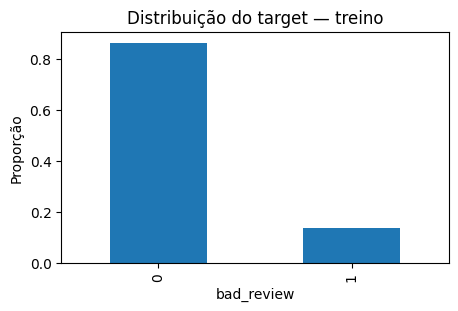

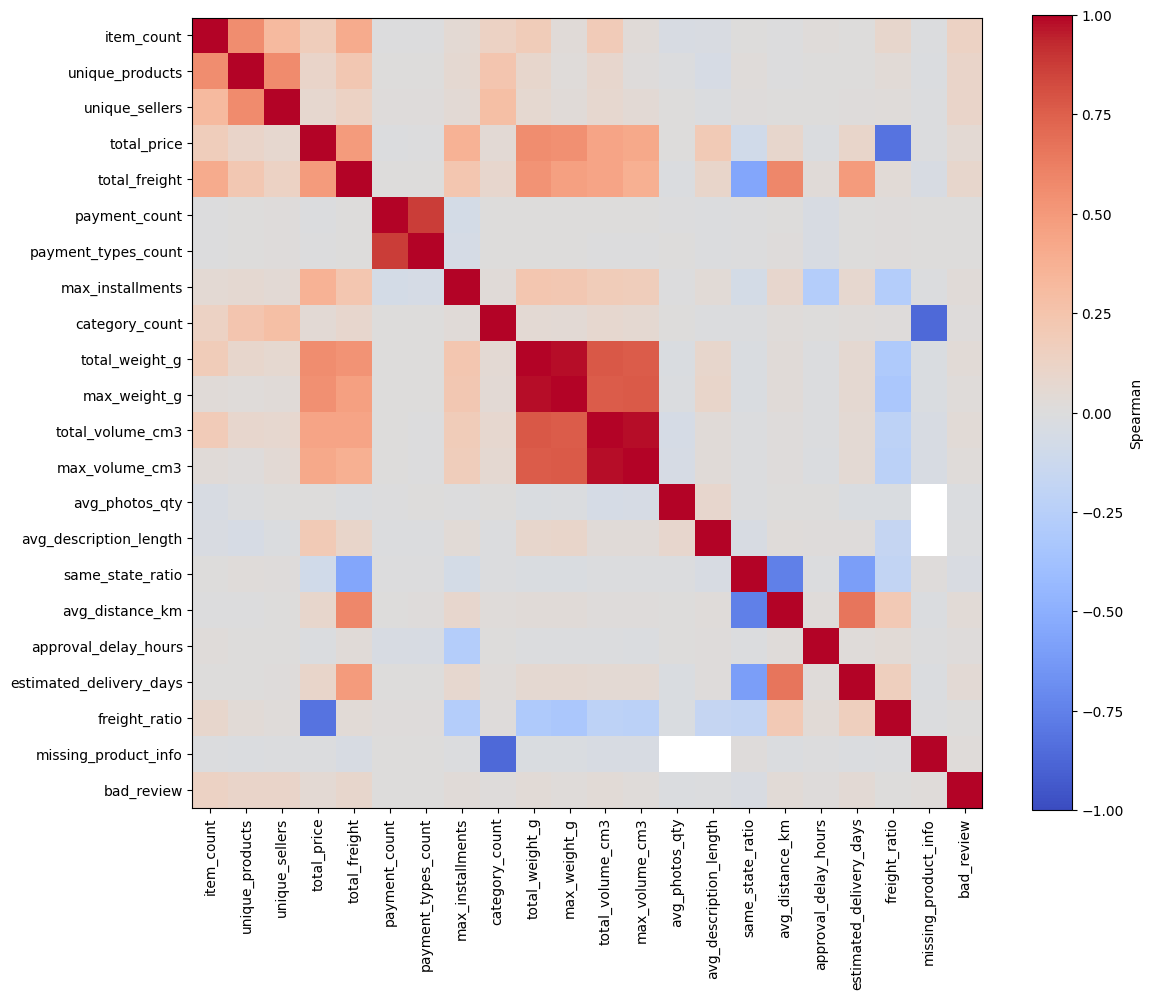

,Spearman
item_count,0.129400
unique_sellers,0.104496
unique_products,0.104144
total_freight,0.089398
total_price,0.050322
estimated_delivery_days,0.045678
total_weight_g,0.038367
total_volume_cm3,0.036732
same_state_ratio,-0.035074
avg_distance_km,0.032635


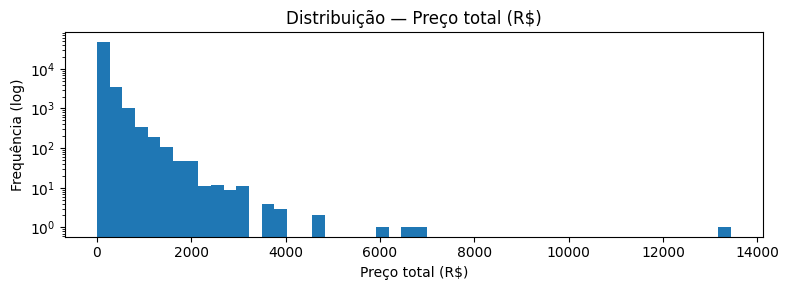

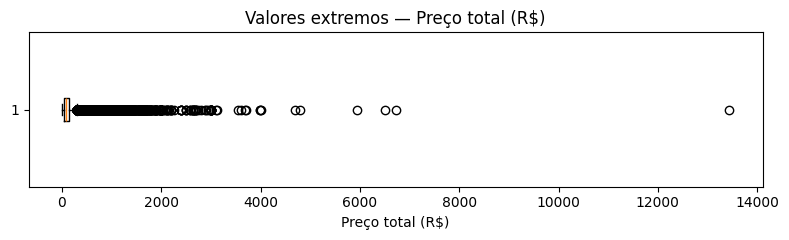

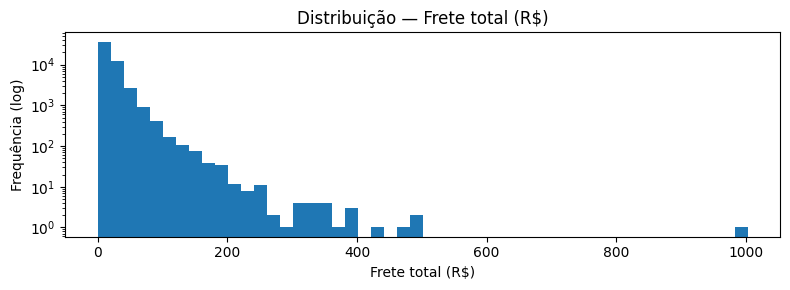

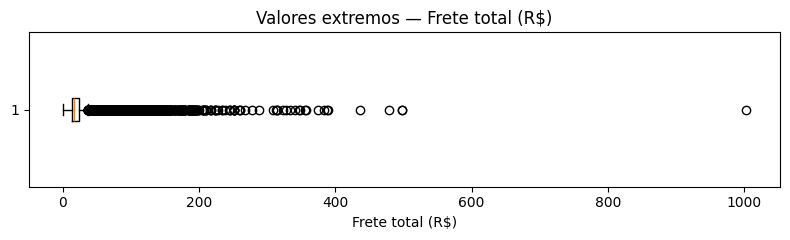

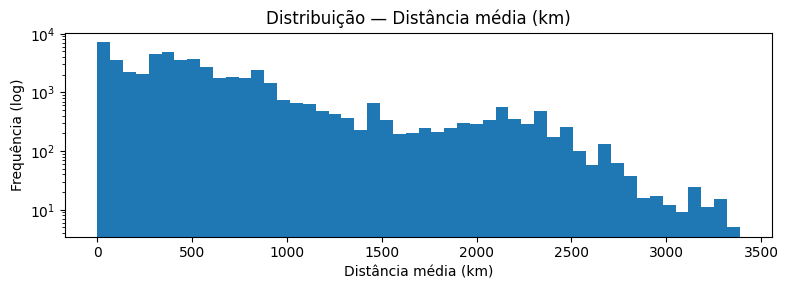

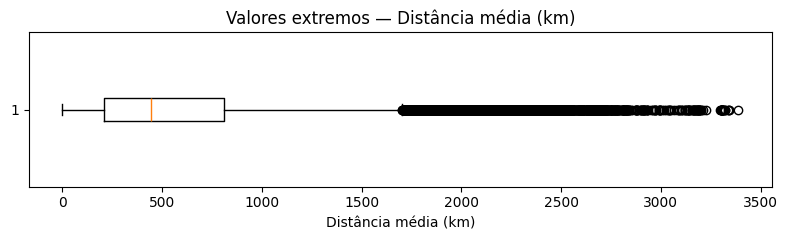

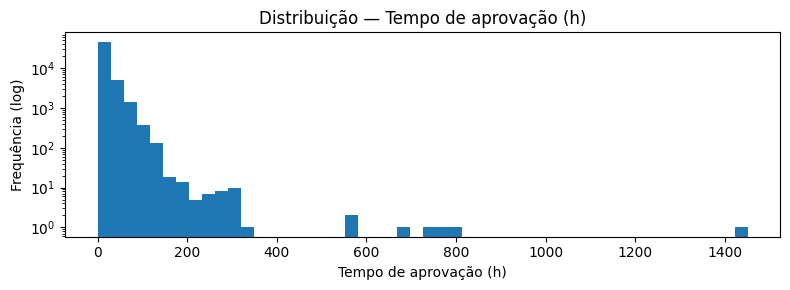

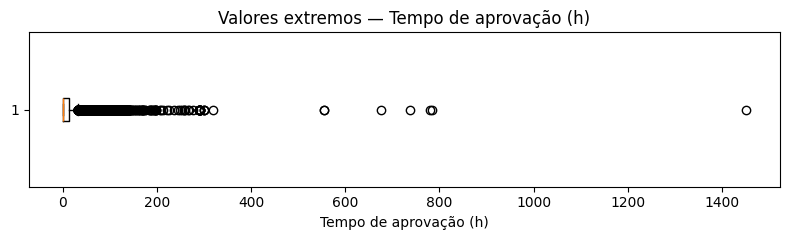

In [116]:
# 5.15.1 — Distribuição do target e correlações
fig, ax = plt.subplots(figsize=(5, 3))
y_train.value_counts(normalize=True).sort_index().plot.bar(ax=ax)
ax.set(xlabel='bad_review', ylabel='Proporção', title='Distribuição do target — treino')
plt.show()
eda_train = X_train[numeric_features].assign(bad_review=y_train)
corr_train = eda_train.corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_train, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr_train)), corr_train.columns, rotation=90)
ax.set_yticks(range(len(corr_train)), corr_train.columns)
fig.colorbar(im, ax=ax, label='Spearman')
plt.tight_layout()
plt.show()
display(corr_train['bad_review'].drop('bad_review').sort_values(key=abs, ascending=False).to_frame('Spearman'))

# Distribuições e extremos no treino, sem alterar os dados
for col, label in [('total_price','Preço total (R$)'),('total_freight','Frete total (R$)'),('avg_distance_km','Distância média (km)'),('approval_delay_hours','Tempo de aprovação (h)')]:
    values = X_train[col].dropna()
    fig, ax = plt.subplots(figsize=(8,3))
    ax.hist(values, bins=50, log=True)
    ax.set(title=f'Distribuição — {label}', xlabel=label, ylabel='Frequência (log)')
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(8,2.5))
    ax.boxplot(values, vert=False, showfliers=True)
    ax.set(title=f'Valores extremos — {label}', xlabel=label)
    plt.tight_layout(); plt.show()


### 5.15.2 — Teste de hipótese: prazo estimado e avaliação negativa

H₀: as distribuições do prazo estimado são iguais nos dois grupos. H₁: o prazo tende a ser maior entre avaliações negativas. Mann–Whitney unilateral, α = 0,05. O efeito será quantificado por probabilidade de superioridade (U/(n₁n₀), contando empates pela metade). Para reduzir dependência entre pedidos do mesmo cliente, utiliza-se apenas o primeiro pedido elegível de cada cliente no treino. O teste não estabelece causalidade.

,size,median,mean
bad_review,,,
0,44951,24.055428,24.846286
1,7137,24.990023,26.048828


U = 172937566.50; p = 1.23022e-26; superioridade = 0.5391
Rejeitamos H0 a 5%.
A magnitude do efeito deve ser avaliada separadamente da significância.


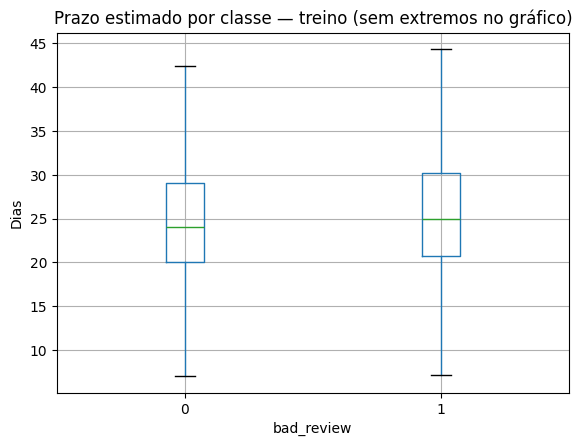

In [117]:
# 5.15.2 — Teste de hipótese: prazo estimado e avaliação negativa
hyp = train_sim.sort_values(['order_approved_at', 'order_id']).drop_duplicates('customer_unique_id')
hyp = hyp[['estimated_delivery_days', 'bad_review']].dropna()
negative = hyp.loc[hyp.bad_review.eq(1), 'estimated_delivery_days']
other = hyp.loc[hyp.bad_review.eq(0), 'estimated_delivery_days']
assert len(negative) and len(other)
u, p_value = mannwhitneyu(negative, other, alternative='greater', method='asymptotic')
effect = u / (len(negative) * len(other))
display(hyp.groupby('bad_review')['estimated_delivery_days'].agg(['size', 'median', 'mean']))
print(f'U = {u:.2f}; p = {p_value:.6g}; superioridade = {effect:.4f}')
print('Rejeitamos H0 a 5%.' if p_value < .05 else 'Não rejeitamos H0 a 5%.')
print('A magnitude do efeito deve ser avaliada separadamente da significância.')
hyp.boxplot(column='estimated_delivery_days', by='bad_review', showfliers=False)
plt.suptitle('')
plt.title('Prazo estimado por classe — treino (sem extremos no gráfico)')
plt.ylabel('Dias')
plt.show()

#### Conclusão do EDA complementar e teste de hipótese

No treino, as correlações de Spearman com o target são fracas (maior magnitude: item_count, 0,1294). O teste unilateral de Mann–Whitney, com um pedido por cliente (52.088 clientes), apresentou U = 172.937.566,50 e p = 1,23022 × 10⁻²⁶. Rejeita-se H₀ a 5%. Os prazos médios foram 26,05 dias na classe negativa e 24,85 na outra classe. A probabilidade de superioridade de 0,5391 indica efeito pequeno. O resultado é exploratório e não estabelece causalidade.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 5.16 — Integridade e exportação da base

A base elegível é histórica e contém o target. Os conjuntos temporais permanecem separados; a imputação será ajustada exclusivamente no treino. A disponibilidade histórica de atributos de catálogo, geolocalização e pagamentos não é comprovada por snapshots no momento da aprovação; trata-se de uma hipótese operacional a validar.

In [118]:
# 5.16 — Integridade e exportação da base
assert df_model.order_id.is_unique
assert df_model[target_col].isin([0, 1]).all()
assert not df_model.duplicated().any()
assert not X_train.isna().all().any()
assert not set(id_cols + leakage_cols + [target_col]) & set(X_train.columns)
for name, frame in simulated_sets.items():
    print(name, frame.shape, 'duplicatas integrais:', frame.duplicated().sum())
output_dir = 'olist_processed'
os.makedirs(output_dir, exist_ok=True)
df_model.to_csv(os.path.join(output_dir, 'base_elegivel.csv'), index=False)
for name, X, y in [('train', X_train, y_train), ('valid', X_valid, y_valid), ('test', X_test, y_test)]:
    X.assign(bad_review=y).to_csv(os.path.join(output_dir, f'{name}.csv'), index=False)
print('Arquivos exportados:', sorted(os.listdir(output_dir)))

# Tamanho dos CSVs para publicação no GitHub
for arquivo in sorted(os.listdir(output_dir)):
    tamanho = os.path.getsize(os.path.join(output_dir, arquivo))
    print(f'{arquivo}: {tamanho/1024**2:.2f} MiB — ' + ('usar Git LFS ou disponibilizar externamente' if tamanho >= 100*1024**2 else 'abaixo do limite de 100 MiB'))


Treino (53699, 43) duplicatas integrais: 0
Validação (17914, 43) duplicatas integrais: 0
Teste (18375, 43) duplicatas integrais: 0
Arquivos exportados: ['base_elegivel.csv', 'test.csv', 'train.csv', 'valid.csv']
base_elegivel.csv: 41.08 MiB — abaixo do limite de 100 MiB
test.csv: 3.39 MiB — abaixo do limite de 100 MiB
train.csv: 9.90 MiB — abaixo do limite de 100 MiB
valid.csv: 3.31 MiB — abaixo do limite de 100 MiB


#### Conclusão da integridade e preparação

As verificações confirmaram unicidade do pedido, target binário, ausência de duplicatas integrais nos conjuntos e ausência de IDs, colunas de leakage explicitamente listadas e target nas entradas. Foram exportados base_elegivel.csv, train.csv, valid.csv e test.csv. Os conjuntos contêm 53.699, 17.914 e 18.375 pedidos (89.988 no total). Os CSVs são gerados no ambiente de execução e não estão incorporados ao notebook. A disponibilidade histórica das features permanece uma hipótese operacional a validar.

> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

## 6 — Modelagem preditiva

Os modelos foram reajustados sobre o treino corrigido. Os limiares históricos (0,15 para LR e 0,45 para RF e LightGBM) foram preservados como referências e também apresentaram o maior F1 nas respectivas grades avaliadas na nova validação.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.


### 6.1 Definição do modelo baseline

Antes do treinamento dos modelos de Machine Learning, será estabelecido um baseline utilizando a classe majoritária do conjunto de treino.

Como a variável-alvo apresenta desbalanceamento, um classificador que prevê sempre a classe mais frequente pode alcançar acurácia elevada sem identificar avaliações ruins.

O baseline será utilizado como referência mínima de desempenho, permitindo avaliar se os modelos posteriores oferecem ganhos reais na identificação de pedidos com maior risco de insatisfação.

A comparação considerará principalmente precisão, recall, F1-score e ROC-AUC, além da acurácia.

O conjunto de teste permanecerá reservado para a avaliação final.


In [119]:
# 6.1.1 — Distribuição das classes no conjunto de treino

print('6.1.1 — Distribuição das classes no conjunto de treino\n')

class_distribution = y_train.value_counts().sort_index()
class_percentage = (y_train.value_counts(normalize=True).sort_index() * 100).round(2)

print(pd.DataFrame({
    'Quantidade': class_distribution,
    'Percentual (%)': class_percentage
}))

print(f'\nClasse majoritária: {y_train.mode()[0]}')
print(f'Acurácia esperada do baseline majoritário: {class_percentage.max():.2f}%')


6.1.1 — Distribuição das classes no conjunto de treino

            Quantidade  Percentual (%)
bad_review                            
0                46377           86.36
1                 7322           13.64

Classe majoritária: 0
Acurácia esperada do baseline majoritário: 86.36%


#### Conclusão da distribuição das classes

O treino contém 53.699 pedidos, dos quais 7.322 (13,64%) têm avaliação negativa. A classe majoritária representa 86,36%, justificando o uso de métricas além da acurácia.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [120]:
# 6.1.2 — Treinamento e avaliação do baseline majoritário

print('6.1.2 — Treinamento e avaliação do baseline majoritário\n')

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_valid)
y_proba_baseline = baseline.predict_proba(X_valid)[:, 1]

print(f'Acurácia: {accuracy_score(y_valid, y_pred_baseline):.4f}')
print(f'Precisão: {precision_score(y_valid, y_pred_baseline, zero_division=0):.4f}')
print(f'Recall: {recall_score(y_valid, y_pred_baseline, zero_division=0):.4f}')
print(f'F1-score: {f1_score(y_valid, y_pred_baseline, zero_division=0):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_valid, y_proba_baseline):.4f}')

print('\nDistribuição das previsões:')
print(pd.Series(y_pred_baseline).value_counts().sort_index())


6.1.2 — Treinamento e avaliação do baseline majoritário

Acurácia: 0.8423
Precisão: 0.0000
Recall: 0.0000
F1-score: 0.0000
ROC-AUC: 0.5000

Distribuição das previsões:
0    17914
Name: count, dtype: int64


#### Conclusão da avaliação do baseline

O baseline prevê todos os 17.914 pedidos como não negativos. A acurácia de 84,23% contrasta com recall e F1 iguais a zero e ROC-AUC de 0,50. A acurácia isolada não é adequada ao objetivo de identificar insatisfação.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.


### 6.2 Regressão Logística

A Regressão Logística será utilizada como primeiro modelo supervisionado para prever a probabilidade de um pedido receber uma avaliação ruim.

O algoritmo oferece uma referência interpretável para o problema de classificação binária e permite comparar seu desempenho com modelos mais complexos.

O pré-processamento será integrado ao pipeline, incluindo imputação de valores ausentes, padronização das variáveis numéricas e codificação das variáveis categóricas.

A padronização será ajustada exclusivamente sobre os dados de treino, evitando vazamento de informações.

Inicialmente, será utilizada uma configuração simples do algoritmo, sem otimização de hiperparâmetros. O desempenho será avaliado no conjunto de validação e comparado ao baseline majoritário.


In [121]:
# 6.2.1 — Configuração do pipeline da Regressão Logística

print('6.2.1 — Configuração do pipeline da Regressão Logística\n')

numeric_transformer_lr = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_lr = ColumnTransformer(transformers=[
    ('num', numeric_transformer_lr, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

model_lr = Pipeline(steps=[
    ('preprocessor', clone(preprocessor_lr)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

print(model_lr)


6.2.1 — Configuração do pipeline da Regressão Logística

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['item_count',
                                                   'unique_products',
                                                   'unique_sellers',
                                                   'total_price',
                                                   'total_freight',
                                                   'payment_count',
                                                   'payment_types_count',
                            

In [122]:
# 6.2.2 — Treinamento e avaliação da Regressão Logística

print('6.2.2 — Treinamento e avaliação da Regressão Logística\n')

model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_valid)
y_proba_lr = model_lr.predict_proba(X_valid)[:, 1]

print(f'Acurácia: {accuracy_score(y_valid, y_pred_lr):.4f}')
print(f'Precisão: {precision_score(y_valid, y_pred_lr, zero_division=0):.4f}')
print(f'Recall: {recall_score(y_valid, y_pred_lr, zero_division=0):.4f}')
print(f'F1-score: {f1_score(y_valid, y_pred_lr, zero_division=0):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_valid, y_proba_lr):.4f}')

print('\nDistribuição das previsões:')
print(pd.Series(y_pred_lr).value_counts().sort_index())

print('\nConvergência do modelo:')
print(f'Iterações utilizadas: {model_lr.named_steps["classifier"].n_iter_[0]}')


6.2.2 — Treinamento e avaliação da Regressão Logística

Acurácia: 0.8421
Precisão: 0.4857
Recall: 0.0181
F1-score: 0.0348
ROC-AUC: 0.6214

Distribuição das previsões:
0    17809
1      105
Name: count, dtype: int64

Convergência do modelo:
Iterações utilizadas: 83


#### Conclusão do treinamento inicial da Regressão Logística

Com limiar 0,50, a Regressão Logística alcançou ROC-AUC de 0,6216, mas recall de apenas 1,91% e F1 de 0,0368. A acurácia de 84,22% é semelhante à do baseline; o ranking apresenta sinal preditivo, mas o limiar padrão é pouco útil para detectar negativos.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

In [123]:
# 6.2.3 — Avaliação de diferentes limiares de classificação

print('6.2.3 — Avaliação de diferentes limiares de classificação\n')

threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    y_pred_threshold = (y_proba_lr >= threshold).astype(int)

    threshold_results.append({
        'Limiar': threshold,
        'Precisão': precision_score(y_valid, y_pred_threshold, zero_division=0),
        'Recall': recall_score(y_valid, y_pred_threshold, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred_threshold, zero_division=0),
        'Alertas': y_pred_threshold.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


6.2.3 — Avaliação de diferentes limiares de classificação

 Limiar  Precisão  Recall  F1-score  Alertas
   0.10    0.1837  0.7766    0.2971    11942
   0.15    0.2519  0.3749    0.3013     4204
   0.20    0.3052  0.1678    0.2165     1553
   0.25    0.4085  0.1027    0.1641      710
   0.30    0.4499  0.0747    0.1281      469
   0.35    0.4986  0.0619    0.1102      351
   0.40    0.5197  0.0467    0.0857      254
   0.50    0.4857  0.0181    0.0348      105


#### Conclusão da análise dos limiares de classificação

Entre os limiares avaliados, 0,15 apresentou o maior F1 (0,3000), com precisão de 25,06%, recall de 37,38% e 4.214 alertas. O limiar 0,10 aumenta o recall para 78,02%, mas exige 12.018 alertas. O compromisso depende da capacidade operacional.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.2.4 Matriz de confusão da Regressão Logística

Nesta etapa, serão analisadas as matrizes de confusão da Regressão Logística utilizando os limiares de 0,50 e 0,15.

O objetivo é identificar a quantidade de verdadeiros positivos, falsos positivos, verdadeiros negativos e falsos negativos, permitindo avaliar os erros do modelo na identificação de avaliações ruins.

A comparação permitirá compreender o impacto da alteração do limiar sobre a capacidade de detectar pedidos potencialmente problemáticos e sobre a geração de alertas indevidos.

O conjunto de teste permanecerá reservado para a avaliação final.

6.2.4 — Matrizes de confusão da Regressão Logística



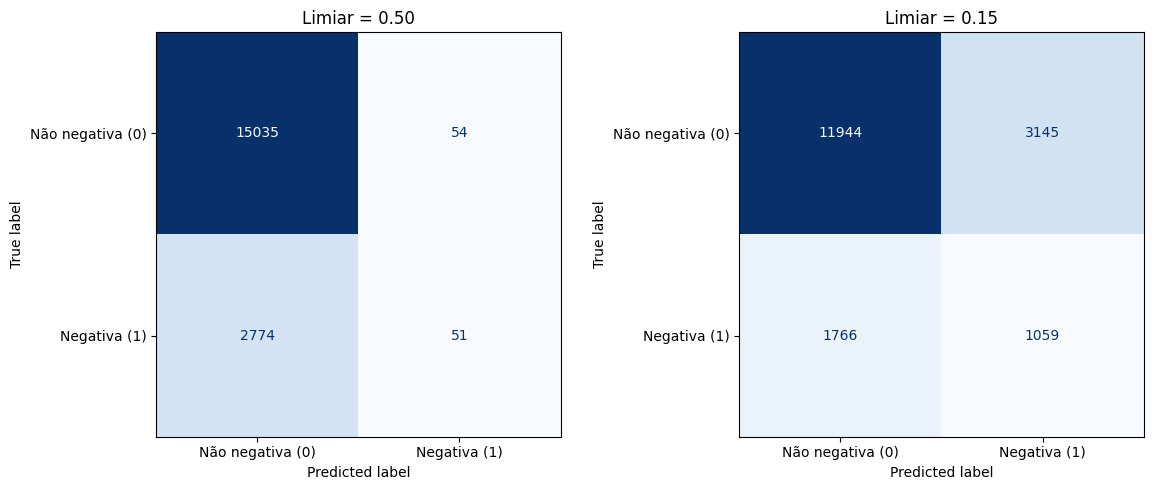

In [124]:
# 6.2.4 — Matrizes de confusão da Regressão Logística

print('6.2.4 — Matrizes de confusão da Regressão Logística\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(axes, [0.50, 0.15]):
    y_pred_threshold = (y_proba_lr >= threshold).astype(int)
    cm = confusion_matrix(y_valid, y_pred_threshold, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Não negativa (0)', 'Negativa (1)']
    )
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'Limiar = {threshold:.2f}')

plt.tight_layout()
plt.show()


**Conclusão da etapa 6.2.4**

A redução do limiar de 0,50 para 0,15 aumenta os alertas de 109 para 4.214 e o recall de 1,91% para 37,38%, ao custo de menor precisão (49,54% para 25,06%). A comparação evidencia o compromisso entre falsos positivos e negativos.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.2.5 — Interpretação dos coeficientes da Regressão Logística

Nesta etapa, serão analisados os coeficientes do modelo de Regressão Logística para identificar as variáveis associadas ao aumento ou à redução da probabilidade de avaliações negativas.

Coeficientes positivos indicam associação com maior risco previsto, enquanto coeficientes negativos indicam associação com menor risco, mantendo as demais variáveis constantes.

Como o modelo utiliza padronização das variáveis numéricas e One-Hot Encoding nas categóricas, a magnitude dos coeficientes deve ser interpretada considerando essas transformações.

Os resultados representam associações estatísticas, não relações de causa e efeito.

In [125]:
# 6.2.5.1 — Extração e análise dos coeficientes da Regressão Logística

print('6.2.5.1 — Coeficientes da Regressão Logística\n')

feature_names_lr = model_lr.named_steps['preprocessor'].get_feature_names_out()
coefficients_lr = model_lr.named_steps['classifier'].coef_[0]

df_coef_lr = pd.DataFrame({
    'Variável': feature_names_lr,
    'Coeficiente': coefficients_lr
})

df_coef_lr['Magnitude'] = df_coef_lr['Coeficiente'].abs()
df_coef_lr = df_coef_lr.sort_values('Magnitude', ascending=False)

print('Total de variáveis após o pré-processamento:', len(df_coef_lr))
print('\n20 coeficientes de maior magnitude:')
display(df_coef_lr.head(20).round(4))


6.2.5.1 — Coeficientes da Regressão Logística

Total de variáveis após o pré-processamento: 169

20 coeficientes de maior magnitude:


,Variável,Coeficiente,Magnitude
83,cat__main_product_category_fashion_male_clothing,1.1433,1.1433
129,cat__purchase_hour_3,-0.8499,0.8499
90,cat__main_product_category_food_drink,-0.8029,0.8029
57,cat__main_product_category_audio,0.6178,0.6178
27,cat__customer_state_AL,0.6156,0.6156
61,cat__main_product_category_books_general_interest,-0.5592,0.5592
104,cat__main_product_category_kitchen_dining_laun...,-0.5487,0.5487
29,cat__customer_state_AP,-0.5352,0.5352
80,cat__main_product_category_fashio_female_clothing,0.4838,0.4838
106,cat__main_product_category_luggage_accessories,-0.4767,0.4767


#### 6.2.5.2 — Análise dos coeficientes por tipo de variável

Nesta etapa, os coeficientes da Regressão Logística serão separados entre variáveis numéricas e categóricas, permitindo identificar os fatores associados ao risco previsto de avaliações negativas.

A análise considera o sinal e a magnitude dos coeficientes, respeitando as diferenças de codificação e escala entre as variáveis. Os resultados serão interpretados como associações, sem estabelecer relações causais.

In [126]:
# 6.2.5.2 — Coeficientes numéricos e categóricos

print('6.2.5.2 — Coeficientes por tipo de variável\n')

df_coef_num = df_coef_lr[df_coef_lr['Variável'].str.startswith('num__')]
df_coef_cat = df_coef_lr[df_coef_lr['Variável'].str.startswith('cat__')]

print(f'Variáveis numéricas: {len(df_coef_num)}')
print(f'Variáveis categóricas: {len(df_coef_cat)}')

print('\nCoeficientes numéricos:')
display(df_coef_num.sort_values('Magnitude', ascending=False).round(4))

print('\n15 coeficientes categóricos de maior magnitude:')
display(df_coef_cat.sort_values('Magnitude', ascending=False).head(15).round(4))


6.2.5.2 — Coeficientes por tipo de variável

Variáveis numéricas: 21
Variáveis categóricas: 148

Coeficientes numéricos:


,Variável,Coeficiente,Magnitude
0,num__item_count,0.1895,0.1895
2,num__unique_sellers,0.1352,0.1352
18,num__estimated_delivery_days,0.0866,0.0866
17,num__approval_delay_hours,0.0640,0.0640
10,num__max_weight_g,0.0629,0.0629
9,num__total_weight_g,-0.0488,0.0488
7,num__max_installments,0.0475,0.0475
3,num__total_price,0.0466,0.0466
8,num__category_count,-0.0351,0.0351
1,num__unique_products,0.0305,0.0305



15 coeficientes categóricos de maior magnitude:


,Variável,Coeficiente,Magnitude
83,cat__main_product_category_fashion_male_clothing,1.1433,1.1433
129,cat__purchase_hour_3,-0.8499,0.8499
90,cat__main_product_category_food_drink,-0.8029,0.8029
57,cat__main_product_category_audio,0.6178,0.6178
27,cat__customer_state_AL,0.6156,0.6156
61,cat__main_product_category_books_general_interest,-0.5592,0.5592
104,cat__main_product_category_kitchen_dining_laun...,-0.5487,0.5487
29,cat__customer_state_AP,-0.5352,0.5352
80,cat__main_product_category_fashio_female_clothing,0.4838,0.4838
106,cat__main_product_category_luggage_accessories,-0.4767,0.4767


#### 6.2.5.3 — Representatividade das principais categorias

Nesta etapa, será investigada a frequência das categorias com maiores coeficientes absolutos na Regressão Logística.

O objetivo é verificar se os coeficientes mais expressivos estão associados a categorias frequentes ou pouco representadas na amostra de treinamento.

Essa análise auxilia na interpretação dos resultados e na identificação de possíveis instabilidades relacionadas à baixa frequência de determinadas categorias.

In [127]:
# 6.2.5.3 — Frequência das categorias de maior magnitude

print('6.2.5.3 — Representatividade das categorias\n')

X_train_transformed = model_lr.named_steps['preprocessor'].transform(X_train)
feature_names = model_lr.named_steps['preprocessor'].get_feature_names_out()

top_cat = df_coef_cat.sort_values('Magnitude', ascending=False).head(15).copy()
indices = [list(feature_names).index(v) for v in top_cat['Variável']]

top_cat['Pedidos_treino'] = np.asarray(X_train_transformed[:, indices].sum(axis=0)).ravel().astype(int)
top_cat['Percentual_treino'] = 100 * top_cat['Pedidos_treino'] / X_train.shape[0]

display(top_cat[['Variável', 'Coeficiente', 'Pedidos_treino', 'Percentual_treino']].round(3))


6.2.5.3 — Representatividade das categorias



,Variável,Coeficiente,Pedidos_treino,Percentual_treino
83,cat__main_product_category_fashion_male_clothing,1.143,93,0.173
129,cat__purchase_hour_3,-0.850,151,0.281
90,cat__main_product_category_food_drink,-0.803,122,0.227
57,cat__main_product_category_audio,0.618,190,0.354
27,cat__customer_state_AL,0.616,237,0.441
61,cat__main_product_category_books_general_interest,-0.559,269,0.501
104,cat__main_product_category_kitchen_dining_laun...,-0.549,127,0.237
29,cat__customer_state_AP,-0.535,41,0.076
80,cat__main_product_category_fashio_female_clothing,0.484,32,0.060
106,cat__main_product_category_luggage_accessories,-0.477,701,1.305


**Conclusão da etapa 6.2.5 — Interpretação dos coeficientes**

O pré-processamento produziu 169 atributos. Entre os coeficientes numéricos, item_count (0,1888) e unique_sellers (0,1362) destacam-se positivamente. Categorias com coeficientes elevados podem ser raras: fashion_male_clothing aparece em 93 pedidos (0,173%) e AP em 41 (0,076%). Os coeficientes são associações condicionais, não efeitos causais; a codificação e a baixa frequência exigem cautela.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 6.3 Random Forest

O Random Forest será utilizado como segundo modelo supervisionado de classificação, permitindo avaliar relações não lineares e interações entre as características dos pedidos.

Diferentemente da Regressão Logística, esse algoritmo combina múltiplas árvores de decisão e não exige padronização das variáveis numéricas.

O modelo será inicialmente treinado com parâmetros controlados, utilizando os mesmos conjuntos de treino e validação definidos anteriormente. O conjunto de teste permanecerá reservado para a avaliação final.

O objetivo é comparar seu desempenho com o baseline e a Regressão Logística, especialmente em ROC-AUC, precisão, recall e F1-score da classe de avaliações negativas.

In [128]:
# 6.3.1 — Configuração do pipeline Random Forest

print('6.3.1 — Configuração do Random Forest\n')

model_rf = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

print(model_rf)


6.3.1 — Configuração do Random Forest

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['item_count',
                                                   'unique_products',
                                                   'unique_sellers',
                                                   'total_price',
                                                   'total_freight',
                                                   'payment_count',
                                                   'payment_types_count',
                                                   'max_installments',
                                                   'category_count',
                                                   'total_weight_g',


#### 6.3.2 — Treinamento e avaliação inicial do Random Forest

Nesta etapa, o Random Forest será treinado utilizando o conjunto de treinamento previamente definido, preservando a separação temporal dos dados.

O desempenho será avaliado no conjunto de validação por meio das métricas ROC-AUC, acurácia, precisão, recall e F1-score, considerando inicialmente o limiar padrão de 0,50.

Os resultados serão comparados com a Regressão Logística para verificar se o Random Forest apresenta maior capacidade de identificar pedidos com risco de avaliações negativas.

O conjunto de teste permanecerá reservado para a avaliação final.

In [129]:
# 6.3.2 — Treinamento e avaliação inicial do Random Forest

print('6.3.2 — Treinamento e avaliação inicial do Random Forest\n')

model_rf.fit(X_train, y_train)

y_proba_rf = model_rf.predict_proba(X_valid)[:, 1]
y_pred_rf = (y_proba_rf >= 0.50).astype(int)

metrics_rf = {
    'ROC-AUC': roc_auc_score(y_valid, y_proba_rf),
    'Acurácia': accuracy_score(y_valid, y_pred_rf),
    'Precisão': precision_score(y_valid, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_valid, y_pred_rf, zero_division=0),
    'F1-score': f1_score(y_valid, y_pred_rf, zero_division=0)
}

display(pd.DataFrame(metrics_rf, index=['Random Forest']).T.round(4))


6.3.2 — Treinamento e avaliação inicial do Random Forest



,Random Forest
ROC-AUC,0.6341
Acurácia,0.7725
Precisão,0.2773
Recall,0.2754
F1-score,0.2763


**Conclusão da etapa 6.3.2**

Com limiar 0,50, o Random Forest obteve ROC-AUC de 0,6342, precisão de 28,13%, recall de 28,21% e F1 de 0,2817. Superou a Regressão Logística em discriminação e recall, embora tenha menor acurácia.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.3.3 — Análise dos limiares de classificação do Random Forest

Nesta etapa, serão avaliados diferentes limiares de classificação para o Random Forest, utilizando o conjunto de validação.

O objetivo é analisar como a alteração do limiar influencia precisão, recall, F1-score e quantidade de alertas gerados.

Essa comparação permitirá investigar o equilíbrio entre a identificação de pedidos com avaliações negativas e o custo potencial de falsos positivos.

O limiar com maior F1-score será identificado como referência estatística, sem representar necessariamente a melhor escolha operacional.

In [130]:
# 6.3.3 — Avaliação dos limiares do Random Forest

print('6.3.3 — Análise dos limiares do Random Forest\n')

thresholds_rf = np.arange(0.10, 0.71, 0.05)
results_thresholds_rf = []

for threshold in thresholds_rf:
    y_pred = (y_proba_rf >= threshold).astype(int)
    results_thresholds_rf.append({
        'Limiar': round(threshold, 2),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0),
        'Alertas': int(y_pred.sum())
    })

df_thresholds_rf = pd.DataFrame(results_thresholds_rf)
display(df_thresholds_rf.round(4))

best_threshold_rf = df_thresholds_rf.loc[df_thresholds_rf['F1-score'].idxmax()]
print(f"\nMelhor limiar por F1-score: {best_threshold_rf['Limiar']:.2f}")
print(f"F1-score correspondente: {best_threshold_rf['F1-score']:.4f}")


6.3.3 — Análise dos limiares do Random Forest



,Limiar,Precisão,Recall,F1-score,Alertas
0,0.10,0.1577,1.0000,0.2724,17914
1,0.15,0.1577,1.0000,0.2724,17914
2,0.20,0.1577,1.0000,0.2724,17914
3,0.25,0.1577,1.0000,0.2724,17914
4,0.30,0.1577,1.0000,0.2724,17914
5,0.35,0.1577,1.0000,0.2725,17912
6,0.40,0.1698,0.9136,0.2864,15201
7,0.45,0.2274,0.5575,0.3230,6926
8,0.50,0.2773,0.2754,0.2763,2806
9,0.55,0.3601,0.1653,0.2266,1297



Melhor limiar por F1-score: 0.45
F1-score correspondente: 0.3230


**Conclusão da etapa 6.3.3**

O limiar histórico 0,45 também apresentou o maior F1 entre os limiares avaliados na validação corrigida (0,3210), com precisão de 22,53%, recall de 55,79% e 6.995 alertas. Não representa necessariamente o ótimo econômico.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.3.4 — Matriz de confusão do Random Forest

Nesta etapa, será construída a matriz de confusão do Random Forest utilizando o limiar de 0,45, que apresentou o maior F1-score entre os valores avaliados.

A análise permitirá identificar verdadeiros positivos, falsos positivos, verdadeiros negativos e falsos negativos, facilitando a interpretação dos erros do modelo e de suas possíveis implicações operacionais.

In [131]:
# 6.3.4 — Matriz de confusão do Random Forest

print('6.3.4 — Matriz de confusão do Random Forest\n')

threshold_rf = 0.45
y_pred_rf_045 = (y_proba_rf >= threshold_rf).astype(int)

cm_rf = confusion_matrix(y_valid, y_pred_rf_045)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()

display(pd.DataFrame(cm_rf, index=['Real: Não negativa', 'Real: Negativa'], columns=['Prevista: Não negativa', 'Prevista: Negativa']))

print(f'Verdadeiros negativos (TN): {tn_rf}')
print(f'Falsos positivos (FP): {fp_rf}')
print(f'Falsos negativos (FN): {fn_rf}')
print(f'Verdadeiros positivos (TP): {tp_rf}')


6.3.4 — Matriz de confusão do Random Forest



,Prevista: Não negativa,Prevista: Negativa
Real: Não negativa,9738,5351
Real: Negativa,1250,1575


Verdadeiros negativos (TN): 9738
Falsos positivos (FP): 5351
Falsos negativos (FN): 1250
Verdadeiros positivos (TP): 1575


**Conclusão da etapa 6.3.4**

Dos 2.825 negativos, 1.576 foram identificados e 1.249 não foram detectados. Houve 5.419 falsos positivos e 9.670 verdadeiros negativos. O volume de alertas reforça a necessidade de priorização conforme capacidade.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.3.5 — Importância das variáveis do Random Forest

Nesta etapa, será analisada a importância das variáveis utilizadas pelo Random Forest, considerando a contribuição de cada característica para a redução de impureza nas árvores de decisão.

A análise permitirá identificar quais atributos receberam maior importância no modelo e comparar os resultados com os padrões observados na Regressão Logística.

Como as variáveis categóricas foram transformadas por One-Hot Encoding, suas categorias serão inicialmente apresentadas individualmente.

As importâncias não indicam causalidade, direção do efeito ou necessariamente estabilidade estatística. Além disso, medidas baseadas em impureza podem favorecer determinadas características, especialmente aquelas com maior número de possibilidades de divisão.

In [132]:
# 6.3.5.1 — Ranking das variáveis mais importantes do Random Forest

print('6.3.5.1 — Importância das variáveis do Random Forest\n')

feature_names_rf = model_rf.named_steps['preprocessor'].get_feature_names_out()
importances_rf = model_rf.named_steps['classifier'].feature_importances_

df_importances_rf = pd.DataFrame({
    'Variável': feature_names_rf,
    'Importância': importances_rf
}).sort_values('Importância', ascending=False)

display(df_importances_rf.head(20).round(4))
print(f'\nTotal de variáveis: {len(feature_names_rf)}')
print(f'Soma das importâncias: {importances_rf.sum():.4f}')


6.3.5.1 — Importância das variáveis do Random Forest



,Variável,Importância
4,num__total_freight,0.0867
0,num__item_count,0.0835
18,num__estimated_delivery_days,0.0571
11,num__total_volume_cm3,0.0506
16,num__avg_distance_km,0.0485
3,num__total_price,0.0473
12,num__max_volume_cm3,0.0438
9,num__total_weight_g,0.0429
19,num__freight_ratio,0.0426
14,num__avg_description_length,0.0401



Total de variáveis: 169
Soma das importâncias: 1.0000


#### 6.3.5.2 — Importância agregada das variáveis originais

Nesta etapa, as importâncias das categorias geradas pelo One-Hot Encoding serão agrupadas de acordo com suas variáveis originais.

O objetivo é comparar a contribuição das características numéricas e categóricas sem fragmentar a importância das variáveis categóricas em múltiplas colunas.

Essa agregação é descritiva e não elimina os possíveis vieses da importância baseada na redução de impureza.

In [133]:
# 6.3.5.2 — Importância agregada por variável original

print('6.3.5.2 — Importância agregada das variáveis originais\n')

preprocessor_rf = model_rf.named_steps['preprocessor']
num_cols_rf = list(preprocessor_rf.transformers_[0][2])
cat_cols_rf = list(preprocessor_rf.transformers_[1][2])

encoder_rf = preprocessor_rf.named_transformers_['cat'].named_steps['encoder']
cat_sizes_rf = [len(c) for c in encoder_rf.categories_]

original_features_rf = num_cols_rf.copy()
for col, size in zip(cat_cols_rf, cat_sizes_rf):
    original_features_rf.extend([col] * size)

df_importances_grouped_rf = pd.DataFrame({
    'Variável': original_features_rf,
    'Importância': importances_rf
}).groupby('Variável', as_index=False)['Importância'].sum()

df_importances_grouped_rf = df_importances_grouped_rf.sort_values('Importância', ascending=False)

display(df_importances_grouped_rf.round(4))
print(f'\nTotal de variáveis originais: {len(df_importances_grouped_rf)}')
print(f'Soma das importâncias: {df_importances_grouped_rf["Importância"].sum():.4f}')


6.3.5.2 — Importância agregada das variáveis originais



,Variável,Importância
21,total_freight,0.0867
8,item_count,0.0835
5,customer_state,0.0660
19,purchase_month,0.0646
6,estimated_delivery_days,0.0571
10,main_product_category,0.0566
23,total_volume_cm3,0.0506
2,avg_distance_km,0.0485
22,total_price,0.0473
12,max_volume_cm3,0.0438



Total de variáveis originais: 27
Soma das importâncias: 1.0000


**Conclusão da etapa 6.3.5 — Importância das variáveis**

As maiores importâncias agregadas foram total_freight (8,77%), item_count (8,58%), purchase_month (6,53%), customer_state (6,44%) e main_product_category (5,74%). As 27 importâncias somam 1. A importância por impureza pode favorecer variáveis com muitas possibilidades de divisão e não estabelece causalidade.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 6.4 — Comparação inicial dos modelos

Nesta etapa, serão comparados os resultados da Regressão Logística e do Random Forest no conjunto de validação.

A comparação utilizará ROC-AUC, acurácia, precisão, recall e F1-score, considerando inicialmente o limiar de classificação de 0,50 para ambos os modelos.

O objetivo é identificar diferenças na capacidade de discriminação e na detecção de avaliações negativas, considerando também o equilíbrio entre falsos positivos e falsos negativos.

Os resultados não representam a seleção definitiva do modelo, pois ainda será necessário considerar o ajuste dos limiares, a viabilidade operacional e a avaliação final no conjunto de teste.

In [134]:
# 6.4.1 — Comparação das métricas dos modelos

print('6.4.1 — Comparação inicial dos modelos\n')

models_comparison = {
    'Regressão Logística': model_lr,
    'Random Forest': model_rf
}

results_comparison = []

for name, model in models_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]
    y_pred = (y_proba >= 0.50).astype(int)
    results_comparison.append({
        'Modelo': name,
        'ROC-AUC': roc_auc_score(y_valid, y_proba),
        'Acurácia': accuracy_score(y_valid, y_pred),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0)
    })

df_comparison = pd.DataFrame(results_comparison).set_index('Modelo')
display(df_comparison.round(4))


6.4.1 — Comparação inicial dos modelos



,ROC-AUC,Acurácia,Precisão,Recall,F1-score
Modelo,,,,,
Regressão Logística,0.6214,0.8421,0.4857,0.0181,0.0348
Random Forest,0.6341,0.7725,0.2773,0.2754,0.2763


**Conclusão da etapa 6.4.1 — Comparação inicial dos modelos**

No limiar padrão, o Random Forest supera a Regressão Logística em ROC-AUC (0,6342 contra 0,6216) e F1 (0,2817 contra 0,0368), embora a Regressão Logística apresente maior precisão e acurácia.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.4.2 — Comparação dos modelos com limiares ajustados

Nesta etapa, serão comparados os modelos utilizando os limiares que apresentaram os maiores F1-scores entre os valores anteriormente avaliados.

Para a Regressão Logística, será utilizado o limiar de 0,15, enquanto o Random Forest será avaliado com limiar de 0,45.

O objetivo é realizar uma comparação complementar, considerando precisão, recall, F1-score e volume de alertas gerados.

Esses limiares representam escolhas exploratórias realizadas no conjunto de validação e não configurações operacionais definitivas.

In [135]:
# 6.4.2 — Comparação dos modelos com limiares ajustados

print('6.4.2 — Comparação com limiares ajustados\n')

thresholds_comparison = {
    'Regressão Logística': (model_lr, 0.15),
    'Random Forest': (model_rf, 0.45)
}

results_adjusted = []

for name, (model, threshold) in thresholds_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    results_adjusted.append({
        'Modelo': name,
        'Limiar': threshold,
        'ROC-AUC': roc_auc_score(y_valid, y_proba),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0),
        'Alertas': int(y_pred.sum())
    })

df_comparison_adjusted = pd.DataFrame(results_adjusted).set_index('Modelo')
display(df_comparison_adjusted.round(4))


6.4.2 — Comparação com limiares ajustados



,Limiar,ROC-AUC,Precisão,Recall,F1-score,Alertas
Modelo,,,,,,
Regressão Logística,0.15,0.6214,0.2519,0.3749,0.3013,4204
Random Forest,0.45,0.6341,0.2274,0.5575,0.3230,6926


**Conclusão da etapa 6.4.2 — Comparação com limiares ajustados**

Nos limiares 0,15 e 0,45, respectivamente, a Regressão Logística e o Random Forest obtêm F1 de 0,3000 e 0,3210. O Random Forest detecta maior proporção de negativos (55,79% contra 37,38%), mas gera mais alertas (6.995 contra 4.214).


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 6.5 — LightGBM

Nesta etapa, será desenvolvido um terceiro modelo supervisionado de classificação utilizando o algoritmo LightGBM (Light Gradient Boosting Machine).

O LightGBM é baseado em árvores de decisão construídas sequencialmente, permitindo capturar relações não lineares e interações entre as características dos pedidos.

O objetivo é verificar se esse algoritmo consegue superar os resultados da Regressão Logística e do Random Forest, especialmente nas métricas ROC-AUC, recall e F1-score.

Será mantida a mesma divisão entre treinamento e validação, preservando o conjunto de teste para a avaliação final. Inicialmente, serão utilizados parâmetros controlados, sem otimização extensiva.

In [136]:
# 6.5.1 — Verificação da biblioteca LightGBM

print(f'LightGBM instalado — versão {lgb.__version__}')


LightGBM instalado — versão 4.6.0


#### 6.5.2 — Configuração do modelo LightGBM

Nesta etapa, será configurado o pipeline do LightGBM, utilizando o mesmo pré-processamento aplicado aos modelos anteriores.

O algoritmo será inicialmente configurado com 200 estimadores, taxa de aprendizado de 0,05, limite de 15 folhas por árvore e parâmetros de regularização da complexidade.

Para considerar o desbalanceamento das classes, será utilizado o parâmetro `class_weight='balanced'`.

Essa configuração representa um ponto de partida para a comparação entre os algoritmos, sem constituir uma otimização definitiva dos hiperparâmetros.

O treinamento e a avaliação serão realizados posteriormente, utilizando os conjuntos previamente definidos e preservando o conjunto de teste.

In [137]:
# 6.5.2 — Configuração do pipeline LightGBM

print('6.5.2 — Configuração do LightGBM\n')

model_lgbm = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=30,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

print(model_lgbm)


6.5.2 — Configuração do LightGBM

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['item_count',
                                                   'unique_products',
                                                   'unique_sellers',
                                                   'total_price',
                                                   'total_freight',
                                                   'payment_count',
                                                   'payment_types_count',
                                                   'max_installments',
                                                   'category_count',
                                                   'total_weight_g',
     

#### 6.5.3 — Treinamento e avaliação inicial do LightGBM

Nesta etapa, o LightGBM será treinado utilizando o conjunto de treinamento previamente definido, mantendo a mesma estratégia de pré-processamento e divisão temporal aplicada aos modelos anteriores.

O desempenho será avaliado no conjunto de validação, considerando as métricas ROC-AUC, acurácia, precisão, recall e F1-score, inicialmente com o limiar padrão de 0,50.

O objetivo é verificar se o LightGBM apresenta melhor capacidade de discriminação e identificação de avaliações negativas em comparação com a Regressão Logística e o Random Forest.

O conjunto de teste permanecerá reservado para a avaliação final, evitando sua utilização durante a seleção dos modelos.

In [138]:
# 6.5.3 — Treinamento e avaliação inicial do LightGBM

print('6.5.3 — Treinamento e avaliação inicial do LightGBM\n')

model_lgbm.fit(X_train, y_train)

y_proba_lgbm = model_lgbm.predict_proba(X_valid)[:, 1]
y_pred_lgbm = (y_proba_lgbm >= 0.50).astype(int)

metrics_lgbm = {
    'ROC-AUC': roc_auc_score(y_valid, y_proba_lgbm),
    'Acurácia': accuracy_score(y_valid, y_pred_lgbm),
    'Precisão': precision_score(y_valid, y_pred_lgbm, zero_division=0),
    'Recall': recall_score(y_valid, y_pred_lgbm, zero_division=0),
    'F1-score': f1_score(y_valid, y_pred_lgbm, zero_division=0)
}

display(pd.DataFrame(metrics_lgbm, index=['LightGBM']).T.round(4))


6.5.3 — Treinamento e avaliação inicial do LightGBM



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,LightGBM
ROC-AUC,0.6118
Acurácia,0.7078
Precisão,0.2348
Recall,0.3777
F1-score,0.2896


**Conclusão da etapa 6.5.3 — Avaliação inicial do LightGBM**

O LightGBM obteve ROC-AUC de 0,6124, precisão de 23,60%, recall de 37,63% e F1 de 0,2901 no limiar padrão. O recall supera o do Random Forest nesse limiar, mas a discriminação é inferior.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.5.4 — Análise dos limiares de classificação do LightGBM

Nesta etapa, serão avaliados diferentes limiares de classificação do LightGBM no conjunto de validação.

O objetivo é verificar como a alteração do limiar influencia precisão, recall, F1-score e quantidade de alertas gerados.

O limiar com maior F1-score entre os valores testados será identificado como referência para as análises seguintes, sem representar necessariamente a melhor escolha operacional.

O conjunto de teste permanecerá reservado para a avaliação final.

In [139]:
# 6.5.4 — Avaliação dos limiares do LightGBM

print('6.5.4 — Análise dos limiares do LightGBM\n')

thresholds_lgbm = np.arange(0.10, 0.71, 0.05)
results_thresholds_lgbm = []

for threshold in thresholds_lgbm:
    y_pred = (y_proba_lgbm >= threshold).astype(int)
    results_thresholds_lgbm.append({
        'Limiar': round(threshold, 2),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0),
        'Alertas': int(y_pred.sum())
    })

df_thresholds_lgbm = pd.DataFrame(results_thresholds_lgbm)
display(df_thresholds_lgbm.round(4))

best_threshold_lgbm = df_thresholds_lgbm.loc[df_thresholds_lgbm['F1-score'].idxmax()]
print(f"\nMelhor limiar por F1-score: {best_threshold_lgbm['Limiar']:.2f}")
print(f"F1-score correspondente: {best_threshold_lgbm['F1-score']:.4f}")


6.5.4 — Análise dos limiares do LightGBM



,Limiar,Precisão,Recall,F1-score,Alertas
0,0.10,0.1577,1.0000,0.2724,17914
1,0.15,0.1577,1.0000,0.2724,17913
2,0.20,0.1579,1.0000,0.2727,17896
3,0.25,0.1581,0.9982,0.2730,17832
4,0.30,0.1595,0.9922,0.2748,17576
5,0.35,0.1632,0.9508,0.2786,16457
6,0.40,0.1775,0.7699,0.2885,12252
7,0.45,0.2108,0.5756,0.3086,7714
8,0.50,0.2348,0.3777,0.2896,4544
9,0.55,0.2757,0.2524,0.2635,2586



Melhor limiar por F1-score: 0.45
F1-score correspondente: 0.3086


**Conclusão da etapa 6.5.4 — Análise dos limiares**

O limiar 0,45 apresentou o maior F1 da grade avaliada (0,3080), com precisão de 21,13%, recall de 56,78% e 7.590 alertas.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.5.5 — Matriz de confusão do LightGBM

Nesta etapa, será construída a matriz de confusão do LightGBM utilizando o limiar de 0,45, que apresentou o maior F1-score entre os valores testados.

A análise permitirá identificar verdadeiros negativos, falsos positivos, falsos negativos e verdadeiros positivos, contribuindo para a interpretação dos erros de classificação.

Os resultados serão utilizados para compreender as limitações operacionais do modelo e complementar a comparação com a Regressão Logística e o Random Forest.

In [140]:
# 6.5.5 — Matriz de confusão do LightGBM

print('6.5.5 — Matriz de confusão do LightGBM\n')

threshold_lgbm = 0.45
y_pred_lgbm_045 = (y_proba_lgbm >= threshold_lgbm).astype(int)

cm_lgbm = confusion_matrix(y_valid, y_pred_lgbm_045)
tn_lgbm, fp_lgbm, fn_lgbm, tp_lgbm = cm_lgbm.ravel()

display(pd.DataFrame(
    cm_lgbm,
    index=['Real: Não negativa', 'Real: Negativa'],
    columns=['Prevista: Não negativa', 'Prevista: Negativa']
))

print(f'Verdadeiros negativos (TN): {tn_lgbm}')
print(f'Falsos positivos (FP): {fp_lgbm}')
print(f'Falsos negativos (FN): {fn_lgbm}')
print(f'Verdadeiros positivos (TP): {tp_lgbm}')


6.5.5 — Matriz de confusão do LightGBM



,Prevista: Não negativa,Prevista: Negativa
Real: Não negativa,9001,6088
Real: Negativa,1199,1626


Verdadeiros negativos (TN): 9001
Falsos positivos (FP): 6088
Falsos negativos (FN): 1199
Verdadeiros positivos (TP): 1626


**Conclusão da etapa 6.5.5 — Matriz de confusão do LightGBM**

O LightGBM identificou 1.604 negativos, deixou 1.221 sem identificação e gerou 5.986 falsos positivos. Os 9.103 verdadeiros negativos completam a matriz. Em relação ao Random Forest no mesmo limiar, detectou 28 negativos adicionais, com 567 falsos positivos adicionais.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.5.6 — Importância das variáveis do LightGBM

Nesta etapa, serão analisadas as importâncias das variáveis utilizadas pelo LightGBM.

A análise utilizará a importância baseada na quantidade de divisões (*split importance*) realizadas pelas árvores do modelo.

O objetivo é identificar quais características dos pedidos foram utilizadas com maior frequência nas decisões do algoritmo.

As importâncias não representam relações causais nem indicam, isoladamente, se uma variável aumenta ou diminui a probabilidade de avaliação negativa.

Posteriormente, os resultados poderão ser comparados às importâncias identificadas no Random Forest.

In [141]:
# 6.5.6 — Importância das variáveis do LightGBM

print('6.5.6 — Importância das variáveis do LightGBM\n')

feature_names_lgbm = model_lgbm.named_steps['preprocessor'].get_feature_names_out()
importances_lgbm = model_lgbm.named_steps['classifier'].feature_importances_

df_importances_lgbm = pd.DataFrame({
    'Variável': feature_names_lgbm,
    'Importância': importances_lgbm
}).sort_values('Importância', ascending=False).reset_index(drop=True)

display(df_importances_lgbm.head(20))


6.5.6 — Importância das variáveis do LightGBM



,Variável,Importância
0,num__avg_distance_km,228
1,num__estimated_delivery_days,217
2,num__total_price,190
3,num__approval_delay_hours,179
4,num__avg_description_length,149
5,num__total_freight,141
6,num__total_volume_cm3,137
7,num__freight_ratio,134
8,num__max_volume_cm3,125
9,num__max_weight_g,105


**Conclusão da etapa 6.5.6 — Importância das variáveis do LightGBM**

Distância média (224 divisões), prazo estimado (214) e atraso de aprovação (180) lideram a importância individual por frequência de divisão. Essa medida não equivale à magnitude do efeito nem é diretamente comparável à importância por impureza do Random Forest.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.5.7 — Importância agrupada das variáveis do LightGBM

Nesta etapa, as importâncias das variáveis geradas pelo One-Hot Encoding serão agrupadas conforme suas características originais.

O objetivo é facilitar a interpretação dos resultados e permitir uma comparação mais organizada com a análise realizada no Random Forest.

As importâncias serão calculadas pela soma das divisões realizadas nas árvores para cada variável original.

Essa agregação não elimina os possíveis vieses da importância por divisões, especialmente em características categóricas com muitas categorias.

In [142]:
# 6.5.7 — Importância agrupada das variáveis do LightGBM

print('6.5.7 — Importância agrupada das variáveis do LightGBM\n')

numeric_features_lgbm = list(model_lgbm.named_steps['preprocessor'].transformers_[0][2])
categorical_features_lgbm = list(model_lgbm.named_steps['preprocessor'].transformers_[1][2])

def group_feature_lgbm(feature):
    if feature.startswith('num__'):
        return feature.replace('num__', '', 1)
    if feature.startswith('cat__'):
        name = feature.replace('cat__', '', 1)
        return next((col for col in categorical_features_lgbm if name.startswith(col + '_')), name)
    return feature

df_importances_lgbm['Grupo'] = df_importances_lgbm['Variável'].apply(group_feature_lgbm)

df_importances_grouped_lgbm = (
    df_importances_lgbm.groupby('Grupo', as_index=False)['Importância']
    .sum()
    .sort_values('Importância', ascending=False)
    .reset_index(drop=True)
)

display(df_importances_grouped_lgbm)


6.5.7 — Importância agrupada das variáveis do LightGBM



,Grupo,Importância
0,main_product_category,278
1,avg_distance_km,228
2,estimated_delivery_days,217
3,purchase_month,210
4,total_price,190
5,approval_delay_hours,179
6,customer_state,174
7,avg_description_length,149
8,total_freight,141
9,total_volume_cm3,137


**Análise preliminar da etapa 6.5.7 — Importância agrupada das variáveis**

O agrupamento destaca categoria principal do produto (290 divisões), distância média (224), prazo estimado e mês da compra (214 cada). A integridade do agrupamento será verificada nas células seguintes.


#### 6.5.7.1 — Verificação da integridade das importâncias agrupadas

Durante a análise das importâncias agrupadas do LightGBM, foram identificadas inconsistências entre os valores individuais e os resultados agregados.

Esta etapa tem como objetivo verificar se todas as variáveis foram preservadas durante o agrupamento e se a soma das importâncias permanece consistente.

A verificação permitirá identificar possíveis problemas na execução ou na transformação dos dados antes de prosseguir com a interpretação dos resultados.

In [143]:
# 6.5.7.1 — Diagnóstico das importâncias agrupadas

print('6.5.7.1 — Diagnóstico das importâncias\n')

print('Variáveis individuais:', len(df_importances_lgbm))
print('Grupos identificados:', len(df_importances_grouped_lgbm))

print('\nSoma das importâncias:')
print('Individuais:', df_importances_lgbm['Importância'].sum())
print('Agrupadas:', df_importances_grouped_lgbm['Importância'].sum())

print('\nVerificação de variáveis específicas:')
features_check = [
    'max_volume_cm3',
    'approval_delay_hours',
    'item_count',
    'estimated_delivery_days'
]

display(
    df_importances_lgbm[
        df_importances_lgbm['Variável'].str.contains(
            '|'.join(features_check), regex=True
        )
    ][['Variável', 'Importância', 'Grupo']]
)

print('\nÚltimos 10 grupos:')
display(df_importances_grouped_lgbm.tail(10))


6.5.7.1 — Diagnóstico das importâncias

Variáveis individuais: 169
Grupos identificados: 27

Soma das importâncias:
Individuais: 2800
Agrupadas: 2800

Verificação de variáveis específicas:


,Variável,Importância,Grupo
1,num__estimated_delivery_days,217,estimated_delivery_days
3,num__approval_delay_hours,179,approval_delay_hours
8,num__max_volume_cm3,125,max_volume_cm3
13,num__item_count,57,item_count



Últimos 10 grupos:


,Grupo,Importância
17,item_count,57
18,unique_sellers,44
19,max_installments,42
20,main_payment_type,20
21,category_count,18
22,payment_count,14
23,same_state_ratio,6
24,unique_products,4
25,payment_types_count,0
26,missing_product_info,0


In [144]:
# 6.5.7.2 — Validação final das importâncias agrupadas

print('6.5.7.2 — Validação final do agrupamento\n')

total_individual = df_importances_lgbm['Importância'].sum()
total_agrupado = df_importances_grouped_lgbm['Importância'].sum()

print(f'Soma individual: {total_individual}')
print(f'Soma agrupada: {total_agrupado}')
print(f'Diferença: {total_individual - total_agrupado}')
print(f'Total de grupos: {len(df_importances_grouped_lgbm)}')

print('\nResultado da validação:')
if total_individual == total_agrupado and len(df_importances_grouped_lgbm) == 27:
    print('Agrupamento validado com sucesso!')
else:
    print('Agrupamento requer investigação.')

print('\nTabela completa:')
print(df_importances_grouped_lgbm.to_string(index=False))


6.5.7.2 — Validação final do agrupamento

Soma individual: 2800
Soma agrupada: 2800
Diferença: 0
Total de grupos: 27

Resultado da validação:
Agrupamento validado com sucesso!

Tabela completa:
                  Grupo  Importância
  main_product_category          278
        avg_distance_km          228
estimated_delivery_days          217
         purchase_month          210
            total_price          190
   approval_delay_hours          179
         customer_state          174
 avg_description_length          149
          total_freight          141
       total_volume_cm3          137
          freight_ratio          134
         max_volume_cm3          125
           max_weight_g          105
          purchase_hour           99
         total_weight_g           81
     purchase_dayofweek           80
         avg_photos_qty           68
             item_count           57
         unique_sellers           44
       max_installments           42
      main_payment_type      

**Conclusão da etapa 6.5.7 — Importância agrupada das variáveis do LightGBM**

A soma das importâncias individuais e agrupadas é 2.800, distribuída em 27 grupos. payment_types_count e missing_product_info não foram utilizados em divisões. Isso não demonstra ausência de relevância em outros modelos ou amostras.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 6.6 — Comparação consolidada dos modelos

#### 6.6.1 — Comparação dos modelos com limiares ajustados

Nesta etapa, serão comparados os três algoritmos desenvolvidos: Regressão Logística, Random Forest e LightGBM.

A comparação utilizará os limiares selecionados anteriormente no conjunto de validação, considerando ROC-AUC, acurácia, precisão, recall, F1-score e quantidade de alertas.

O objetivo é identificar o modelo mais promissor para prever avaliações negativas e compreender os compromissos entre a capacidade de identificação e o volume de intervenções necessárias.

A seleção será baseada exclusivamente nos dados de validação, mantendo o conjunto de teste reservado para a avaliação final.

In [145]:
# 6.6.1 — Comparação consolidada dos três modelos

print('6.6.1 — Comparação consolidada dos modelos\n')

models_final_comparison = {
    'Regressão Logística': (model_lr, 0.15),
    'Random Forest': (model_rf, 0.45),
    'LightGBM': (model_lgbm, 0.45)
}

results_final_comparison = []

for name, (model, threshold) in models_final_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    results_final_comparison.append({
        'Modelo': name,
        'Limiar': threshold,
        'ROC-AUC': roc_auc_score(y_valid, y_proba),
        'Acurácia': accuracy_score(y_valid, y_pred),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0),
        'Alertas': int(y_pred.sum())
    })

df_final_comparison = pd.DataFrame(results_final_comparison).set_index('Modelo')

display(df_final_comparison.round(4))


6.6.1 — Comparação consolidada dos modelos



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Limiar,ROC-AUC,Acurácia,Precisão,Recall,F1-score,Alertas
Modelo,,,,,,,
Regressão Logística,0.15,0.6214,0.7259,0.2519,0.3749,0.3013,4204
Random Forest,0.45,0.6341,0.6315,0.2274,0.5575,0.3230,6926
LightGBM,0.45,0.6118,0.5932,0.2108,0.5756,0.3086,7714


**Conclusão da etapa 6.6.1 — Comparação consolidada dos modelos**

O Random Forest apresenta o maior ROC-AUC (0,6342) e F1 (0,3210) nos limiares de referência. A Regressão Logística tem maior precisão (25,06%) e o LightGBM maior recall (56,78%). A escolha depende do objetivo e do volume de alertas.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.2 — Comparação dos modelos com orçamento fixo de alertas

Nesta etapa, será simulada uma operação de e-commerce com capacidade limitada de intervenção preventiva.

Será considerado um orçamento hipotético de 2.000 alertas entre os 20.393 pedidos do conjunto de validação.

Cada modelo classificará os pedidos conforme a pontuação de risco prevista, selecionando os 2.000 pedidos com maiores probabilidades estimadas de avaliação negativa.

Serão calculadas a precisão, o recall, o F1-score e a quantidade de avaliações negativas corretamente identificadas.

O objetivo é comparar os algoritmos sob uma mesma restrição operacional, verificando qual deles consegue identificar mais pedidos com avaliações negativas utilizando a mesma capacidade de atendimento.

O orçamento adotado é ilustrativo e não representa uma capacidade operacional real da Olist.

In [146]:
# 6.6.2 — Comparação com orçamento fixo de alertas

print('6.6.2 — Comparação com orçamento fixo de alertas\n')

alert_budget = 2000
results_budget = []

for name, (model, _) in models_final_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]

    top_indices = np.argsort(-y_proba, kind='stable')[:alert_budget]
    y_pred = np.zeros(len(y_proba), dtype=int)
    y_pred[top_indices] = 1

    results_budget.append({
        'Modelo': name,
        'Alertas': int(y_pred.sum()),
        'Acertos (TP)': int(((y_valid == 1) & (y_pred == 1)).sum()),
        'Precisão': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0)
    })

df_budget_comparison = pd.DataFrame(results_budget).set_index('Modelo')
display(df_budget_comparison.round(4))


6.6.2 — Comparação com orçamento fixo de alertas



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Alertas,Acertos (TP),Precisão,Recall,F1-score
Modelo,,,,,
Regressão Logística,2000,573,0.2865,0.2028,0.2375
Random Forest,2000,616,0.3080,0.2181,0.2553
LightGBM,2000,597,0.2985,0.2113,0.2475


**Conclusão da etapa 6.6.2 — Comparação com orçamento fixo de alertas**

Com 2.000 alertas, o Random Forest identifica 619 negativos (precisão de 30,95%), contra 602 do LightGBM e 572 da Regressão Logística. A comparação com capacidade fixa favorece o Random Forest neste cenário.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.3 — Avaliação dos modelos em diferentes capacidades operacionais

Nesta etapa, será avaliado o desempenho dos três modelos considerando diferentes capacidades hipotéticas de intervenção preventiva.

Serão simulados orçamentos de 500, 1.000, 2.000, 3.000 e 5.000 alertas, utilizando o conjunto de validação.

Para cada cenário, os pedidos serão ordenados conforme a pontuação de risco estimada por cada algoritmo, selecionando-se aqueles com maiores pontuações.

Serão calculadas a quantidade de avaliações negativas identificadas, a precisão e o recall.

O objetivo é verificar como a eficiência dos modelos varia conforme a capacidade operacional disponível e identificar possíveis diferenças na priorização dos pedidos de maior risco.

Essa análise permitirá complementar a comparação estatística com uma perspectiva de aplicação empresarial.

In [147]:
# 6.6.3 — Comparação por capacidade operacional

print('6.6.3 — Avaliação por capacidade operacional\n')

budgets = [500, 1000, 2000, 3000, 5000]
results_capacity = []

for name, (model, _) in models_final_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]
    ranked_indices = np.argsort(-y_proba, kind='stable')

    for budget in budgets:
        y_pred = np.zeros(len(y_proba), dtype=int)
        y_pred[ranked_indices[:budget]] = 1

        results_capacity.append({
            'Modelo': name,
            'Alertas': budget,
            'Acertos (TP)': int(((np.asarray(y_valid) == 1) & (y_pred == 1)).sum()),
            'Precisão': precision_score(y_valid, y_pred, zero_division=0),
            'Recall': recall_score(y_valid, y_pred, zero_division=0)
        })

df_capacity = pd.DataFrame(results_capacity)

display(
    df_capacity.sort_values(['Alertas', 'Modelo'])
    .reset_index(drop=True)
    .round(4)
)


6.6.3 — Avaliação por capacidade operacional



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,Alertas,Acertos (TP),Precisão,Recall
0,LightGBM,500,230,0.4600,0.0814
1,Random Forest,500,229,0.4580,0.0811
2,Regressão Logística,500,221,0.4420,0.0782
3,LightGBM,1000,380,0.3800,0.1345
4,Random Forest,1000,381,0.3810,0.1349
5,Regressão Logística,1000,364,0.3640,0.1288
6,LightGBM,2000,597,0.2985,0.2113
7,Random Forest,2000,616,0.3080,0.2181
8,Regressão Logística,2000,573,0.2865,0.2028
9,LightGBM,3000,775,0.2583,0.2743


**Conclusão da etapa 6.6.3 — Avaliação por capacidade operacional**

O Random Forest identifica 231 negativos no Top 500, 377 no Top 1.000, 619 no Top 2.000 e 833 no Top 3.000. No Top 1.000 empata com LightGBM. A precisão diminui à medida que a capacidade aumenta, enquanto a cobertura cresce.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.4 — Comparação com seleção aleatória e cálculo do Lift

Nesta etapa, será avaliado o ganho proporcionado pelos modelos em relação a uma estratégia de seleção aleatória de pedidos.

Será utilizada a prevalência de avaliações negativas no conjunto de validação como referência para calcular a quantidade esperada de acertos em uma seleção aleatória.

Para cada algoritmo e capacidade operacional, será calculado o indicador Lift, definido como a razão entre a precisão obtida pelo modelo e a prevalência da classe positiva.

Valores de Lift superiores a 1 indicam que os pedidos selecionados pelo modelo apresentam maior concentração de avaliações negativas do que uma seleção aleatória.

O objetivo é quantificar a capacidade dos algoritmos de priorizar pedidos de maior risco e demonstrar seu potencial valor operacional.

In [148]:
# 6.6.4 — Comparação com seleção aleatória e cálculo do Lift

print('6.6.4 — Comparação com seleção aleatória e Lift\n')

baseline_rate = np.asarray(y_valid).mean()

df_lift = df_capacity.copy()
df_lift['Acertos aleatórios esperados'] = (
    df_lift['Alertas'] * baseline_rate
)
df_lift['Lift'] = df_lift['Precisão'] / baseline_rate

print(f'Taxa de avaliações negativas: {baseline_rate:.4%}\n')

display(
    df_lift[
        ['Modelo', 'Alertas', 'Acertos (TP)',
         'Acertos aleatórios esperados', 'Precisão', 'Lift']
    ].sort_values(['Alertas', 'Lift'], ascending=[True, False])
    .reset_index(drop=True)
    .round(4)
)


6.6.4 — Comparação com seleção aleatória e Lift

Taxa de avaliações negativas: 15.7698%



,Modelo,Alertas,Acertos (TP),Acertos aleatórios esperados,Precisão,Lift
0,LightGBM,500,230,78.8489,0.4600,2.9170
1,Random Forest,500,229,78.8489,0.4580,2.9043
2,Regressão Logística,500,221,78.8489,0.4420,2.8028
3,Random Forest,1000,381,157.6979,0.3810,2.4160
4,LightGBM,1000,380,157.6979,0.3800,2.4097
5,Regressão Logística,1000,364,157.6979,0.3640,2.3082
6,Random Forest,2000,616,315.3958,0.3080,1.9531
7,LightGBM,2000,597,315.3958,0.2985,1.8929
8,Regressão Logística,2000,573,315.3958,0.2865,1.8168
9,Random Forest,3000,813,473.0937,0.2710,1.7185


**Conclusão da etapa 6.6.4 — Comparação com seleção aleatória e cálculo do Lift**

A prevalência de 15,77% implica aproximadamente 315 negativos esperados em uma seleção aleatória de 2.000 pedidos. O Random Forest identifica 619, com lift de 1,9626. Trata-se de enriquecimento retrospectivo, não de avaliações evitadas.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.5 — Avaliação da curva Precision-Recall e Average Precision

Nesta etapa, os três modelos serão avaliados utilizando a métrica Average Precision (AP), que resume o desempenho da relação entre precisão e recall ao longo dos diferentes limiares de classificação.

Essa análise é especialmente relevante para problemas com classes desbalanceadas, como a previsão de avaliações negativas.

Serão comparados os valores de Average Precision da Regressão Logística, Random Forest e LightGBM, utilizando as probabilidades estimadas no conjunto de validação.

A prevalência da classe positiva será utilizada como referência para interpretar os resultados.

O objetivo é complementar as métricas ROC-AUC, F1-score e Lift, fornecendo uma avaliação mais abrangente da capacidade de priorização dos modelos.

In [149]:
# 6.6.5 — Comparação da Average Precision

print('6.6.5 — Avaliação da Average Precision\n')

results_ap = []

for name, (model, _) in models_final_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]

    results_ap.append({
        'Modelo': name,
        'ROC-AUC': roc_auc_score(y_valid, y_proba),
        'Average Precision': average_precision_score(y_valid, y_proba),
        'Prevalência': np.asarray(y_valid).mean()
    })

df_ap = pd.DataFrame(results_ap).set_index('Modelo')

display(df_ap.round(4))


6.6.5 — Avaliação da Average Precision



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,ROC-AUC,Average Precision,Prevalência
Modelo,,,
Regressão Logística,0.6214,0.2539,0.1577
Random Forest,0.6341,0.2657,0.1577
LightGBM,0.6118,0.2556,0.1577


**Conclusão da etapa 6.6.5 — Avaliação da Average Precision**

O Random Forest lidera em Average Precision (0,2664), seguido de LightGBM (0,2559) e Regressão Logística (0,2539). Todos superam a referência de prevalência de 0,1577. O ganho não elimina a dificuldade de classificação.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.6 — Comparação gráfica das curvas Precision-Recall

Nesta etapa, serão construídas as curvas Precision-Recall dos três modelos utilizando as probabilidades previstas no conjunto de validação.

As curvas permitirão visualizar o comportamento da precisão conforme aumenta a proporção de avaliações negativas identificadas.

Também será apresentada uma linha de referência correspondente à prevalência da classe positiva.

O objetivo é complementar a análise da Average Precision e comparar visualmente a capacidade dos modelos de priorizar pedidos com maior risco de avaliação negativa.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


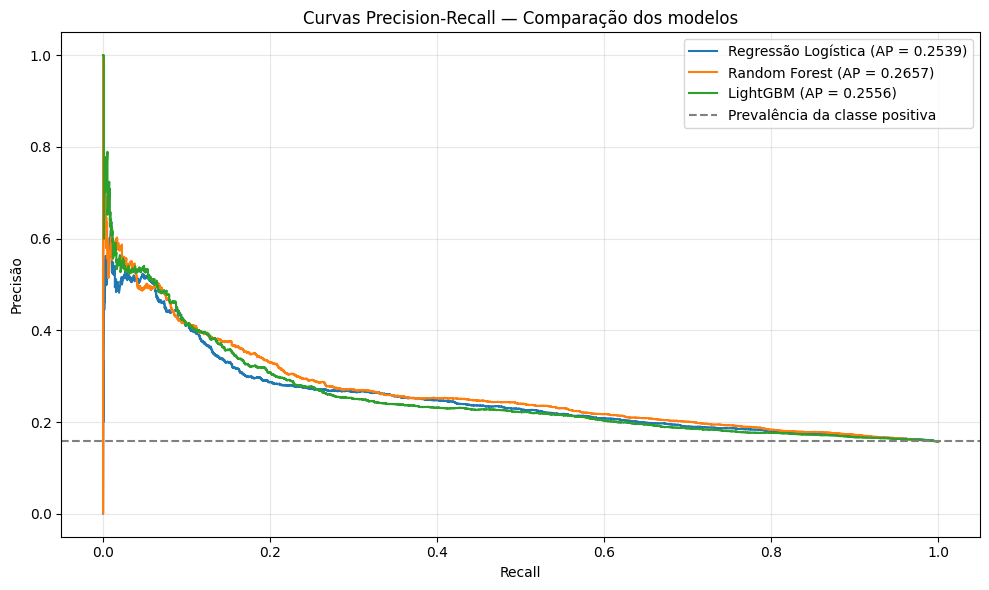

In [150]:
# 6.6.6 — Curvas Precision-Recall dos três modelos

plt.figure(figsize=(10, 6))

for name, (model, _) in models_final_comparison.items():
    y_proba = model.predict_proba(X_valid)[:, 1]

    precision, recall, _ = precision_recall_curve(y_valid, y_proba)
    ap = average_precision_score(y_valid, y_proba)

    plt.plot(recall, precision, label=f'{name} (AP = {ap:.4f})')

plt.axhline(
    y=np.asarray(y_valid).mean(),
    color='gray',
    linestyle='--',
    label='Prevalência da classe positiva'
)

plt.title('Curvas Precision-Recall — Comparação dos modelos')
plt.xlabel('Recall')
plt.ylabel('Precisão')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Conclusão da etapa 6.6.6 — Comparação gráfica das curvas Precision-Recall**

As curvas Precision-Recall complementam a comparação de limiares. A Average Precision favorece o Random Forest no conjunto de validação, sem implicar superioridade em todos os pontos da curva.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 6.6.7 — Modelo candidato para avaliação retrospectiva

O Random Forest com limiar 0,45 foi mantido como configuração histórica. A validação corrigida sustenta essa escolha pelo maior ROC-AUC, AP e F1 nos limiares comparados, além da maior precisão no Top 2.000. Nenhum ajuste foi realizado com base no teste. A avaliação não constitui teste prospectivo independente.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

## 7 — Avaliação retrospectiva do Random Forest no teste

Avaliar a configuração histórica do Random Forest (limiar 0,45) na divisão corrigida, sem reajustar o modelo a partir do teste. A versão anterior já utilizou dados deste período; portanto, esta análise não representa um teste inédito.


### 7.1 — Verificação do conjunto de teste

Inicialmente, serão verificadas as dimensões do conjunto de teste, a distribuição da variável-alvo e a consistência entre as características e os respectivos rótulos.

Essa verificação permitirá confirmar as condições da avaliação antes de gerar as previsões definitivas.

In [151]:
# 7.1 — Verificação do conjunto de teste

print('7.1 — Verificação do conjunto de teste\n')

print(f'Pedidos no teste: {len(X_test):,}')
print(f'Variáveis preditoras: {X_test.shape[1]}')
print(f'Rótulos disponíveis: {len(y_test):,}')

print('\nDistribuição da variável-alvo:')
display(
    pd.DataFrame({
        'Quantidade': pd.Series(y_test).value_counts().sort_index(),
        'Percentual (%)': pd.Series(y_test).value_counts(normalize=True).sort_index() * 100
    }).round(2)
)

print('\nVerificação de consistência:')
print(f'Dimensões compatíveis: {len(X_test) == len(y_test)}')
print(f'Classes encontradas: {sorted(pd.Series(y_test).unique().tolist())}')
print(f'Mesmas variáveis do treino: {list(X_test.columns) == list(X_train.columns)}')


7.1 — Verificação do conjunto de teste

Pedidos no teste: 18,375
Variáveis preditoras: 27
Rótulos disponíveis: 18,375

Distribuição da variável-alvo:


,Quantidade,Percentual (%)
bad_review,,
0,16397,89.24
1,1978,10.76



Verificação de consistência:
Dimensões compatíveis: True
Classes encontradas: [0, 1]
Mesmas variáveis do treino: True


**Conclusão da etapa 7.1 — Verificação do conjunto de teste**

O teste contém 18.375 pedidos, 27 features e 1.978 avaliações negativas (10,76%). As dimensões e classes são consistentes. A prevalência é inferior à da validação (15,77%).


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 7.2 — Avaliação final do Random Forest

Calcular ROC-AUC, Average Precision, acurácia, precisão, recall, F1-score e volume de alertas com o limiar histórico 0,45. Comparar com a validação, sem ajustar parâmetros pelo teste.


In [152]:
# 7.2 — Avaliação final do Random Forest no conjunto de teste

print('7.2 — Avaliação final do Random Forest\n')

threshold_final = 0.45

y_proba_test_rf = model_rf.predict_proba(X_test)[:, 1]
y_pred_test_rf = (y_proba_test_rf >= threshold_final).astype(int)

results_test_rf = {
    'ROC-AUC': roc_auc_score(y_test, y_proba_test_rf),
    'Average Precision': average_precision_score(y_test, y_proba_test_rf),
    'Acurácia': accuracy_score(y_test, y_pred_test_rf),
    'Precisão': precision_score(y_test, y_pred_test_rf, zero_division=0),
    'Recall': recall_score(y_test, y_pred_test_rf, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_test_rf, zero_division=0),
    'Alertas': int(y_pred_test_rf.sum())
}

df_test_rf = pd.DataFrame(
    results_test_rf.items(),
    columns=['Métrica', 'Resultado']
)

display(df_test_rf.round(4))


7.2 — Avaliação final do Random Forest



,Métrica,Resultado
0,ROC-AUC,0.5776
1,Average Precision,0.1747
2,Acurácia,0.6431
3,Precisão,0.1371
4,Recall,0.4373
5,F1-score,0.2087
6,Alertas,6310.0000


**Conclusão da etapa 7.2 — Avaliação final do Random Forest**

No teste retrospectivo, o Random Forest alcançou ROC-AUC de 0,5802, AP de 0,1769, acurácia de 64,40%, precisão de 14,02%, recall de 44,94% e F1 de 0,2137, com 6.341 alertas. A redução em relação à validação indica menor desempenho fora do período de desenvolvimento.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 7.3 — Matriz de confusão do Random Forest no conjunto de teste

Nesta etapa, será construída a matriz de confusão do Random Forest utilizando o conjunto de teste e o limiar de classificação de 0,45.

A análise permitirá identificar a quantidade de pedidos corretamente classificados, os alertas gerados indevidamente e as avaliações negativas não identificadas pelo modelo.

O objetivo é complementar as métricas agregadas com uma interpretação operacional dos erros de classificação, considerando os possíveis impactos para uma estratégia de atendimento preventivo.

Os resultados serão utilizados exclusivamente para diagnóstico, sem alterações no modelo ou no limiar selecionado anteriormente.

In [153]:
# 7.3 — Matriz de confusão do Random Forest no teste

print('7.3 — Matriz de confusão do Random Forest\n')

cm_test_rf = confusion_matrix(y_test, y_pred_test_rf)

df_cm_test_rf = pd.DataFrame(
    cm_test_rf,
    index=['Real: Não negativa', 'Real: Negativa'],
    columns=['Prevista: Não negativa', 'Prevista: Negativa']
)

display(df_cm_test_rf)

tn, fp, fn, tp = cm_test_rf.ravel()

print(f'Verdadeiros negativos (TN): {tn}')
print(f'Falsos positivos (FP): {fp}')
print(f'Falsos negativos (FN): {fn}')
print(f'Verdadeiros positivos (TP): {tp}')


7.3 — Matriz de confusão do Random Forest



,Prevista: Não negativa,Prevista: Negativa
Real: Não negativa,10952,5445
Real: Negativa,1113,865


Verdadeiros negativos (TN): 10952
Falsos positivos (FP): 5445
Falsos negativos (FN): 1113
Verdadeiros positivos (TP): 865


**Conclusão da etapa 7.3 — Matriz de confusão do Random Forest**

Dos 1.978 negativos, 889 foram identificados e 1.089 não detectados. Dos 16.397 não negativos, 5.452 geraram alertas indevidos e 10.945 foram corretamente classificados. O custo potencial dos falsos positivos impede recomendar intervenção indiscriminada.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 7.4 — Investigação de mudanças na distribuição dos dados

A comparação entre validação e teste permitirá verificar se houve mudança de desempenho.

Uma possível explicação é a existência de mudanças temporais na distribuição das características dos pedidos, especialmente considerando que a divisão dos dados foi realizada cronologicamente.

Nesta etapa, serão comparadas as distribuições de variáveis numéricas relevantes entre validação e teste.

O objetivo é identificar diferenças descritivas que possam contribuir para compreender a redução do desempenho preditivo.

Essa investigação não será utilizada para reajustar o modelo ou modificar os critérios de seleção previamente definidos.


In [154]:
# 7.4.1 — Comparação das variáveis numéricas entre validação e teste

print('7.4.1 — Distribuição das variáveis numéricas\n')

features_drift = [
    'estimated_delivery_days',
    'avg_distance_km',
    'total_price',
    'total_freight',
    'freight_ratio',
    'item_count'
]

drift_results = []

for feature in features_drift:
    drift_results.append({
        'Variável': feature,
        'Média validação': X_valid[feature].mean(),
        'Média teste': X_test[feature].mean(),
        'Mediana validação': X_valid[feature].median(),
        'Mediana teste': X_test[feature].median(),
        'Diferença média (%)': (
            (X_test[feature].mean() / X_valid[feature].mean() - 1) * 100
            if X_valid[feature].mean() != 0 else np.nan
        )
    })

df_drift = pd.DataFrame(drift_results).set_index('Variável')

display(df_drift.round(2))


7.4.1 — Distribuição das variáveis numéricas



,Média validação,Média teste,Mediana validação,Mediana teste,Diferença média (%)
Variável,,,,,
estimated_delivery_days,22.09,20.76,21.55,19.98,-5.99
avg_distance_km,556.90,568.54,399.74,395.15,2.09
total_price,139.84,138.70,89.10,85.99,-0.81
total_freight,22.94,24.86,18.23,18.60,8.35
freight_ratio,0.30,0.32,0.22,0.24,5.85
item_count,1.15,1.13,1.00,1.00,-1.27


**Conclusão da etapa 7.4.1 — Comparação das variáveis numéricas**

O prazo estimado médio caiu 5,99%, enquanto o frete médio aumentou 8,35% e a razão frete/preço aumentou 5,85%. A distância média cresceu 2,07%. São diferenças descritivas, não causas comprovadas da queda de desempenho.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 7.4.2 — Comparação das distribuições categóricas entre validação e teste

Nesta etapa, serão analisadas possíveis mudanças na distribuição das variáveis categóricas entre os conjuntos de validação e teste.

Serão consideradas as características `purchase_month`, `customer_state` e `main_product_category`, selecionadas para diagnóstico descritivo.

Para cada variável, serão calculadas as frequências relativas de suas categorias nos dois conjuntos, permitindo identificar diferenças na composição dos pedidos.

A análise terá caráter descritivo e diagnóstico, sem utilização dos resultados para modificar o modelo ou os parâmetros definidos anteriormente.


In [155]:
# 7.4.2 — Comparação das distribuições categóricas

print('7.4.2 — Distribuições categóricas\n')

categorical_drift_features = [
    'purchase_month',
    'customer_state',
    'main_product_category'
]

for feature in categorical_drift_features:
    valid_dist = X_valid[feature].value_counts(normalize=True, dropna=False)
    test_dist = X_test[feature].value_counts(normalize=True, dropna=False)

    df_dist = pd.DataFrame({
        'Validação (%)': valid_dist * 100,
        'Teste (%)': test_dist * 100
    }).fillna(0)

    df_dist['Diferença (p.p.)'] = (
        df_dist['Teste (%)'] - df_dist['Validação (%)']
    )

    df_dist = df_dist.reindex(
        df_dist['Diferença (p.p.)'].abs().sort_values(ascending=False).index
    )

    print(f'\nVariável: {feature}')
    print(f'Categorias identificadas: {len(df_dist)}')
    display(df_dist.head(10).round(2))


7.4.2 — Distribuições categóricas


Variável: purchase_month
Categorias identificadas: 7


,Validação (%),Teste (%),Diferença (p.p.)
purchase_month,,,
3,38.85,0.00,-38.85
4,37.15,0.00,-37.15
8,0.00,34.26,34.26
7,0.00,33.17,33.17
6,0.00,32.34,32.34
5,23.14,0.22,-22.92
2,0.86,0.00,-0.86



Variável: customer_state
Categorias identificadas: 27


,Validação (%),Teste (%),Diferença (p.p.)
customer_state,,,
SP,45.32,46.27,0.95
RJ,11.99,11.41,-0.58
RS,5.36,4.85,-0.51
MG,11.46,11.03,-0.43
DF,2.12,2.46,0.34
SC,3.47,3.21,-0.26
PE,1.44,1.69,0.25
SE,0.18,0.42,0.24
BA,3.03,3.27,0.24



Variável: main_product_category
Categorias identificadas: 73


,Validação (%),Teste (%),Diferença (p.p.)
main_product_category,,,
health_beauty,9.10,12.07,2.97
housewares,5.74,7.81,2.07
sports_leisure,8.24,6.43,-1.82
computers_accessories,7.43,5.99,-1.44
furniture_decor,6.34,5.19,-1.14
cool_stuff,2.95,1.81,-1.14
electronics,3.22,2.30,-0.92
garden_tools,3.10,2.21,-0.88
construction_tools_construction,1.00,1.75,0.75


In [156]:
# 7.4.2.1 — Diferenças nas categorias dos produtos

print('7.4.2.1 — Mudanças nas categorias dos produtos\n')

feature = 'main_product_category'

valid_dist = X_valid[feature].value_counts(normalize=True, dropna=False)
test_dist = X_test[feature].value_counts(normalize=True, dropna=False)

df_category_drift = pd.DataFrame({
    'Validação (%)': valid_dist * 100,
    'Teste (%)': test_dist * 100
}).fillna(0)

df_category_drift['Diferença (p.p.)'] = (
    df_category_drift['Teste (%)'] - df_category_drift['Validação (%)']
)

df_category_drift = df_category_drift.reindex(
    df_category_drift['Diferença (p.p.)'].abs().sort_values(ascending=False).index
)

print(df_category_drift.head(10).round(2).to_string())


7.4.2.1 — Mudanças nas categorias dos produtos

                                 Validação (%)  Teste (%)  Diferença (p.p.)
main_product_category                                                      
health_beauty                             9.10      12.07              2.97
housewares                                5.74       7.81              2.07
sports_leisure                            8.24       6.43             -1.82
computers_accessories                     7.43       5.99             -1.44
furniture_decor                           6.34       5.19             -1.14
cool_stuff                                2.95       1.81             -1.14
electronics                               3.22       2.30             -0.92
garden_tools                              3.10       2.21             -0.88
construction_tools_construction           1.00       1.75              0.75
office_furniture                          1.48       0.77             -0.71


**Conclusão da etapa 7.4.2 — Comparação das distribuições categóricas**

A distribuição do mês de compra muda conforme a divisão por aprovação, com pequena sobreposição entre períodos. Health_beauty aumenta 2,97 p.p. e housewares 2,07 p.p.; sports_leisure cai 1,82 p.p. A participação de SP cresce 0,95 p.p. Essas mudanças podem refletir composição e sazonalidade.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 7.4.3 — Evolução mensal da taxa de avaliações negativas

Nesta etapa, será analisada a proporção de avaliações negativas em cada mês dos conjuntos de validação e teste.

O objetivo é identificar possíveis mudanças temporais na distribuição da variável-alvo (`bad_review`), considerando possíveis diferenças de prevalência.

Serão calculados o número de pedidos, a quantidade de avaliações negativas e a taxa mensal de avaliações negativas.

Essa análise permitirá verificar se a redução da prevalência ocorreu de maneira gradual ou se houve alterações mais acentuadas entre os períodos.

Os resultados serão utilizados exclusivamente para diagnóstico e interpretação, sem reajuste do modelo ou do limiar de classificação.


In [157]:
# 7.4.3 — Evolução mensal das avaliações negativas

print('7.4.3 — Taxa de avaliações negativas por mês\n')

df_valid_month = pd.DataFrame({
    'approval_month': valid_sim['order_approved_at'].dt.month.to_numpy(),
    'bad_review': np.asarray(y_valid),
    'Conjunto': 'Validação'
})

df_test_month = pd.DataFrame({
    'approval_month': test_sim['order_approved_at'].dt.month.to_numpy(),
    'bad_review': np.asarray(y_test),
    'Conjunto': 'Teste'
})

df_monthly = pd.concat(
    [df_valid_month, df_test_month],
    ignore_index=True
)

df_monthly_summary = (
    df_monthly
    .groupby(['Conjunto', 'approval_month'])
    .agg(
        Pedidos=('bad_review', 'size'),
        Avaliações_negativas=('bad_review', 'sum'),
        Taxa_negativa=('bad_review', 'mean')
    )
    .reset_index()
    .sort_values('approval_month')
)

df_monthly_summary['Taxa negativa (%)'] = (
    df_monthly_summary['Taxa_negativa'] * 100
)

display(
    df_monthly_summary[
        ['Conjunto', 'approval_month', 'Pedidos',
         'Avaliações_negativas', 'Taxa negativa (%)']
    ].round(2)
)


7.4.3 — Taxa de avaliações negativas por mês



,Conjunto,approval_month,Pedidos,Avaliações_negativas,Taxa negativa (%)
3,Validação,3,7041,1601,22.74
4,Validação,4,6509,832,12.78
5,Validação,5,4364,392,8.98
0,Teste,6,5939,637,10.73
1,Teste,7,5989,654,10.92
2,Teste,8,6447,687,10.66


**Conclusão da etapa 7.4.3 — Evolução mensal das avaliações negativas**

A prevalência mensal na validação cai de 22,74% em março para 12,78% em abril e 8,98% em maio. No teste permanece próxima de 10,7% a 10,9%. A baixa taxa de maio deve ser interpretada considerando o filtro de disponibilidade de rótulos até junho, que pode selecionar avaliações rápidas.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

#### 7.4.4 — Avaliação do desempenho preditivo por mês

Nesta etapa, será analisado o desempenho do Random Forest em cada mês dos conjuntos de validação e teste.

Serão calculadas as métricas ROC-AUC e Average Precision, além da prevalência de avaliações negativas em cada período.

O objetivo é investigar possíveis variações temporais na capacidade discriminativa do modelo e verificar se uma eventual redução de desempenho no teste ocorre de maneira uniforme ou se está concentrada em determinados meses.

A análise terá caráter exclusivamente diagnóstico. Os resultados não serão utilizados para modificar o modelo, ajustar parâmetros ou selecionar novos limiares de classificação.


In [158]:
# 7.4.4 — Desempenho do Random Forest por mês

print('7.4.4 — Desempenho do Random Forest por mês\n')

y_proba_valid_rf = model_rf.predict_proba(X_valid)[:, 1]

df_valid_performance = pd.DataFrame({
    'Mês': valid_sim['order_approved_at'].dt.month.to_numpy(),
    'Real': np.asarray(y_valid),
    'Probabilidade': y_proba_valid_rf,
    'Conjunto': 'Validação'
})

df_test_performance = pd.DataFrame({
    'Mês': test_sim['order_approved_at'].dt.month.to_numpy(),
    'Real': np.asarray(y_test),
    'Probabilidade': y_proba_test_rf,
    'Conjunto': 'Teste'
})

df_month_performance = pd.concat(
    [df_valid_performance, df_test_performance],
    ignore_index=True
)

monthly_metrics = []

for (conjunto, mes), group in df_month_performance.groupby(
    ['Conjunto', 'Mês']
):
    monthly_metrics.append({
        'Conjunto': conjunto,
        'Mês': mes,
        'Pedidos': len(group),
        'Prevalência (%)': group['Real'].mean() * 100,
        'ROC-AUC': (
            roc_auc_score(group['Real'], group['Probabilidade'])
            if group['Real'].nunique() == 2 else np.nan
        ),
        'Average Precision': average_precision_score(
            group['Real'], group['Probabilidade']
        )
    })

df_monthly_metrics = (
    pd.DataFrame(monthly_metrics)
    .sort_values('Mês')
    .reset_index(drop=True)
)

display(df_monthly_metrics.round(4))


7.4.4 — Desempenho do Random Forest por mês



,Conjunto,Mês,Pedidos,Prevalência (%),ROC-AUC,Average Precision
0,Validação,3,7041,22.7382,0.6359,0.3380
1,Validação,4,6509,12.7823,0.6430,0.2453
2,Validação,5,4364,8.9826,0.6161,0.1851
3,Teste,6,5939,10.7257,0.6113,0.2008
4,Teste,7,5989,10.9200,0.5770,0.1529
5,Teste,8,6447,10.6561,0.5563,0.1832


**Conclusão da etapa 7.4.4 — Desempenho preditivo por mês**

O ROC-AUC mensal varia de 0,6382 em março a 0,6133 em maio e de 0,6109 em junho a 0,5620 em agosto. A AP no teste varia entre 0,1555 e 0,2030. Os resultados sugerem instabilidade temporal, sem estabelecer sua causa.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 7.5 — Avaliação operacional do Random Forest no conjunto de teste

Nesta etapa, será analisada a capacidade do Random Forest de priorizar pedidos com maior risco de avaliações negativas no conjunto de teste.

Serão considerados cenários hipotéticos de atendimento com capacidade para 500, 1.000, 2.000, 3.000 e 5.000 pedidos.

Em cada cenário, os pedidos serão ordenados pela probabilidade prevista de avaliação negativa, selecionando-se aqueles com os maiores escores de risco.

Serão calculadas a quantidade de avaliações negativas identificadas, a precisão, o recall e o lift em relação à prevalência geral do conjunto de teste.

Os cenários já foram utilizados anteriormente na validação e serão reaplicados ao teste exclusivamente para avaliação final, sem selecionar novos parâmetros ou ajustar o modelo.

A análise permitirá verificar se a priorização por risco apresenta utilidade potencial em diferentes capacidades operacionais.


In [159]:
# 7.5.1 — Avaliação operacional por capacidade de atendimento

print('7.5.1 — Cenários de capacidade operacional no teste\n')

capacidades = [500, 1000, 2000, 3000, 5000]

df_ranking_test = pd.DataFrame({
    'Real': np.asarray(y_test),
    'Probabilidade': y_proba_test_rf
}).sort_values('Probabilidade', ascending=False)

prevalencia_test = np.asarray(y_test).mean()
total_negativas = int(np.asarray(y_test).sum())

resultados_capacidade = []

for capacidade in capacidades:
    selecionados = df_ranking_test.head(capacidade)
    tp = int(selecionados['Real'].sum())
    precisao = tp / len(selecionados)
    recall = tp / total_negativas
    lift = precisao / prevalencia_test

    resultados_capacidade.append({
        'Capacidade': capacidade,
        'Negativas identificadas': tp,
        'Precisão': precisao,
        'Recall': recall,
        'Lift': lift
    })

df_capacidade_test = pd.DataFrame(resultados_capacidade)

display(df_capacidade_test.round(4))


7.5.1 — Cenários de capacidade operacional no teste



,Capacidade,Negativas identificadas,Precisão,Recall,Lift
0,500,165,0.3300,0.0834,3.0656
1,1000,293,0.2930,0.1481,2.7219
2,2000,437,0.2185,0.2209,2.0298
3,3000,555,0.1850,0.2806,1.7186
4,5000,751,0.1502,0.3797,1.3953


### 7.5.2 — Comparação da capacidade operacional entre validação e teste

Nesta etapa, serão comparados os resultados de priorização de pedidos obtidos pelo Random Forest nos conjuntos de validação e teste.

Serão considerados os mesmos cenários de capacidade operacional: 500, 1.000, 2.000, 3.000 e 5.000 pedidos.

A comparação utilizará precisão, recall e lift, permitindo avaliar a estabilidade da capacidade de priorização do modelo em períodos distintos.

O lift será especialmente relevante, pois considera a prevalência de avaliações negativas de cada conjunto, facilitando a interpretação dos resultados diante das diferenças na distribuição da variável-alvo.

A análise terá caráter exclusivamente avaliativo, sem ajustes no modelo ou nos critérios definidos durante a validação.

In [160]:
# 7.5.2 — Comparação operacional entre validação e teste

print('7.5.2 — Comparação operacional: validação × teste\n')

capacidades = [500, 1000, 2000, 3000, 5000]

df_ranking_valid = pd.DataFrame({
    'Real': np.asarray(y_valid),
    'Probabilidade': y_proba_valid_rf
}).sort_values('Probabilidade', ascending=False)

prevalencia_valid = np.asarray(y_valid).mean()
total_negativas_valid = int(np.asarray(y_valid).sum())

comparacao_operacional = []

for capacidade in capacidades:
    selecionados_valid = df_ranking_valid.head(capacidade)
    selecionados_test = df_ranking_test.head(capacidade)

    tp_valid = int(selecionados_valid['Real'].sum())
    tp_test = int(selecionados_test['Real'].sum())

    precisao_valid = tp_valid / capacidade
    precisao_test = tp_test / capacidade

    comparacao_operacional.append({
        'Capacidade': capacidade,
        'Precisão validação': precisao_valid,
        'Precisão teste': precisao_test,
        'Recall validação': tp_valid / total_negativas_valid,
        'Recall teste': tp_test / total_negativas,
        'Lift validação': precisao_valid / prevalencia_valid,
        'Lift teste': precisao_test / prevalencia_test
    })

df_comparacao_operacional = pd.DataFrame(comparacao_operacional)

display(df_comparacao_operacional.round(4))


7.5.2 — Comparação operacional: validação × teste



,Capacidade,Precisão validação,Precisão teste,Recall validação,Recall teste,Lift validação,Lift teste
0,500,0.4580,0.3300,0.0811,0.0834,2.9043,3.0656
1,1000,0.3810,0.2930,0.1349,0.1481,2.4160,2.7219
2,2000,0.3080,0.2185,0.2181,0.2209,1.9531,2.0298
3,3000,0.2710,0.1850,0.2878,0.2806,1.7185,1.7186
4,5000,0.2482,0.1502,0.4393,0.3797,1.5739,1.3953


**Conclusão da etapa 7.5.2 — Comparação operacional entre validação e teste**

No Top 2.000, a precisão cai de 30,95% para 22,45%, enquanto o lift sobe de 1,9626 para 2,0855 e o recall de 21,91% para 22,70%. No teste são 449 negativos identificados contra cerca de 215 esperados aleatoriamente. O Top 500 apresenta lift de 3,0470, mas cobertura de apenas 8,29%. A capacidade ideal depende dos custos e benefícios.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

### 7.6 — Síntese final da avaliação do Random Forest

Esta etapa consolida os principais resultados do Random Forest nos conjuntos de validação e teste.

Serão apresentados os indicadores de desempenho preditivo, a prevalência de avaliações negativas e os resultados operacionais para a capacidade de 2.000 alertas.

O objetivo é reunir as principais evidências para a conclusão técnica do projeto, destacando eventuais limitações de generalização temporal e o potencial de priorização de pedidos com maior risco de avaliações negativas.

A consolidação será utilizada para fundamentar as recomendações de negócio e a discussão das limitações do modelo, sem realizar novos ajustes ou treinamentos.


In [161]:
# 7.6.1 — Consolidação dos resultados finais

print('7.6.1 — Síntese final do Random Forest\n')

df_resumo_final = pd.DataFrame({
    'Indicador': [
        'Pedidos avaliados',
        'Prevalência negativa (%)',
        'ROC-AUC',
        'Average Precision',
        'Precisão (limiar 0.45)',
        'Recall (limiar 0.45)',
        'F1-score (limiar 0.45)',
        'Alertas (limiar 0.45)',
        'Precisão Top 2000',
        'Recall Top 2000',
        'Lift Top 2000'
    ],
    'Validação': [
        len(y_valid),
        np.asarray(y_valid).mean() * 100,
        roc_auc_score(y_valid, y_proba_valid_rf),
        average_precision_score(y_valid, y_proba_valid_rf),
        precision_score(
            y_valid, (y_proba_valid_rf >= 0.45).astype(int),
            zero_division=0
        ),
        recall_score(
            y_valid, (y_proba_valid_rf >= 0.45).astype(int),
            zero_division=0
        ),
        f1_score(
            y_valid, (y_proba_valid_rf >= 0.45).astype(int),
            zero_division=0
        ),
        int((y_proba_valid_rf >= 0.45).sum()),
        df_comparacao_operacional.loc[2, 'Precisão validação'],
        df_comparacao_operacional.loc[2, 'Recall validação'],
        df_comparacao_operacional.loc[2, 'Lift validação']
    ],
    'Teste': [
        len(y_test),
        np.asarray(y_test).mean() * 100,
        results_test_rf['ROC-AUC'],
        results_test_rf['Average Precision'],
        results_test_rf['Precisão'],
        results_test_rf['Recall'],
        results_test_rf['F1-score'],
        results_test_rf['Alertas'],
        df_comparacao_operacional.loc[2, 'Precisão teste'],
        df_comparacao_operacional.loc[2, 'Recall teste'],
        df_comparacao_operacional.loc[2, 'Lift teste']
    ]
})

display(df_resumo_final.round(4))


7.6.1 — Síntese final do Random Forest



,Indicador,Validação,Teste
0,Pedidos avaliados,17914.0000,18375.0000
1,Prevalência negativa (%),15.7698,10.7646
2,ROC-AUC,0.6341,0.5776
3,Average Precision,0.2657,0.1747
4,Precisão (limiar 0.45),0.2274,0.1371
5,Recall (limiar 0.45),0.5575,0.4373
6,F1-score (limiar 0.45),0.3230,0.2087
7,Alertas (limiar 0.45),6926.0000,6310.0000
8,Precisão Top 2000,0.3080,0.2185
9,Recall Top 2000,0.2181,0.2209


### 7.6.2 — Conclusão da avaliação final do modelo

O Random Forest preserva capacidade de priorização acima do acaso, apesar da redução de ROC-AUC (0,6342 para 0,5802), AP (0,2664 para 0,1769) e F1 (0,3210 para 0,2137). O Top 2.000 mantém lift superior a 1,9 nos dois períodos. A evidência é retrospectiva e insuficiente para recomendar implantação direta.


> Nota de revisão: valores numéricos e comparações desta interpretação referem-se à execução anterior à limpeza estadual. Os resultados vigentes são os outputs recalculados; não utilizar os números históricos como métricas finais.

## 8 — Inteligência de negócio
### 8.1 — Simulação econômica
Cenários hipotéticos, usando o ranking retrospectivo do Random Forest de referência. A eficácia e o custo unitário não são observados no Olist. O benefício é incremental contra nenhuma intervenção; não é lucro realizado.

In [162]:
# 8.1 — Cenários de impacto financeiro
k = 2000
rank = np.argsort(-np.asarray(y_proba_test_rf), kind='stable')[:k]
tp = int(np.asarray(y_test)[rank].sum())
def impacto(k, tp, custo, perda, eficacia):
    evitadas = tp * eficacia
    return {'Alertas': k, 'Negativas identificadas': tp, 'Evitadas esperadas': evitadas,
            'Custo (R$)': k*custo, 'Benefício (R$)': evitadas*perda,
            'Saldo (R$)': evitadas*perda-k*custo,
            'Eficácia de equilíbrio': k*custo/(tp*perda) if tp*perda else np.nan}
df_impacto = pd.DataFrame([dict(Cenário=nome, **impacto(k,tp,c,p,e)) for nome,c,p,e in
    [('Conservador',5,50,.10),('Central',3,100,.25),('Otimista',2,150,.40)]])
display(df_impacto)

,Cenário,Alertas,Negativas identificadas,Evitadas esperadas,Custo (R$),Benefício (R$),Saldo (R$),Eficácia de equilíbrio
0,Conservador,2000,437,43.70,10000,2185.0,-7815.0,0.457666
1,Central,2000,437,109.25,6000,10925.0,4925.0,0.137300
2,Otimista,2000,437,174.80,4000,26220.0,22220.0,0.061022


### 8.2 — Planejamento do teste A/B
População: pedidos elegíveis sinalizados por um modelo congelado em lotes operacionais prospectivos. Randomizar por cliente, mantendo todos os pedidos do mesmo cliente no mesmo braço; estratificar por faixa de risco e região quando viável. Controle: atendimento habitual. Tratamento: contato proativo e acompanhamento logístico, sem retirar serviços existentes. Métrica primária: proporção de clientes cujo primeiro pedido elegível recebe nota 1–2 em até 60 dias da aprovação. Monitorar ausência de avaliação separadamente e realizar análise de sensibilidade; não assumir que ausência significa satisfação. Análise por intenção de tratar, diferença absoluta de proporções e IC 95%. Métricas secundárias: custo, reclamações, cancelamentos e taxa de resposta. Fixar amostra, janela de maturação e regra de parada antes do início. Não interromper por significância intermediária. Aprovar expansão apenas se benefício econômico e segurança operacional forem sustentados. O teste não foi realizado.

O cálculo abaixo é ilustrativo, para um pedido por cliente, com proporções hipotéticas e grupos de mesmo tamanho; ajustar com piloto, perdas de seguimento e desenho definitivo.

In [163]:
# 8.2.1 — Dimensionamento ilustrativo do experimento
p0, p1 = .22, .18
pbar = (p0+p1)/2
n_arm = int(np.ceil((norm.ppf(.975)*np.sqrt(2*pbar*(1-pbar)) + norm.ppf(.80)*np.sqrt(p0*(1-p0)+p1*(1-p1)))**2/(p0-p1)**2))
print(f'Clientes por braço: {n_arm:,}; total: {2*n_arm:,}')

Clientes por braço: 1,569; total: 3,138


## 9 — Otimização com Optuna
### 9.1 — Protocolo
O Random Forest de referência foi escolhido na validação. Otimizar AP somente na validação, com 20 tentativas e seed fixa. A reutilização da validação pode gerar otimismo; o teste histórico já foi consultado e não é independente. Não usar teste na seleção. Manter o candidato original se a AP otimizada não superar a referência.

In [164]:
# 9.1 — Otimização de hiperparâmetros
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    params = dict(n_estimators=trial.suggest_int('n_estimators',100,300,step=100),
                  max_depth=trial.suggest_int('max_depth',4,18),
                  min_samples_leaf=trial.suggest_int('min_samples_leaf',5,40),
                  max_features=trial.suggest_categorical('max_features',['sqrt',0.3,0.6]),
                  class_weight=trial.suggest_categorical('class_weight',[None,'balanced']))
    candidate = Pipeline([('preprocessor',clone(preprocessor)),('classifier',RandomForestClassifier(**params,random_state=42,n_jobs=-1))])
    candidate.fit(X_train,y_train)
    return average_precision_score(y_valid,candidate.predict_proba(X_valid)[:,1])
study = optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective,n_trials=20)
display(study.trials_dataframe())
print(study.best_params, study.best_value)

,number,value,datetime_start,datetime_complete,duration,params_class_weight,params_max_depth,params_max_features,params_min_samples_leaf,params_n_estimators,system_attrs_tpe:relative_params:0,state
0,0,0.266639,2026-11-25 12:41:02.071381,2026-11-25 12:41:43.075589,0 days 00:00:41.004208,balanced,18,sqrt,31,200,NaN,COMPLETE
1,1,0.267468,2026-11-25 12:41:43.075728,2026-11-25 12:42:18.273425,0 days 00:00:35.197697,balanced,14,sqrt,5,200,NaN,COMPLETE
2,2,0.258306,2026-11-25 12:42:18.273521,2026-11-25 12:42:54.115853,0 days 00:00:35.842332,balanced,11,0.3,20,100,NaN,COMPLETE
3,3,0.253858,2026-11-25 12:42:54.115927,2026-11-25 12:44:42.316257,0 days 00:01:48.200330,None,15,0.3,12,200,NaN,COMPLETE
4,4,0.265804,2026-11-25 12:44:42.316377,2026-11-25 12:45:00.171277,0 days 00:00:17.854900,None,18,sqrt,39,100,NaN,COMPLETE
5,5,0.268182,2026-11-25 12:45:00.171349,2026-11-25 12:45:12.599650,0 days 00:00:12.428301,balanced,11,sqrt,6,100,NaN,COMPLETE
6,6,0.262192,2026-11-25 12:45:12.599720,2026-11-25 12:45:40.359673,0 days 00:00:27.759953,balanced,6,0.3,39,200,NaN,COMPLETE
7,7,0.260136,2026-11-25 12:45:40.359769,2026-11-25 12:45:53.696787,0 days 00:00:13.337018,None,6,0.3,6,100,NaN,COMPLETE
8,8,0.251337,2026-11-25 12:45:53.696886,2026-11-25 12:47:07.872764,0 days 00:01:14.175878,None,12,0.6,10,100,NaN,COMPLETE
9,9,0.255131,2026-11-25 12:47:07.872845,2026-11-25 12:48:00.020197,0 days 00:00:52.147352,None,16,0.3,30,100,NaN,COMPLETE


{'n_estimators': 300, 'max_depth': 18, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced'} 0.27076810533451323


In [165]:
# 9.2 — Seleção do candidato e limiar na validação
optimized = Pipeline([('preprocessor',clone(preprocessor)),('classifier',RandomForestClassifier(**study.best_params,random_state=42,n_jobs=-1))])
optimized.fit(X_train,y_train)
ap_ref = average_precision_score(y_valid,model_rf.predict_proba(X_valid)[:,1])
ap_opt = average_precision_score(y_valid,optimized.predict_proba(X_valid)[:,1])
final_model = optimized if ap_opt > ap_ref else model_rf
pv = final_model.predict_proba(X_valid)[:,1]
threshold_grid = np.arange(.05,.96,.05)
final_threshold = float(max(threshold_grid,key=lambda t:f1_score(y_valid,pv>=t,zero_division=0)))
print('AP referência:',ap_ref,'AP otimizada:',ap_opt,'Limiar:',final_threshold)
print('Selecionado:', 'Otimizado' if final_model is optimized else 'Referência')

AP referência: 0.2657141269168076 AP otimizada: 0.27076810533451323 Limiar: 0.45
Selecionado: Otimizado


In [166]:
# 9.3 — Avaliação retrospectiva após congelamento
pt = final_model.predict_proba(X_test)[:,1]
def metrics(y,p,t):
    pred = p>=t
    return dict(AP=average_precision_score(y,p),ROC_AUC=roc_auc_score(y,p),Accuracy=accuracy_score(y,pred),Precision=precision_score(y,pred,zero_division=0),Recall=recall_score(y,pred,zero_division=0),F1=f1_score(y,pred,zero_division=0))
df_final_metrics = pd.DataFrame([metrics(y_valid,pv,final_threshold),metrics(y_test,pt,final_threshold)],index=['Validação','Teste retrospectivo'])
display(df_final_metrics)

,AP,ROC_AUC,Accuracy,Precision,Recall,F1
Validação,0.270768,0.635966,0.713688,0.256448,0.429381,0.321112
Teste retrospectivo,0.180613,0.584764,0.753524,0.169987,0.332154,0.224884


## 10 — Explicabilidade com SHAP
Amostra de validação de até 500 pedidos. Explicações descrevem o comportamento do modelo, não causas. Agregar contribuições assinadas das categorias codificadas antes de calcular a magnitude média por variável original.

,SHAP médio absoluto
item_count,0.020206
total_freight,0.018078
estimated_delivery_days,0.014192


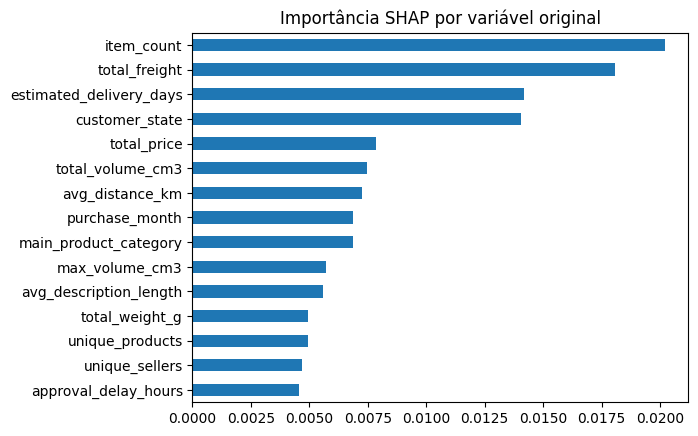

In [167]:
# 10.1 — SHAP e três variáveis mais relevantes
prep = final_model.named_steps['preprocessor']
forest = final_model.named_steps['classifier']
xs = X_valid.sample(min(500,len(X_valid)),random_state=42)
z = prep.transform(xs)
if hasattr(z,'toarray'): z=z.toarray()
explainer = shap.TreeExplainer(forest)
sv = explainer.shap_values(z)
if isinstance(sv,list): sv=sv[1]
else:
    sv=np.asarray(sv)
    if sv.ndim==3: sv=sv[:,:,1]
names = prep.get_feature_names_out()
assert sv.shape == (len(xs),len(names))
groups = {}
for i,name in enumerate(names):
    raw = name.split('__',1)[-1]
    matches = [f for f in X_train.columns if raw==f or raw.startswith(f+'_')]
    assert matches, name
    groups.setdefault(max(matches,key=len),[]).append(i)
shap_group = pd.Series({f:np.abs(sv[:,ix].sum(axis=1)).mean() for f,ix in groups.items()}).sort_values(ascending=False)
display(shap_group.head(3).to_frame('SHAP médio absoluto'))
shap_group.head(15).sort_values().plot.barh(title='Importância SHAP por variável original'); plt.show()

## 11 — IA responsável
Comparar taxas de alerta, falsos positivos e verdadeiros positivos por estado e categoria. Grupos pequenos ou sem ambas as classes não permitem estimativas estáveis. Diferenças não demonstram discriminação causal; não há gênero disponível. A avaliação é descritiva e retrospectiva, sem ajuste por fatores de confusão.

In [168]:
# 11.1 — Diagnóstico de disparidades
rows=[]
for feature in ['customer_state','main_product_category']:
    audit=pd.DataFrame({'group':X_test[feature].fillna('Ausente').astype(str).to_numpy(),'y':np.asarray(y_test),'alert':pt>=final_threshold})
    for group,g in audit.groupby('group'):
        pos=g.y==1; neg=~pos
        if len(g)<100 or pos.sum()<20 or neg.sum()<20: continue
        rows.append({'Feature':feature,'Grupo':group,'N':len(g),'Positivos':int(pos.sum()),'Prevalência':pos.mean(),'Taxa alerta':g.alert.mean(),'TPR':g.loc[pos,'alert'].mean(),'FPR':g.loc[neg,'alert'].mean()})
df_bias=pd.DataFrame(rows)
display(df_bias)
if not df_bias.empty:
    display(df_bias.groupby('Feature')[['TPR','FPR','Taxa alerta']].agg(['min','max']))

,Feature,Grupo,N,Positivos,Prevalência,Taxa alerta,TPR,FPR
0,customer_state,BA,600,70,0.116667,0.448333,0.457143,0.447170
1,customer_state,CE,213,20,0.093897,0.464789,0.400000,0.471503
2,customer_state,DF,452,48,0.106195,0.132743,0.229167,0.121287
3,customer_state,ES,343,38,0.110787,0.113703,0.289474,0.091803
4,customer_state,GO,328,38,0.115854,0.210366,0.263158,0.203448
5,customer_state,MA,110,21,0.190909,0.527273,0.428571,0.550562
6,customer_state,MG,2026,202,0.099704,0.133268,0.297030,0.115132
7,customer_state,PE,311,32,0.102894,0.459807,0.562500,0.448029
8,customer_state,PR,934,88,0.094218,0.124197,0.250000,0.111111
9,customer_state,RJ,2097,265,0.126371,0.412971,0.513208,0.398472


TPR                 FPR           Taxa alerta  \
                            min       max       min       max         min   
Feature                                                                     
customer_state         0.229167  0.562500  0.091803  0.550562    0.113703   
main_product_category  0.178571  0.857143  0.116402  0.561404    0.130398   

                                 
                            max  
Feature                          
customer_state         0.527273  
main_product_category  0.619718

## 12 — Síntese da Entrega 2
Resultados recalculados após a revisão geográfica. A avaliação é retrospectiva; não comprova impacto causal ou viabilidade de implantação.

In [169]:
# 12.1 — Resumo atualizado
print('Modelo:', 'Random Forest otimizado' if final_model is optimized else 'Random Forest de referência')
print('Limiar:', final_threshold)
display(df_final_metrics)
display(shap_group.head(3).to_frame('SHAP médio absoluto'))
display(df_impacto)

Modelo: Random Forest otimizado
Limiar: 0.45


,AP,ROC_AUC,Accuracy,Precision,Recall,F1
Validação,0.270768,0.635966,0.713688,0.256448,0.429381,0.321112
Teste retrospectivo,0.180613,0.584764,0.753524,0.169987,0.332154,0.224884


,SHAP médio absoluto
item_count,0.020206
total_freight,0.018078
estimated_delivery_days,0.014192


,Cenário,Alertas,Negativas identificadas,Evitadas esperadas,Custo (R$),Benefício (R$),Saldo (R$),Eficácia de equilíbrio
0,Conservador,2000,437,43.70,10000,2185.0,-7815.0,0.457666
1,Central,2000,437,109.25,6000,10925.0,4925.0,0.137300
2,Otimista,2000,437,174.80,4000,26220.0,22220.0,0.061022
